# Diabetes Prediction on the Pima Indians Data: AID427 Phase 1

**Notebook contract.** Every number in this notebook comes from a clean top-to-bottom run. The data audit runs before any model is scored. The 20% test set is locked away before model selection and opened exactly once, in Section 12.

| § | Content | Rubric item |
|---|---|---|
| 0 | Problem introduction, pre-specified protocol | Problem introduction |
| 1 | Data provenance, schema, version audit, leakage checks | Data sets description |
| 2 | Locked split, shared folds, in-fold preprocessing, EDA before/after preprocessing | Preprocessing, data analysis |
| 3 | Seven classifiers on all 8 features, 5-fold accuracy | Model implementations, K-fold CV |
| 4 | PCA, LDA, SVD | Linear feature reduction |
| 5 | Custom SNE verification; 11-method embedding comparison (trustworthiness, runtime, plots) | Non-linear feature reduction, visualization |
| 6 | K-means clustering without labels, before/after plots | Visualization after clustering |
| 7 | Filter (mutual information), wrappers (forward, backward, RFECV), embedded (L1, L2, Elastic Net) | Feature selection |
| 8 | GA vs binary PSO vs random search vs exhaustive optimum | GA and other metaheuristics |
| 9 | Prediction comparison: all 8 features vs linear vs nonlinear reduction vs selected features, 7 classifiers | Comparisons |
| 10 | Nested hyperparameter tuning | Model implementations |
| 11 | Leaderboard, finalist and threshold locked on development data | Model selection |
| 12 | Test set opened once: confusion matrix, all metrics, error analysis, over/underfitting | Evaluation, interpretation |
| 13 | Related work table | Comparison with related work |
| 14 | Reconciliation with the historical notebook | n/a |
| 15 | Rubric checklist | n/a |

## 0. Problem introduction and pre-specified protocol

**Problem.** Type 2 diabetes is common in the Akimel O'odham (Pima) community of Arizona. The NIDDK longitudinal study recorded eight routine measurements for 768 women aged 21 or older. The task is to predict a positive diabetes test under WHO criteria from those measurements. This is a binary screening problem. In screening, a missed diabetic (false negative) usually costs more than a false alarm.

**Why the dataset is difficult and noisy.** Five measurements use `0` as a hidden missing-value code: glucose, blood pressure, skin fold, insulin and BMI. Insulin is zero for 48.7% of patients. The classes are imbalanced (35% positive), the sample is small, and the classes overlap heavily (see Sections 5 and 6).

**Protocol, fixed before any model was scored:**

1. **Data.** One verified raw copy of the 768 patients is used (Section 1). Alternate copies are never stacked as extra patients.
2. **Split.** A stratified 20% test set (154 patients) is held out with `random_state=42` and kept locked until Section 12.
3. **Folds.** All comparable experiments use the same 5 stratified folds of the remaining 614 development patients (`OUTER_FOLDS`). Any tuning or supervised subset search runs on inner 5-fold CV inside each outer training fold (`inner_cv()`, seed 7).
4. **Leakage control.** Zero-to-missing recoding, scaling, KNN imputation, feature selection and dimensionality reduction are all fitted on the training part of each fold only.
5. **Primary ranking metric.** Mean outer 5-fold **ROC-AUC**. It does not depend on a threshold, which suits screening. **Mean 5-fold accuracy** is reported alongside it everywhere, as the rubric asks.
6. **Finalist rule.** The highest mean outer-CV ROC-AUC on the development folds wins. Ties within 0.001 go to the pipeline needing fewer raw measurements, then to the simpler model.
7. **Screening-threshold rule.** Take the highest threshold whose out-of-fold recall on the development data is at least 0.85. This is fixed before the test set is opened. The default 0.5 threshold is also reported.
8. **Parsimony unit.** A feature must earn at least 0.002 inner-CV AUC to be kept. This is the forward/backward stopping tolerance, the mutual-information k rule and the metaheuristic per-feature penalty.

In [1]:
import os, time, hashlib, itertools, warnings, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
from scipy.spatial.distance import pdist, squareform
from joblib import Parallel, delayed

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, learning_curve
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, roc_curve, adjusted_rand_score,
                             normalized_mutual_info_score, silhouette_score)
from sklearn.decomposition import PCA, TruncatedSVD, KernelPCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.manifold import TSNE, MDS, Isomap, LocallyLinearEmbedding, trustworthiness
from sklearn.feature_selection import (SequentialFeatureSelector, RFECV, SelectFromModel,
                                       mutual_info_classif, f_classif)
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.cluster import KMeans
warnings.filterwarnings('ignore', message='IProgress not found')          # tqdm notice triggered by umap import
warnings.filterwarnings('ignore', message='The `probability` parameter was deprecated')  # sklearn 1.9 SVC notice; behaviour unchanged in the pinned version
import umap

SEED = 42          # split, outer folds, models
INNER_SEED = 7     # inner CV used for tuning / supervised subset searches
N_JOBS = max(1, (os.cpu_count() or 2) - 2)
NOTEBOOK_T0 = time.perf_counter()

DATA = Path('data'); PROVENANCE = DATA / 'provenance'
RESULTS = Path('results'); RESULTS.mkdir(exist_ok=True)

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)
pd.set_option('display.precision', 4); pd.set_option('display.max_colwidth', 80)
warnings.filterwarnings('ignore', message='n_jobs value .* overridden')   # UMAP + random_state notice

print('Python', platform.python_version(), '|', platform.platform())
for m in (np, pd, sklearn, scipy, matplotlib, sns, umap):
    print(f'{m.__name__:12s}', m.__version__)
print('parallel workers:', N_JOBS)

Python 3.13.9 | Windows-11-10.0.26300-SP0
numpy        2.3.5
pandas       3.1.1
sklearn      1.9.1
scipy        1.18.1
matplotlib   3.11.2
seaborn      0.13.2
umap         0.6.0
parallel workers: 18


## 1. Data sets: provenance, schema and version audit

### 1.1 Raw data: provenance check

The old notebook read two files, `diabetes.csv` and `pima_indians_diabetes.csv`. Neither was in the project folder when this audit ran. The raw file was therefore re-obtained from a verifiable public source and stored in `data/provenance/`:

| File | Source | Check |
|---|---|---|
| `dataset_37_diabetes.arff` | OpenML dataset 37 "diabetes" v1, https://www.openml.org/d/37, file `https://www.openml.org/data/download/37/dataset_37_diabetes.arff` | MD5 must equal the checksum OpenML publishes in `https://www.openml.org/api/v1/json/data/37` (copy saved as `openml_37_meta.json`) |
| `jbrownlee_pima.csv` | Independent mirror of the UCI file `pima-indians-diabetes.data` (https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv) | Must match the ARFF row by row |
| `duke_pima.info` | UCI documentation `pima.info` (https://www2.stat.duke.edu/courses/Fall00/sta290/datasets/pima.info) | Documents 768 instances, 500/268 classes, Smith et al. 1988 |
| `data/pima_indians_diabetes.csv` | CSV export of the ARFF, with the same column names (`preg … class`) the old notebook expected | Must equal the ARFF |

All four were downloaded on 2026-11-23.

In [2]:
OPENML_PUBLISHED_MD5 = '3cbaa3e54586aa88cf6aacb4033e4470'   # md5_checksum field of OpenML data id 37

def read_arff(path):
    lines = Path(path).read_text(encoding='utf-8').splitlines()
    attrs, start = [], None
    for i, line in enumerate(lines):
        s = line.strip()
        if s.lower().startswith('@attribute'):
            attrs.append(s.split()[1].strip("'"))
        if s.lower() == '@data':
            start = i + 1
            break
    rows = [l.strip().split(',') for l in lines[start:] if l.strip() and not l.startswith('%')]
    df = pd.DataFrame(rows, columns=attrs)
    for c in attrs[:-1]:
        df[c] = df[c].astype(float)
    df[attrs[-1]] = df[attrs[-1]].str.strip()
    return df

arff_path = PROVENANCE / 'dataset_37_diabetes.arff'
arff_md5 = hashlib.md5(arff_path.read_bytes()).hexdigest()
arff_df = read_arff(arff_path)
csv_df = pd.read_csv(DATA / 'pima_indians_diabetes.csv')
mirror = pd.read_csv(PROVENANCE / 'jbrownlee_pima.csv', header=None)

num_cols = list(arff_df.columns[:-1])
mirror_y = arff_df['class'].map({'tested_negative': 0, 'tested_positive': 1}).to_numpy()
provenance_checks = pd.DataFrame([
    ('ARFF MD5 equals OpenML published checksum', arff_md5 == OPENML_PUBLISHED_MD5, arff_md5),
    ('pima_indians_diabetes.csv equals ARFF (values + labels)',
     bool(np.allclose(csv_df[num_cols].to_numpy(), arff_df[num_cols].to_numpy()) and (csv_df['class'] == arff_df['class']).all()), ''),
    ('Independent UCI mirror equals ARFF row by row',
     bool(np.allclose(mirror.iloc[:, :8].to_numpy(), arff_df[num_cols].to_numpy()) and (mirror.iloc[:, 8].to_numpy() == mirror_y).all()), ''),
    ('Row count is 768', len(csv_df) == 768, len(csv_df)),
    ('Class counts are 500 negative / 268 positive (pima.info)',
     csv_df['class'].value_counts().to_dict() == {'tested_negative': 500, 'tested_positive': 268},
     csv_df['class'].value_counts().to_dict()),
    ('No exact duplicate rows', int(csv_df.duplicated().sum()) == 0, int(csv_df.duplicated().sum())),
], columns=['check', 'passed', 'detail'])
display(provenance_checks)
assert provenance_checks['passed'].all(), 'Provenance check failed: stop and investigate before modelling.'

,check,passed,detail
0,ARFF MD5 equals OpenML published checksum,True,3cbaa3e54586aa88cf6aacb4033e4470
1,pima_indians_diabetes.csv equals ARFF (values + labels),True,
2,Independent UCI mirror equals ARFF row by row,True,
3,Row count is 768,True,768
4,Class counts are 500 negative / 268 positive (pima.info),True,"{'tested_negative': 500, 'tested_positive': 268}"
5,No exact duplicate rows,True,0


In [3]:
RENAME = {'preg': 'Pregnancies', 'plas': 'Glucose', 'pres': 'BloodPressure', 'skin': 'SkinThickness',
          'insu': 'Insulin', 'mass': 'BMI', 'pedi': 'DiabetesPedigreeFunction', 'age': 'Age', 'class': 'Outcome'}
FEATURES = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI',
            'DiabetesPedigreeFunction', 'Age']
ZERO_INVALID = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']   # 0 is physiologically impossible

df_raw = csv_df.rename(columns=RENAME)
df_raw['Outcome'] = df_raw['Outcome'].map({'tested_negative': 0, 'tested_positive': 1}).astype(int)

meaning = {'Pregnancies': ('Number of times pregnant', 'count'),
           'Glucose': ('Plasma glucose, 2 h oral glucose tolerance test', 'mg/dL'),
           'BloodPressure': ('Diastolic blood pressure', 'mm Hg'),
           'SkinThickness': ('Triceps skin-fold thickness', 'mm'),
           'Insulin': ('2-hour serum insulin', 'muU/mL'),
           'BMI': ('Body-mass index', 'kg/m^2'),
           'DiabetesPedigreeFunction': ('Family-history risk score', 'index'),
           'Age': ('Age', 'years'),
           'Outcome': ('Diabetes by WHO criteria (target)', '0/1')}
schema = pd.DataFrame({
    'meaning': [meaning[c][0] for c in df_raw.columns],
    'unit': [meaning[c][1] for c in df_raw.columns],
    'dtype': df_raw.dtypes.astype(str).values,
    'min': df_raw.min().values, 'max': df_raw.max().values,
    'n_zero': (df_raw == 0).sum().values,
    'zero_is_invalid': [c in ZERO_INVALID for c in df_raw.columns],
}, index=df_raw.columns)
display(schema)

,meaning,unit,dtype,min,max,n_zero,zero_is_invalid
Pregnancies,Number of times pregnant,count,float64,0.000,17.00,111,False
Glucose,"Plasma glucose, 2 h oral glucose tolerance test",mg/dL,float64,0.000,199.00,5,True
BloodPressure,Diastolic blood pressure,mm Hg,float64,0.000,122.00,35,True
SkinThickness,Triceps skin-fold thickness,mm,float64,0.000,99.00,227,True
Insulin,2-hour serum insulin,muU/mL,float64,0.000,846.00,374,True
BMI,Body-mass index,kg/m^2,float64,0.000,67.10,11,True
DiabetesPedigreeFunction,Family-history risk score,index,float64,0.078,2.42,0,False
Age,Age,years,float64,21.000,81.00,0,False
Outcome,Diabetes by WHO criteria (target),0/1,int64,0.000,1.00,500,False


### 1.2 Are the two files versions of the same 768 patients, and does the "clean" file leak the label?

The old notebook stacked `diabetes.csv` (a "pre-cleaned" variant) on the raw file and got 1,536 rows, 1,144 after removing exact duplicates. The documentation suspected that the clean file had its zeros filled with **class-conditional medians**, meaning medians computed separately for diabetic and non-diabetic patients. If so, the filled values encode the outcome.

The cell below uses a local `diabetes.csv` if one exists. **None was found in this audit**, so it rebuilds the hypothesised variant from the raw file: each invalid zero is replaced by the median of the non-zero values *of the same Outcome class*. The test of the hypothesis is whether this rebuild reproduces the statistics the old notebook printed (row count and every column count and mean in its `df.describe()` output).

In [4]:
def reconstruct_class_median_variant(raw):
    clean, medians = raw.copy(), {}
    for c in ZERO_INVALID:
        for k in (0, 1):
            m = raw.loc[(raw['Outcome'] == k) & (raw[c] != 0), c].median()
            medians[(c, k)] = m
            clean.loc[(clean['Outcome'] == k) & (clean[c] == 0), c] = m
    return clean, medians

local_clean = [p for p in (Path('diabetes.csv'), DATA / 'diabetes.csv') if p.exists()]
if local_clean:
    df_clean = pd.read_csv(local_clean[0])
    CLEAN_SOURCE = f'local file {local_clean[0]}'
else:
    df_clean, _ = reconstruct_class_median_variant(df_raw)
    CLEAN_SOURCE = 'RECONSTRUCTED from the raw file (no local diabetes.csv exists); byte-level identity with the original file cannot be verified'
print('Clean-variant source:', CLEAN_SOURCE)

# (a) Same cohort? Columns that are never zero-filled must agree row by row, and observed values must agree.
untouched = ['Pregnancies', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
same_rows = (np.isclose(df_clean[untouched].to_numpy(), df_raw[untouched].to_numpy())).all(axis=1)
observed_agree = {c: bool(np.isclose(df_clean.loc[df_raw[c] != 0, c], df_raw.loc[df_raw[c] != 0, c]).all()) for c in ZERO_INVALID}
print(f'(a) rows identical on {untouched}: {same_rows.sum()}/768; observed (non-zero) values identical: {observed_agree}')

# (b) What replaced the zeros? One value per class means a label-derived fill.
fill_rows = []
for c in ZERO_INVALID:
    z = df_raw[c] == 0
    for k in (0, 1):
        vals = df_clean.loc[z & (df_raw['Outcome'] == k), c]
        cls_median = df_raw.loc[(df_raw['Outcome'] == k) & (df_raw[c] != 0), c].median()
        fill_rows.append({'feature': c, 'Outcome': k, 'n_zero_in_raw': int(z[df_raw['Outcome'] == k].sum()),
                          'distinct_fill_values': sorted(vals.unique().tolist())[:4],
                          'class_median_of_observed': cls_median})
fill_table = pd.DataFrame(fill_rows)
display(fill_table)

# (c) How strongly does the filled Insulin encode the label?
miss_ins = df_raw['Insulin'] == 0
auc_fill_only = roc_auc_score(df_raw.loc[miss_ins, 'Outcome'], df_clean.loc[miss_ins, 'Insulin'])
auc_clean_ins = roc_auc_score(df_raw['Outcome'], df_clean['Insulin'])
auc_raw_ins = roc_auc_score(df_raw.loc[~miss_ins, 'Outcome'], df_raw.loc[~miss_ins, 'Insulin'])
print(f'(c) ROC-AUC of Insulin alone: filled values on the {miss_ins.sum()} rows whose raw Insulin is missing = {auc_fill_only:.3f}; '
      f'clean-file Insulin on all 768 = {auc_clean_ins:.3f}; genuine Insulin on the {(~miss_ins).sum()} observed rows = {auc_raw_ins:.3f}')

Clean-variant source: RECONSTRUCTED from the raw file (no local diabetes.csv exists); byte-level identity with the original file cannot be verified
(a) rows identical on ['Pregnancies', 'DiabetesPedigreeFunction', 'Age', 'Outcome']: 768/768; observed (non-zero) values identical: {'Glucose': True, 'BloodPressure': True, 'SkinThickness': True, 'Insulin': True, 'BMI': True}


,feature,Outcome,n_zero_in_raw,distinct_fill_values,class_median_of_observed
0,Glucose,0,3,[107.0],107.0
1,Glucose,1,2,[140.0],140.0
2,BloodPressure,0,19,[70.0],70.0
3,BloodPressure,1,16,[74.5],74.5
4,SkinThickness,0,139,[27.0],27.0
5,SkinThickness,1,88,[32.0],32.0
6,Insulin,0,236,[102.5],102.5
7,Insulin,1,138,[169.5],169.5
8,BMI,0,9,[30.1],30.1
9,BMI,1,2,[34.3],34.3


(c) ROC-AUC of Insulin alone: filled values on the 374 rows whose raw Insulin is missing = 1.000; clean-file Insulin on all 768 = 0.835; genuine Insulin on the 394 observed rows = 0.732


In [5]:
# (d) Reproduce the historical merge and compare with the statistics the old notebook printed.
HISTORICAL = pd.DataFrame({
    'count': [1144, 1139, 1109, 917, 770, 1133, 1144, 1144, 1144],
    'mean': [4.031469, 121.356453, 73.009919, 29.103599, 141.531169, 32.224448, 0.454343, 34.055070, 0.354895]},
    index=FEATURES + ['Outcome'])   # copied from archive/phase1_original_2026-11-23.ipynb, cell 7 output

merged = pd.concat([df_clean.assign(_patient=np.arange(768)), df_raw.assign(_patient=np.arange(768))], ignore_index=True)
merged_dedup = merged.drop_duplicates(subset=FEATURES + ['Outcome']).reset_index(drop=True)
merged_dedup[ZERO_INVALID] = merged_dedup[ZERO_INVALID].replace(0, np.nan)
repro = merged_dedup[FEATURES + ['Outcome']].describe().T[['count', 'mean']]
cmp = HISTORICAL.join(repro.add_suffix('_reproduced'))
cmp['abs_diff_mean'] = (cmp['mean'] - cmp['mean_reproduced']).abs()
display(cmp)
print(f'Rows: 768 + 768 = 1536 -> {len(merged_dedup)} after exact de-duplication '
      f'({1536 - len(merged_dedup)} exact copies = complete-case patients in both files)')
print('Max |mean difference| vs historical output:', cmp['abs_diff_mean'].max())

# (e) How many historical test rows had their own patient in the historical training set?
Xm, ym = merged_dedup[FEATURES], merged_dedup['Outcome']
_tr, _te = train_test_split(np.arange(len(Xm)), test_size=0.2, random_state=42, stratify=ym)
pid = merged_dedup['_patient'].to_numpy()
twin_in_train = np.isin(pid[_te], pid[_tr])
patients_twice = merged_dedup['_patient'].value_counts().gt(1).sum()
print(f'Patients represented twice in the merged table: {patients_twice}')
print(f'Historical test rows (n={len(_te)}) whose patient also appears in training: {twin_in_train.sum()} ({twin_in_train.mean():.1%})')

,count,mean,count_reproduced,mean_reproduced,abs_diff_mean
Pregnancies,1144,4.0315,1144.0,4.0315,4.6853e-07
Glucose,1139,121.3565,1139.0,121.3565,2.8973e-08
BloodPressure,1109,73.0099,1109.0,73.0099,1.5419e-07
SkinThickness,917,29.1036,917.0,29.1036,3.0862e-07
Insulin,770,141.5312,770.0,141.5312,1.6883e-07
BMI,1133,32.2244,1133.0,32.2244,3.6717e-07
DiabetesPedigreeFunction,1144,0.4543,1144.0,0.4543,3.4266e-07
Age,1144,34.0551,1144.0,34.0551,6.9930e-08
Outcome,1144,0.3549,1144.0,0.3549,1.0490e-07


Rows: 768 + 768 = 1536 -> 1144 after exact de-duplication (392 exact copies = complete-case patients in both files)
Max |mean difference| vs historical output: 4.6853146873360174e-07
Patients represented twice in the merged table: 376
Historical test rows (n=229) whose patient also appears in training: 128 (55.9%)


**Verdict on data versions** (the printed checks above are the evidence):

* The two files are **versions of the same 768 patients**. The never-imputed columns agree row by row, every observed value agrees, and the 392 complete-case patients are byte-identical in both files. That is why exact de-duplication removed exactly 392 rows.
* The "clean" variant fills every invalid zero with **one value per Outcome class**, equal to that class's median. Among patients whose real insulin is missing, the filled insulin value alone gives ROC-AUC = 1.0. This is **target leakage**.
* The rebuild reproduces the historical merged table exactly: 1,144 rows and the same count and mean for every column. This strongly supports the class-median hypothesis. Because the original `diabetes.csv` is not available locally, byte-level identity cannot be confirmed.
* In the historical split, most test rows had a copy of the same patient in training, many of them carrying label-derived values.

**Decision.** All modelling below uses **only the verified raw file: 768 patients, one row each**. The clean variant is never used for training or evaluation.

### 1.3 Class balance, invalid zeros and missingness (raw file, all 768 patients)

Class balance: {0: '500 (65.1%)', 1: '268 (34.9%)'}


,n_invalid_zero,share,share_in_Outcome0,share_in_Outcome1
Insulin,374,0.4870,0.472,0.5149
SkinThickness,227,0.2956,0.278,0.3284
BloodPressure,35,0.0456,0.038,0.0597
BMI,11,0.0143,0.018,0.0075
Glucose,5,0.0065,0.006,0.0075


Patients by number of missing measurements: {0: 392, 1: 142, 2: 199, 3: 28, 4: 7}
Complete cases (no invalid zero): 392
Legitimate zeros kept as values: Pregnancies = 111


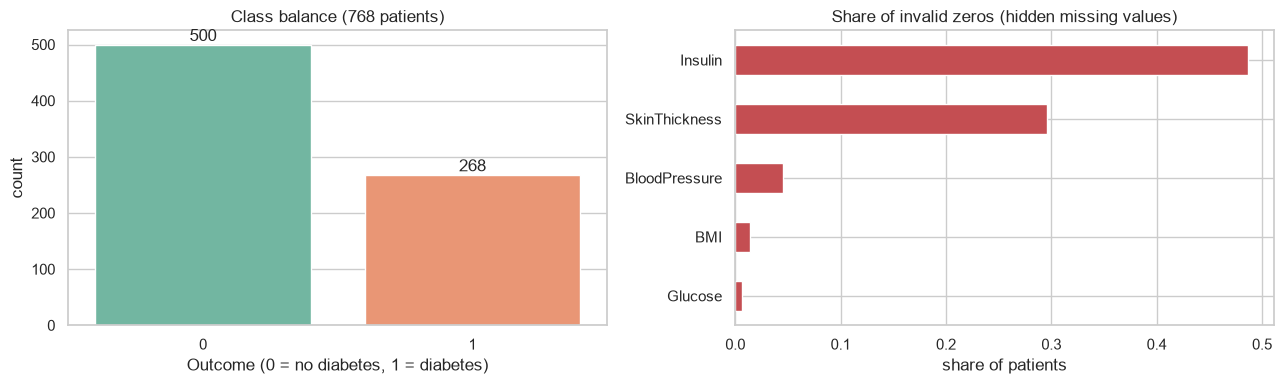

In [6]:
cls = df_raw['Outcome'].value_counts().sort_index()
print('Class balance:', {int(k): f'{v} ({v / len(df_raw):.1%})' for k, v in cls.items()})

zeros = pd.DataFrame({'n_invalid_zero': (df_raw[ZERO_INVALID] == 0).sum(),
                      'share': (df_raw[ZERO_INVALID] == 0).mean().round(4)})
zeros['share_in_Outcome0'] = df_raw[df_raw.Outcome == 0][ZERO_INVALID].eq(0).mean().round(4)
zeros['share_in_Outcome1'] = df_raw[df_raw.Outcome == 1][ZERO_INVALID].eq(0).mean().round(4)
display(zeros.sort_values('n_invalid_zero', ascending=False))

n_missing_per_row = df_raw[ZERO_INVALID].eq(0).sum(axis=1)
print('Patients by number of missing measurements:', n_missing_per_row.value_counts().sort_index().to_dict())
print('Complete cases (no invalid zero):', int((n_missing_per_row == 0).sum()))
print('Legitimate zeros kept as values: Pregnancies =', int((df_raw.Pregnancies == 0).sum()))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=df_raw, x='Outcome', hue='Outcome', palette='Set2', legend=False, ax=axes[0])
for c in axes[0].containers: axes[0].bar_label(c)
axes[0].set_title('Class balance (768 patients)'); axes[0].set_xlabel('Outcome (0 = no diabetes, 1 = diabetes)')
zeros['share'].sort_values().plot.barh(ax=axes[1], color='#C44E52')
axes[1].set_title('Share of invalid zeros (hidden missing values)'); axes[1].set_xlabel('share of patients')
plt.tight_layout(); plt.show()

## 2. Locked split, shared folds and in-fold preprocessing

### 2.1 Split and folds

In [7]:
X_all, y_all = df_raw[FEATURES].copy(), df_raw['Outcome'].copy()
X_dev, _X_test, y_dev, _y_test = train_test_split(X_all, y_all, test_size=0.20, stratify=y_all, random_state=SEED)

class TestVault:
    # Holds the 20% test set. It can be opened exactly once (Section 12).
    def __init__(self, X, y):
        self._X, self._y, self.opened_at = X, y, None
    def open(self, reason):
        if self.opened_at is not None:
            raise RuntimeError(f'Test set was already opened at {self.opened_at}.')
        self.opened_at = time.strftime('%Y-%m-%d %H:%M:%S')
        print(f'TEST SET OPENED at {self.opened_at}: {reason}')
        return self._X.copy(), self._y.copy()
    def __repr__(self):
        return f'TestVault(n={len(self._X)}, opened={self.opened_at is not None})'

TEST_VAULT = TestVault(_X_test, _y_test)
N_TEST = len(_X_test)
del _X_test, _y_test

OUTER_CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
OUTER_FOLDS = list(OUTER_CV.split(X_dev, y_dev))
def inner_cv():
    return StratifiedKFold(n_splits=5, shuffle=True, random_state=INNER_SEED)

flow = pd.DataFrame([
    ('Raw verified file', 768, int(y_all.sum())),
    ('Development set (80%)', len(X_dev), int(y_dev.sum())),
    ('Locked test set (20%)', N_TEST, int(y_all.sum() - y_dev.sum())),
] + [(f'Outer fold {k + 1}: train / validation', f'{len(tr)} / {len(va)}', f'{int(y_dev.iloc[tr].sum())} / {int(y_dev.iloc[va].sum())}')
     for k, (tr, va) in enumerate(OUTER_FOLDS)], columns=['stage', 'rows', 'positives'])
display(flow)
print(TEST_VAULT)

,stage,rows,positives
0,Raw verified file,768,268
1,Development set (80%),614,214
2,Locked test set (20%),154,54
3,Outer fold 1: train / validation,491 / 123,171 / 43
4,Outer fold 2: train / validation,491 / 123,171 / 43
5,Outer fold 3: train / validation,491 / 123,171 / 43
6,Outer fold 4: train / validation,491 / 123,171 / 43
7,Outer fold 5: train / validation,492 / 122,172 / 42


TestVault(n=154, opened=False)


### 2.2 Preprocessing objects

Every pipeline begins with `make_preprocessor(columns)`. It (1) keeps only the requested raw columns, (2) recodes invalid zeros as missing, (3) standardises, then (4) runs KNN imputation (k = 5) in the standardised space. Every step is fitted on the training part of the current fold only.

* Passing `columns` restricts the data **before** imputation. A discarded measurement then cannot influence the imputed values of the kept ones. That property is what justifies a "fewer clinical measurements" claim.
* `Unsupervised(...)` wraps every unsupervised reducer so the outcome is never passed to its `fit`. Without the wrapper, a scikit-learn Pipeline would pass `y` to UMAP, which would then silently run *supervised* UMAP.

In [8]:
class ColumnSubset(BaseEstimator, TransformerMixin):
    def __init__(self, columns=None):
        self.columns = columns
    def fit(self, X, y=None):
        self.columns_ = list(X.columns) if self.columns is None else list(self.columns)
        return self
    def transform(self, X):
        return X[self.columns_].copy()

class ZeroToNaN(BaseEstimator, TransformerMixin):
    def __init__(self, invalid=tuple(ZERO_INVALID)):
        self.invalid = invalid
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X = X.copy()
        for c in self.invalid:
            if c in X.columns:
                X[c] = X[c].replace(0, np.nan)
        return X

def make_preprocessor(columns=None, k=5):
    return Pipeline([('select', ColumnSubset(columns)), ('zero_to_nan', ZeroToNaN()),
                     ('scale', StandardScaler()), ('impute', KNNImputer(n_neighbors=k))])

class Unsupervised(BaseEstimator, TransformerMixin):
    # Fits the wrapped reducer WITHOUT the outcome; train coordinates = fit_transform, new data = transform.
    def __init__(self, estimator):
        self.estimator = estimator
    def fit(self, X, y=None):
        self.estimator_ = clone(self.estimator).fit(X)
        return self
    def fit_transform(self, X, y=None):
        self.estimator_ = clone(self.estimator)
        return self.estimator_.fit_transform(X)
    def transform(self, X):
        return self.estimator_.transform(X)

def to_units(pre, Z):
    # Undo the scaling of a fitted make_preprocessor() output, giving clinical units.
    return pd.DataFrame(pre.named_steps['scale'].inverse_transform(Z), columns=pre.named_steps['select'].columns_)

# Sanity checks: no NaN after preprocessing, and imputation uses only training rows.
_pre = make_preprocessor().fit(X_dev.iloc[OUTER_FOLDS[0][0]])
_Z = _pre.transform(X_dev.iloc[OUTER_FOLDS[0][1]])
assert not np.isnan(_Z).any()
print('Preprocessor OK:', _Z.shape, '| scaler fitted on', _pre.named_steps['scale'].n_samples_seen_.min(), '-',
      _pre.named_steps['scale'].n_samples_seen_.max(), 'observed values per column (fold-1 training part only)')

Preprocessor OK: (123, 8) | scaler fitted on 252.0 - 491.0 observed values per column (fold-1 training part only)


### 2.3 Shared evaluation engine

`cv_grid(representations, classifiers)` loops over the same `OUTER_FOLDS`. In each fold it fits a representation (preprocessing plus optional selection or reduction) on the training part, transforms the validation part, and fits every classifier on that representation. It records validation metrics, training metrics (for the over/underfitting check) and out-of-fold probabilities. Each representation is fitted once per fold and shared by all classifiers, so every classifier sees exactly the same features.

In [9]:
def metric_block(y_true, prob, thr=0.5):
    pred = (np.asarray(prob) >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    acc = accuracy_score(y_true, pred)
    return {'accuracy': acc, 'error_rate': 1 - acc,
            'precision': precision_score(y_true, pred, zero_division=0),
            'recall': recall_score(y_true, pred, zero_division=0),
            'specificity': tn / (tn + fp) if (tn + fp) else np.nan,
            'f1': f1_score(y_true, pred, zero_division=0),
            'roc_auc': roc_auc_score(y_true, prob), 'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp}

def selected_names(rep):
    if hasattr(rep, 'subset_'):
        return list(rep.subset_)
    if isinstance(rep, Pipeline) and hasattr(rep.steps[-1][1], 'get_support'):
        cols = rep.named_steps['pre'].named_steps['select'].columns_
        return [c for c, s in zip(cols, rep.steps[-1][1].get_support()) if s]
    return None

def cv_grid(representations, classifiers, X=None, y=None, folds=None, verbose=True):
    X = X_dev if X is None else X
    y = y_dev if y is None else y
    folds = OUTER_FOLDS if folds is None else folds
    rows, oof, info = [], {}, []
    for rname, rfac in representations.items():
        t_rep = time.perf_counter()
        for k, (tr, va) in enumerate(folds):
            Xtr, Xva, ytr, yva = X.iloc[tr], X.iloc[va], y.iloc[tr], y.iloc[va]
            t0 = time.perf_counter()
            rep = rfac()
            Ztr = rep.fit_transform(Xtr, ytr)
            Zva = rep.transform(Xva)
            rep_sec = time.perf_counter() - t0
            info.append({'representation': rname, 'fold': k + 1, 'n_dims': np.asarray(Ztr).shape[1],
                         'selected': selected_names(rep), 'fit_seconds': rep_sec,
                         'extra': getattr(rep, 'search_info_', None)})
            for cname, cfac in classifiers.items():
                clf = cfac().fit(Ztr, ytr)
                p_tr, p_va = clf.predict_proba(Ztr)[:, 1], clf.predict_proba(Zva)[:, 1]
                tr_m = metric_block(ytr, p_tr)
                row = {'representation': rname, 'classifier': cname, 'fold': k + 1,
                       'n_dims': np.asarray(Ztr).shape[1], **metric_block(yva, p_va),
                       'train_accuracy': tr_m['accuracy'], 'train_roc_auc': tr_m['roc_auc']}
                if hasattr(clf, 'best_params_'):
                    row['best_params'] = str(clf.best_params_)
                rows.append(row)
                oof.setdefault((rname, cname), np.full(len(y), np.nan))[va] = p_va
        if verbose:
            print(f'  {rname:45s} done in {time.perf_counter() - t_rep:6.1f}s')
    return pd.DataFrame(rows), oof, pd.DataFrame(info)

def summarize(res):
    g = res.groupby(['representation', 'classifier'], sort=False)
    out = pd.DataFrame({
        'n_dims': g['n_dims'].mean(),
        'cv_accuracy_mean': g['accuracy'].mean(), 'cv_accuracy_sd': g['accuracy'].std(),
        'cv_roc_auc_mean': g['roc_auc'].mean(), 'cv_roc_auc_sd': g['roc_auc'].std(),
        'cv_f1_mean': g['f1'].mean(), 'cv_recall_mean': g['recall'].mean(), 'cv_precision_mean': g['precision'].mean(),
        'train_accuracy_mean': g['train_accuracy'].mean(), 'train_roc_auc_mean': g['train_roc_auc'].mean()})
    out['auc_gap_train_minus_cv'] = out['train_roc_auc_mean'] - out['cv_roc_auc_mean']
    return out.reset_index()

### 2.4 Data analysis before and after preprocessing (development set only)

The plots use the 614 development patients with the preprocessor fitted on them. The test set stays unseen.

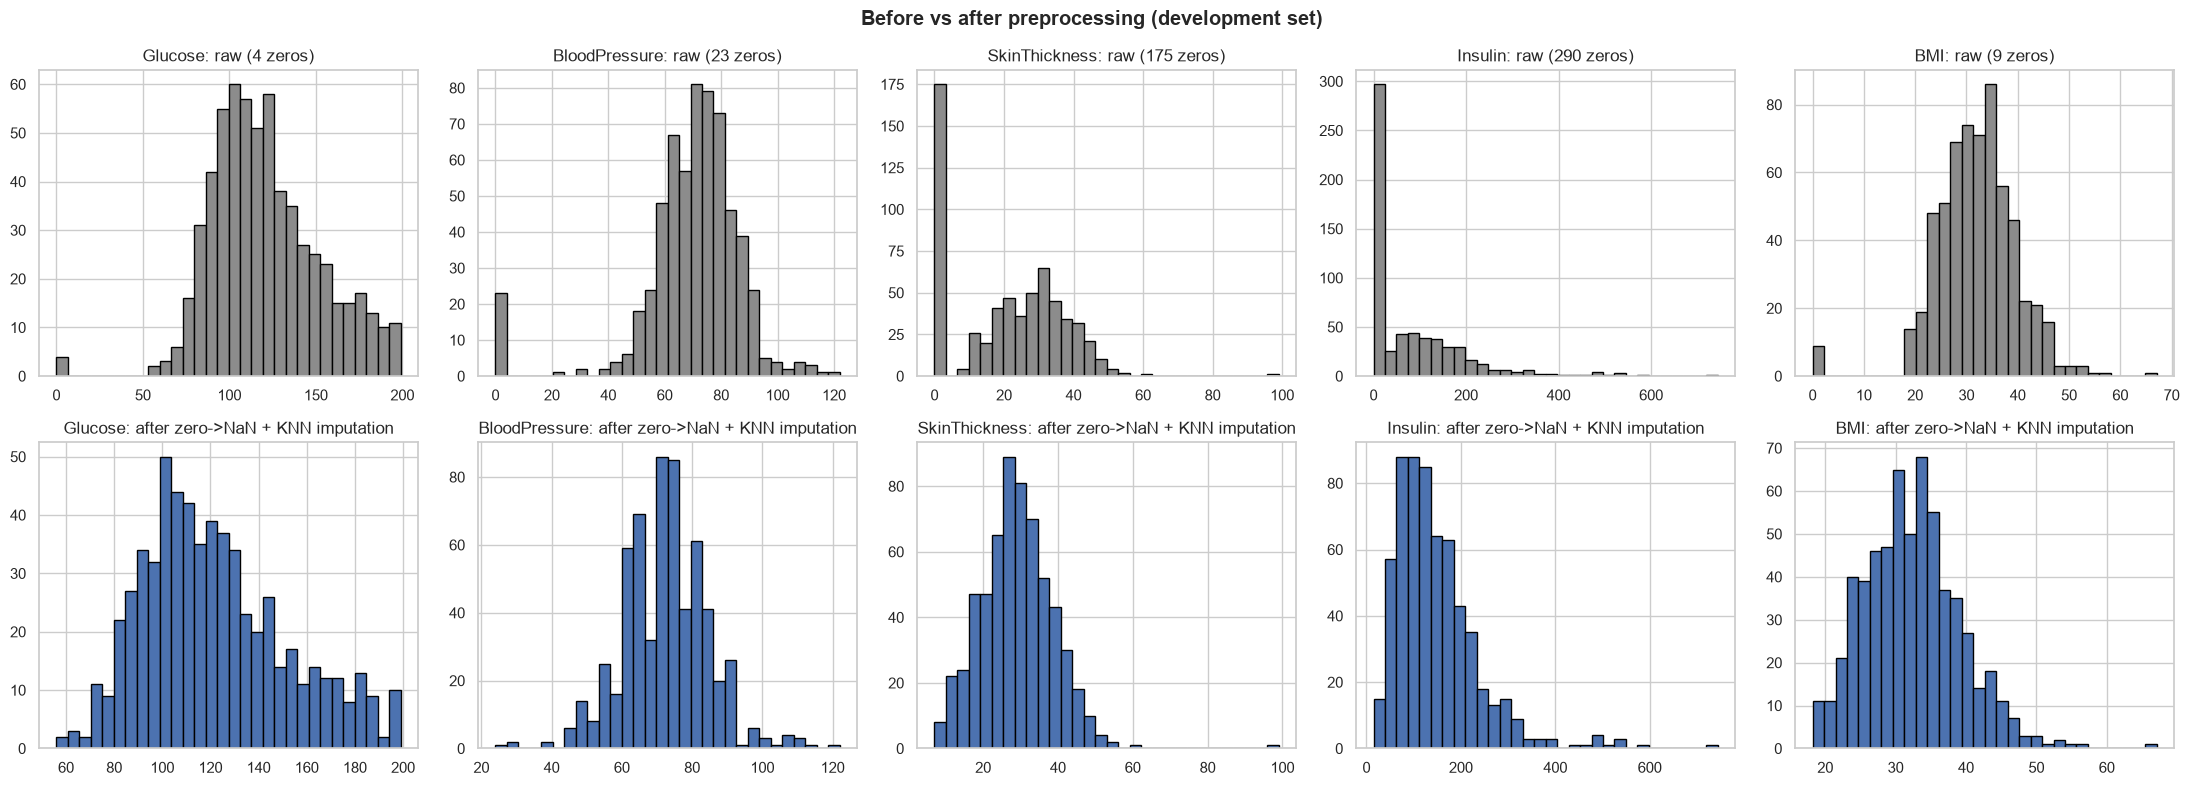

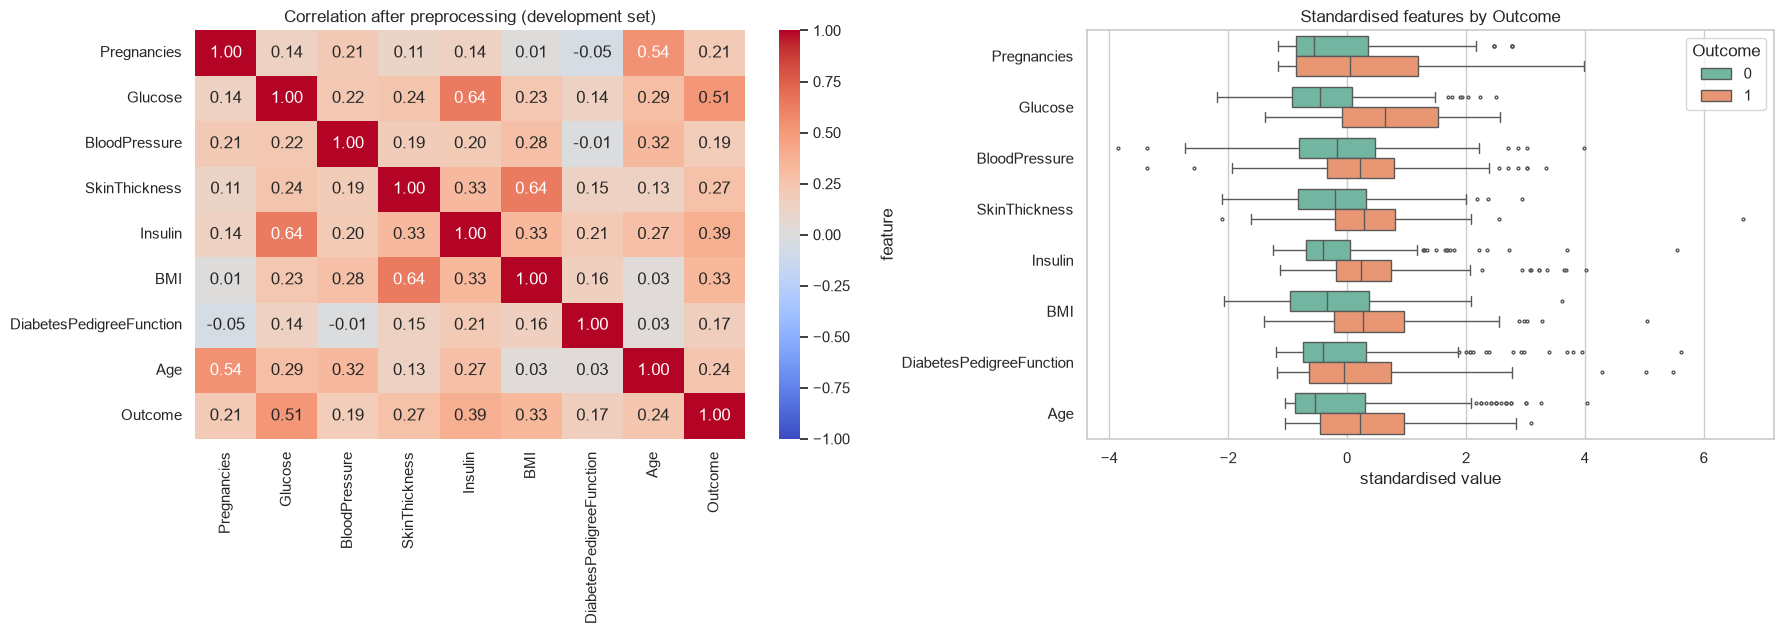

,"univariate ROC-AUC (dev, descriptive)"
Glucose,0.7986
Insulin,0.7722
BMI,0.6938
Age,0.6816
SkinThickness,0.6646
BloodPressure,0.6184
Pregnancies,0.6102
DiabetesPedigreeFunction,0.6037


In [10]:
pre_dev = make_preprocessor().fit(X_dev)
Z_dev = pre_dev.transform(X_dev)                 # standardised + imputed, used by Sections 4-7
dev_units = to_units(pre_dev, Z_dev)              # same data in clinical units
y_dev_np = y_dev.to_numpy()

fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for j, c in enumerate(ZERO_INVALID):
    axes[0, j].hist(X_dev[c], bins=30, color='#8C8C8C', edgecolor='black')
    axes[0, j].set_title(f'{c}: raw ({(X_dev[c] == 0).sum()} zeros)')
    axes[1, j].hist(dev_units[c], bins=30, color='#4C72B0', edgecolor='black')
    axes[1, j].set_title(f'{c}: after zero->NaN + KNN imputation')
plt.suptitle('Before vs after preprocessing (development set)', fontweight='bold'); plt.tight_layout(); plt.show()

plot_df = dev_units.assign(Outcome=y_dev_np)
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))
sns.heatmap(plot_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title('Correlation after preprocessing (development set)')
melted = (pd.DataFrame(Z_dev, columns=FEATURES).assign(Outcome=y_dev_np)
          .melt(id_vars='Outcome', var_name='feature', value_name='standardised value'))
sns.boxplot(data=melted, x='standardised value', y='feature', hue='Outcome', palette='Set2', ax=axes[1], fliersize=2)
axes[1].set_title('Standardised features by Outcome')
plt.tight_layout(); plt.show()

uni_auc = pd.Series({c: roc_auc_score(y_dev_np, Z_dev[:, j]) for j, c in enumerate(FEATURES)}, name='univariate ROC-AUC (dev, descriptive)')
display(uni_auc.sort_values(ascending=False).to_frame())

## 3. Model implementations on all 8 original features: 5-fold cross-validation

Seven classifiers from the original notebook, with the same settings, are run on the shared outer folds. The table reports **mean 5-fold accuracy (the rubric metric) ± SD**, the primary ROC-AUC, and training-fold scores for the over/underfitting check.

In [11]:
CLASSIFIERS = {
    'Logistic Regression': lambda: LogisticRegression(max_iter=2000),
    'KNN (k=7)': lambda: KNeighborsClassifier(n_neighbors=7),
    'SVM (RBF)': lambda: SVC(kernel='rbf', probability=True, random_state=SEED),
    'Gaussian Naive Bayes': lambda: GaussianNB(),
    'Decision Tree (depth 5)': lambda: DecisionTreeClassifier(max_depth=5, random_state=SEED),
    'Random Forest': lambda: RandomForestClassifier(n_estimators=200, max_depth=6, random_state=SEED, n_jobs=N_JOBS),
    'Gradient Boosting': lambda: GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=3, random_state=SEED),
}
ALL8 = 'All 8 original features'
REPS_BASE = {ALL8: lambda: make_preprocessor()}

res_base, oof_base, _ = cv_grid(REPS_BASE, CLASSIFIERS)
sum_base = summarize(res_base)

fold_acc = res_base.pivot(index='classifier', columns='fold', values='accuracy').reindex(CLASSIFIERS)
fold_acc.columns = [f'fold {c} acc' for c in fold_acc.columns]
fold_acc['MEAN 5-fold accuracy'] = fold_acc.mean(axis=1)
fold_acc['SD'] = fold_acc.iloc[:, :5].std(axis=1)
display(fold_acc.round(4))
display(sum_base.drop(columns='representation').set_index('classifier').round(4))

  All 8 original features                       done in    2.7s


,fold 1 acc,fold 2 acc,fold 3 acc,fold 4 acc,fold 5 acc,MEAN 5-fold accuracy,SD
classifier,,,,,,,
Logistic Regression,0.7886,0.7805,0.8211,0.7805,0.7705,0.7882,0.0195
KNN (k=7),0.7805,0.6911,0.8049,0.7561,0.7377,0.7540,0.0434
SVM (RBF),0.7642,0.7317,0.8130,0.7561,0.7541,0.7638,0.0300
Gaussian Naive Bayes,0.7561,0.7317,0.7886,0.7317,0.7787,0.7574,0.0262
Decision Tree (depth 5),0.7805,0.6992,0.7642,0.7398,0.7787,0.7525,0.0339
Random Forest,0.7805,0.7642,0.7805,0.7398,0.7705,0.7671,0.0167
Gradient Boosting,0.7642,0.7480,0.7480,0.7561,0.7459,0.7524,0.0077


,n_dims,cv_accuracy_mean,cv_accuracy_sd,cv_roc_auc_mean,cv_roc_auc_sd,cv_f1_mean,cv_recall_mean,cv_precision_mean,train_accuracy_mean,train_roc_auc_mean,auc_gap_train_minus_cv
classifier,,,,,,,,,,,
Logistic Regression,8.0,0.7882,0.0195,0.8436,0.0172,0.6566,0.5795,0.7603,0.7932,0.8516,0.0079
KNN (k=7),8.0,0.7540,0.0434,0.8096,0.0368,0.6280,0.5937,0.6729,0.8139,0.8928,0.0832
SVM (RBF),8.0,0.7638,0.0300,0.8306,0.0230,0.6208,0.5563,0.7162,0.8327,0.9049,0.0742
Gaussian Naive Bayes,8.0,0.7574,0.0262,0.8310,0.0096,0.6397,0.6171,0.6688,0.7675,0.8383,0.0072
Decision Tree (depth 5),8.0,0.7525,0.0339,0.7872,0.0150,0.6233,0.5890,0.6682,0.8518,0.9205,0.1333
Random Forest,8.0,0.7671,0.0167,0.8358,0.0145,0.6398,0.5937,0.6982,0.9129,0.9769,0.1411
Gradient Boosting,8.0,0.7524,0.0077,0.8202,0.0196,0.6339,0.6168,0.6563,0.9320,0.9823,0.1621


## 4. Linear feature reduction: PCA, LDA, SVD

These are fitted on the development set for inspection. Their predictive value is measured in-fold in Section 9.

PCA explained variance ratio: [0.3222 0.1965 0.1358 0.1132 0.0977 0.0573 0.0407 0.0368]
Components needed for 80% / 90% variance: 5 / 6
Truncated SVD (2) explained variance ratio: [0.3222 0.1965] | column means after preprocessing (max |mean|): 0.0108
LDA: binary outcome -> at most 1 discriminant axis; explained ratio [1.]


,PC1,PC2,PC3,LDA coef (scaled)
Pregnancies,0.298,0.545,-0.055,0.275
Glucose,0.438,-0.055,0.414,0.907
BloodPressure,0.356,0.142,-0.373,-0.023
SkinThickness,0.358,-0.315,-0.302,-0.028
Insulin,0.376,-0.113,0.279,-0.015
BMI,0.385,-0.451,-0.415,0.487
DiabetesPedigreeFunction,0.160,-0.336,0.579,0.164
Age,0.386,0.501,0.098,0.094


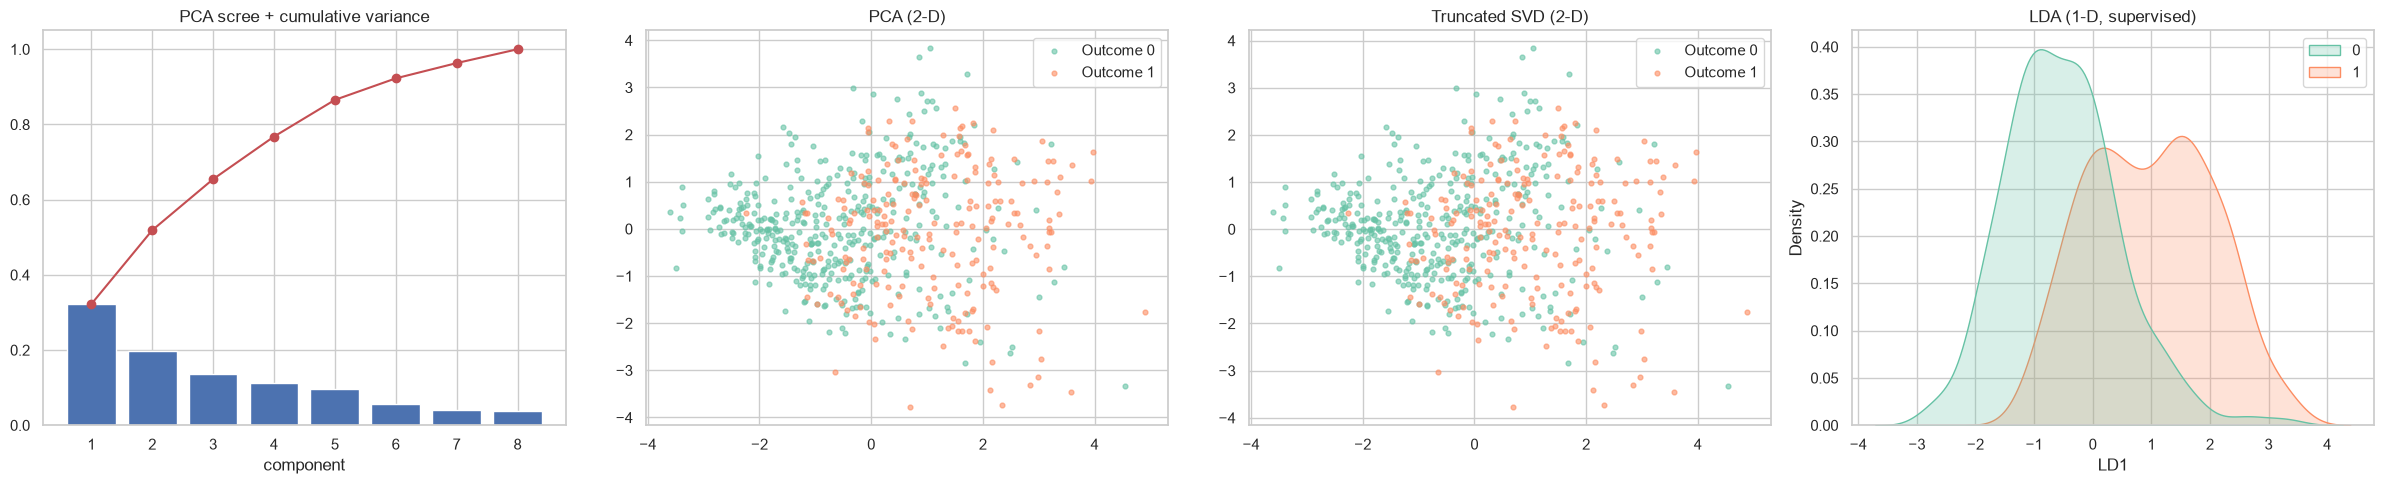

In [12]:
pca_full = PCA(random_state=SEED).fit(Z_dev)
evr = pca_full.explained_variance_ratio_
svd2 = TruncatedSVD(n_components=2, random_state=SEED).fit(Z_dev)
lda = LinearDiscriminantAnalysis(n_components=1).fit(Z_dev, y_dev_np)

print('PCA explained variance ratio:', np.round(evr, 4))
print('Components needed for 80% / 90% variance:', int(np.searchsorted(np.cumsum(evr), 0.80) + 1), '/', int(np.searchsorted(np.cumsum(evr), 0.90) + 1))
print('Truncated SVD (2) explained variance ratio:', np.round(svd2.explained_variance_ratio_, 4),
      '| column means after preprocessing (max |mean|):', np.abs(Z_dev.mean(0)).max().round(4))
print('LDA: binary outcome -> at most 1 discriminant axis; explained ratio', lda.explained_variance_ratio_)

loadings = pd.DataFrame(pca_full.components_[:3].T, index=FEATURES, columns=['PC1', 'PC2', 'PC3'])
loadings['LDA coef (scaled)'] = lda.scalings_[:, 0]
display(loadings.round(3))

fig, axes = plt.subplots(1, 4, figsize=(24, 5))
axes[0].bar(range(1, 9), evr, color='#4C72B0'); axes[0].plot(range(1, 9), np.cumsum(evr), 'o-', color='#C44E52')
axes[0].set_title('PCA scree + cumulative variance'); axes[0].set_xlabel('component')
for ax, (name, E) in zip(axes[1:3], [('PCA (2-D)', pca_full.transform(Z_dev)[:, :2]), ('Truncated SVD (2-D)', svd2.transform(Z_dev))]):
    for k, col in ((0, '#66C2A5'), (1, '#FC8D62')):
        ax.scatter(E[y_dev_np == k, 0], E[y_dev_np == k, 1], s=12, alpha=0.6, color=col, label=f'Outcome {k}')
    ax.set_title(name); ax.legend()
sns.kdeplot(x=lda.transform(Z_dev)[:, 0], hue=y_dev_np, fill=True, common_norm=False, palette='Set2', ax=axes[3])
axes[3].set_title('LDA (1-D, supervised)'); axes[3].set_xlabel('LD1')
plt.tight_layout(); plt.show()

SVD and PCA give nearly the same result here because the features are standardised, so already almost centred. TruncatedSVD does not centre the data and PCA does. LDA is the only supervised method in this section, and with two classes it has exactly one component.

## 5. Non-linear feature reduction

### 5.1 Verifying the custom SNE implementation

The original notebook implemented SNE from scratch. Its **variant is symmetric SNE** (van der Maaten & Hinton, 2008, Section 3.1):

* high-dimensional joint probabilities $p_{ij} = (p_{j|i} + p_{i|j}) / 2n$, with each Gaussian bandwidth set by binary search to the target perplexity;
* low-dimensional **joint** Gaussian similarities $q_{ij} \propto \exp(-\lVert y_i - y_j \rVert^2)$, normalised over all pairs. Hinton & Roweis' original (asymmetric) SNE uses conditional $q_{j|i}$ instead;
* gradient $\partial C / \partial y_i = 4 \sum_j (p_{ij} - q_{ij})(y_i - y_j)$.

t-SNE differs only in using a Student-t kernel for $q_{ij}$. The code below keeps the original algorithm (momentum 0.5 then 0.8, learning rate 200, global gradient-norm clipping at 100, no early exaggeration) and adds three checks:

1. the achieved perplexities match the target;
2. the analytic gradient matches a finite-difference gradient of the KL objective;
3. the KL divergence falls during optimisation.

In [13]:
def sne_joint_P(X, perplexity=30.0, tol=1e-5, max_steps=50):
    n = X.shape[0]
    D = squareform(pdist(X, metric='sqeuclidean'))
    P = np.zeros((n, n)); achieved = np.zeros(n)
    target = np.log(perplexity)
    for i in range(n):
        beta, bmin, bmax = 1.0, -np.inf, np.inf
        Di = np.delete(D[i], i)
        for _ in range(max_steps):
            Pi = np.exp(-Di * beta); s = Pi.sum() + 1e-12
            H = np.log(s) + beta * np.sum(Di * Pi) / s
            if abs(H - target) < tol:
                break
            if H > target:
                bmin = beta; beta = beta * 2 if bmax == np.inf else (beta + bmax) / 2
            else:
                bmax = beta; beta = beta / 2 if bmin == -np.inf else (beta + bmin) / 2
        Pi = np.exp(-Di * beta); Pi /= Pi.sum() + 1e-12
        achieved[i] = np.exp(-np.sum(Pi * np.log(np.maximum(Pi, 1e-300))))
        P[i, np.arange(n) != i] = Pi
    P = (P + P.T) / (2.0 * n)
    P = np.maximum(P, 1e-12); np.fill_diagonal(P, 0.0); P /= P.sum()
    return P, achieved

def sne_kl_grad(P, Y):
    sq = np.sum(Y ** 2, axis=1)
    D = np.maximum(sq[:, None] + sq[None, :] - 2 * Y @ Y.T, 0.0)
    Qn = np.exp(-D); np.fill_diagonal(Qn, 0.0)
    Q = Qn / (Qn.sum() + 1e-12)
    off = ~np.eye(len(P), dtype=bool)
    kl = np.sum(P[off] * np.log(P[off] / np.maximum(Q[off], 1e-300)))
    PQ = P - Q
    grad = 4.0 * (PQ.sum(axis=1)[:, None] * Y - PQ @ Y)
    return kl, grad

def fit_symmetric_sne(X, n_components=2, perplexity=30.0, n_iter=1000, lr=200.0, random_state=42, record_every=50):
    rng = np.random.default_rng(random_state)
    P, achieved = sne_joint_P(np.asarray(X, dtype=float), perplexity)
    Y = rng.normal(0.0, 1e-4, size=(P.shape[0], n_components))
    velocity = np.zeros_like(Y); history = []
    for it in range(n_iter):
        kl, grad = sne_kl_grad(P, Y)
        if it % record_every == 0 or it == n_iter - 1:
            history.append((it, kl))
        gnorm = np.linalg.norm(grad)
        if gnorm > 100:
            grad *= 100 / gnorm
        momentum = 0.5 if it < 250 else 0.8
        velocity = momentum * velocity - lr * grad
        Y += velocity
        Y -= Y.mean(axis=0)
    return Y, {'kl_history': history, 'achieved_perplexity': achieved}

# Check 1 + 2 on a 40-patient subsample: perplexity calibration and finite-difference gradient.
rng = np.random.default_rng(0)
idx = rng.choice(len(Z_dev), 40, replace=False)
P_s, ach = sne_joint_P(Z_dev[idx], perplexity=10)
Y_s = rng.normal(size=(40, 2))
_, g_analytic = sne_kl_grad(P_s, Y_s)
g_fd = np.zeros_like(Y_s); h = 1e-5
for i in range(40):
    for d in range(2):
        Yp, Ym = Y_s.copy(), Y_s.copy(); Yp[i, d] += h; Ym[i, d] -= h
        g_fd[i, d] = (sne_kl_grad(P_s, Yp)[0] - sne_kl_grad(P_s, Ym)[0]) / (2 * h)
rel_err = np.linalg.norm(g_analytic - g_fd) / np.linalg.norm(g_fd)
print(f'Perplexity calibration (target 10, n=40): achieved min {ach.min():.4f}, max {ach.max():.4f}')
print(f'Gradient check: relative error between analytic and finite-difference gradient = {rel_err:.2e}')
assert rel_err < 1e-4, 'SNE gradient does not match the KL objective'
assert np.allclose(P_s, P_s.T) and abs(P_s.sum() - 1) < 1e-9

Perplexity calibration (target 10, n=40): achieved min 9.9999, max 10.0001
Gradient check: relative error between analytic and finite-difference gradient = 2.14e-10


### 5.2 Embedding quality: all eleven methods on the same 614 development patients

All methods embed the same standardised, imputed development data (`Z_dev`) into 2-D. The exception is LDA, which has at most one axis for a binary outcome. Only LDA receives the outcome labels. The table reports:

* **Trustworthiness** at k = 10 neighbours (Venna & Kaski). It is the share of each point's embedding neighbours that were also near neighbours in the 8-D space; 1.0 is perfect neighbourhood preservation. k = 5 and 30 are given as a sensitivity check.
* **Runtime** in wall-clock seconds on this machine.
* **10-NN label agreement**: the share of each point's 10 nearest embedding neighbours that have the same Outcome. This is a descriptive number for how class-separated a plot *looks*. It uses the labels after fitting and is **not** a predictive estimate, because t-SNE, SNE and MDS cannot embed new patients. The same quantity in the original 8-D space is the reference.

In [14]:
EMBEDDERS = {
    'PCA': lambda: PCA(n_components=2, random_state=SEED),
    'Truncated SVD': lambda: TruncatedSVD(n_components=2, random_state=SEED),
    'LDA (supervised, 1-D)': None,
    'Kernel PCA (RBF, gamma=0.1)': lambda: KernelPCA(n_components=2, kernel='rbf', gamma=0.1, random_state=SEED),
    'SNE (custom symmetric)': None,
    't-SNE': lambda: TSNE(n_components=2, perplexity=30, init='pca', learning_rate='auto', max_iter=1000, random_state=SEED),
    'UMAP': lambda: umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=SEED),
    'Metric MDS': lambda: MDS(n_components=2, metric_mds=True, init='classical_mds', n_init=1, max_iter=300, random_state=SEED),
    'Non-metric MDS': lambda: MDS(n_components=2, metric_mds=False, init='classical_mds', n_init=1, max_iter=300, random_state=SEED),
    'Isomap (k=15)': lambda: Isomap(n_components=2, n_neighbors=15),
    'LLE (k=15)': lambda: LocallyLinearEmbedding(n_components=2, n_neighbors=15, reg=1e-3, eigen_solver='dense', random_state=SEED),
}

def label_agreement(E, y, k=10):
    nn = NearestNeighbors(n_neighbors=k + 1).fit(E)
    _, ind = nn.kneighbors(E)
    return float((y[ind[:, 1:]] == y[:, None]).mean())

embeddings, emb_rows = {}, []
for name, fac in EMBEDDERS.items():
    t0 = time.perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', FutureWarning)
        if name.startswith('LDA'):
            E = LinearDiscriminantAnalysis(n_components=1).fit_transform(Z_dev, y_dev_np)
        elif name.startswith('SNE'):
            E, sne_diag = fit_symmetric_sne(Z_dev, perplexity=30, n_iter=1000, lr=200, random_state=SEED)
        else:
            E = fac().fit_transform(Z_dev)
    sec = time.perf_counter() - t0
    E = np.asarray(E, dtype=float)
    embeddings[name] = E
    emb_rows.append({'method': name, 'dims': E.shape[1], 'supervised': name.startswith('LDA'),
                     'out_of_sample_transform': name.split(' ')[0] in ('PCA', 'Truncated', 'LDA', 'Kernel', 'UMAP', 'Isomap', 'LLE'),
                     'trustworthiness_k5': trustworthiness(Z_dev, E, n_neighbors=5),
                     'trustworthiness_k10': trustworthiness(Z_dev, E, n_neighbors=10),
                     'trustworthiness_k30': trustworthiness(Z_dev, E, n_neighbors=30),
                     'label_agreement_10nn': label_agreement(E, y_dev_np), 'seconds': sec})
emb_table = pd.DataFrame(emb_rows).sort_values('trustworthiness_k10', ascending=False).reset_index(drop=True)
print(f'Reference: 10-NN label agreement in the original 8-D space = {label_agreement(Z_dev, y_dev_np):.4f}; '
      f'majority-class share = {max(y_dev_np.mean(), 1 - y_dev_np.mean()):.4f}')
display(emb_table.round(4))
emb_table.to_csv(RESULTS / 'embedding_quality.csv', index=False)

kl = np.array(sne_diag['kl_history'])
print(f"SNE check 3: KL {kl[0, 1]:.3f} (iter 0) -> {kl[-1, 1]:.3f} (iter {int(kl[-1, 0])}); "
      f"achieved perplexity range {sne_diag['achieved_perplexity'].min():.3f}-{sne_diag['achieved_perplexity'].max():.3f} (target 30)")

Reference: 10-NN label agreement in the original 8-D space = 0.6956; majority-class share = 0.6515


,method,dims,supervised,out_of_sample_transform,trustworthiness_k5,trustworthiness_k10,trustworthiness_k30,label_agreement_10nn,seconds
0,t-SNE,2,False,False,0.9771,0.9576,0.9117,0.6943,0.7077
1,UMAP,2,False,True,0.9473,0.9345,0.8999,0.6927,7.9382
2,SNE (custom symmetric),2,False,False,0.8556,0.8577,0.8610,0.6735,13.5044
3,Metric MDS,2,False,False,0.8484,0.8548,0.8704,0.6765,0.6246
4,Non-metric MDS,2,False,False,0.8511,0.8545,0.8695,0.6721,2.7938
5,Isomap (k=15),2,False,True,0.8268,0.8331,0.8424,0.6682,0.0552
6,PCA,2,False,True,0.8312,0.8310,0.8441,0.6749,0.0009
7,Truncated SVD,2,False,True,0.8314,0.8310,0.8441,0.6748,0.0009
8,"Kernel PCA (RBF, gamma=0.1)",2,False,True,0.7928,0.7977,0.8036,0.6650,0.0142
9,LLE (k=15),2,False,True,0.7734,0.7743,0.7869,0.6678,0.0731


SNE check 3: KL 2.861 (iter 0) -> 1.328 (iter 999); achieved perplexity range 30.000-30.000 (target 30)


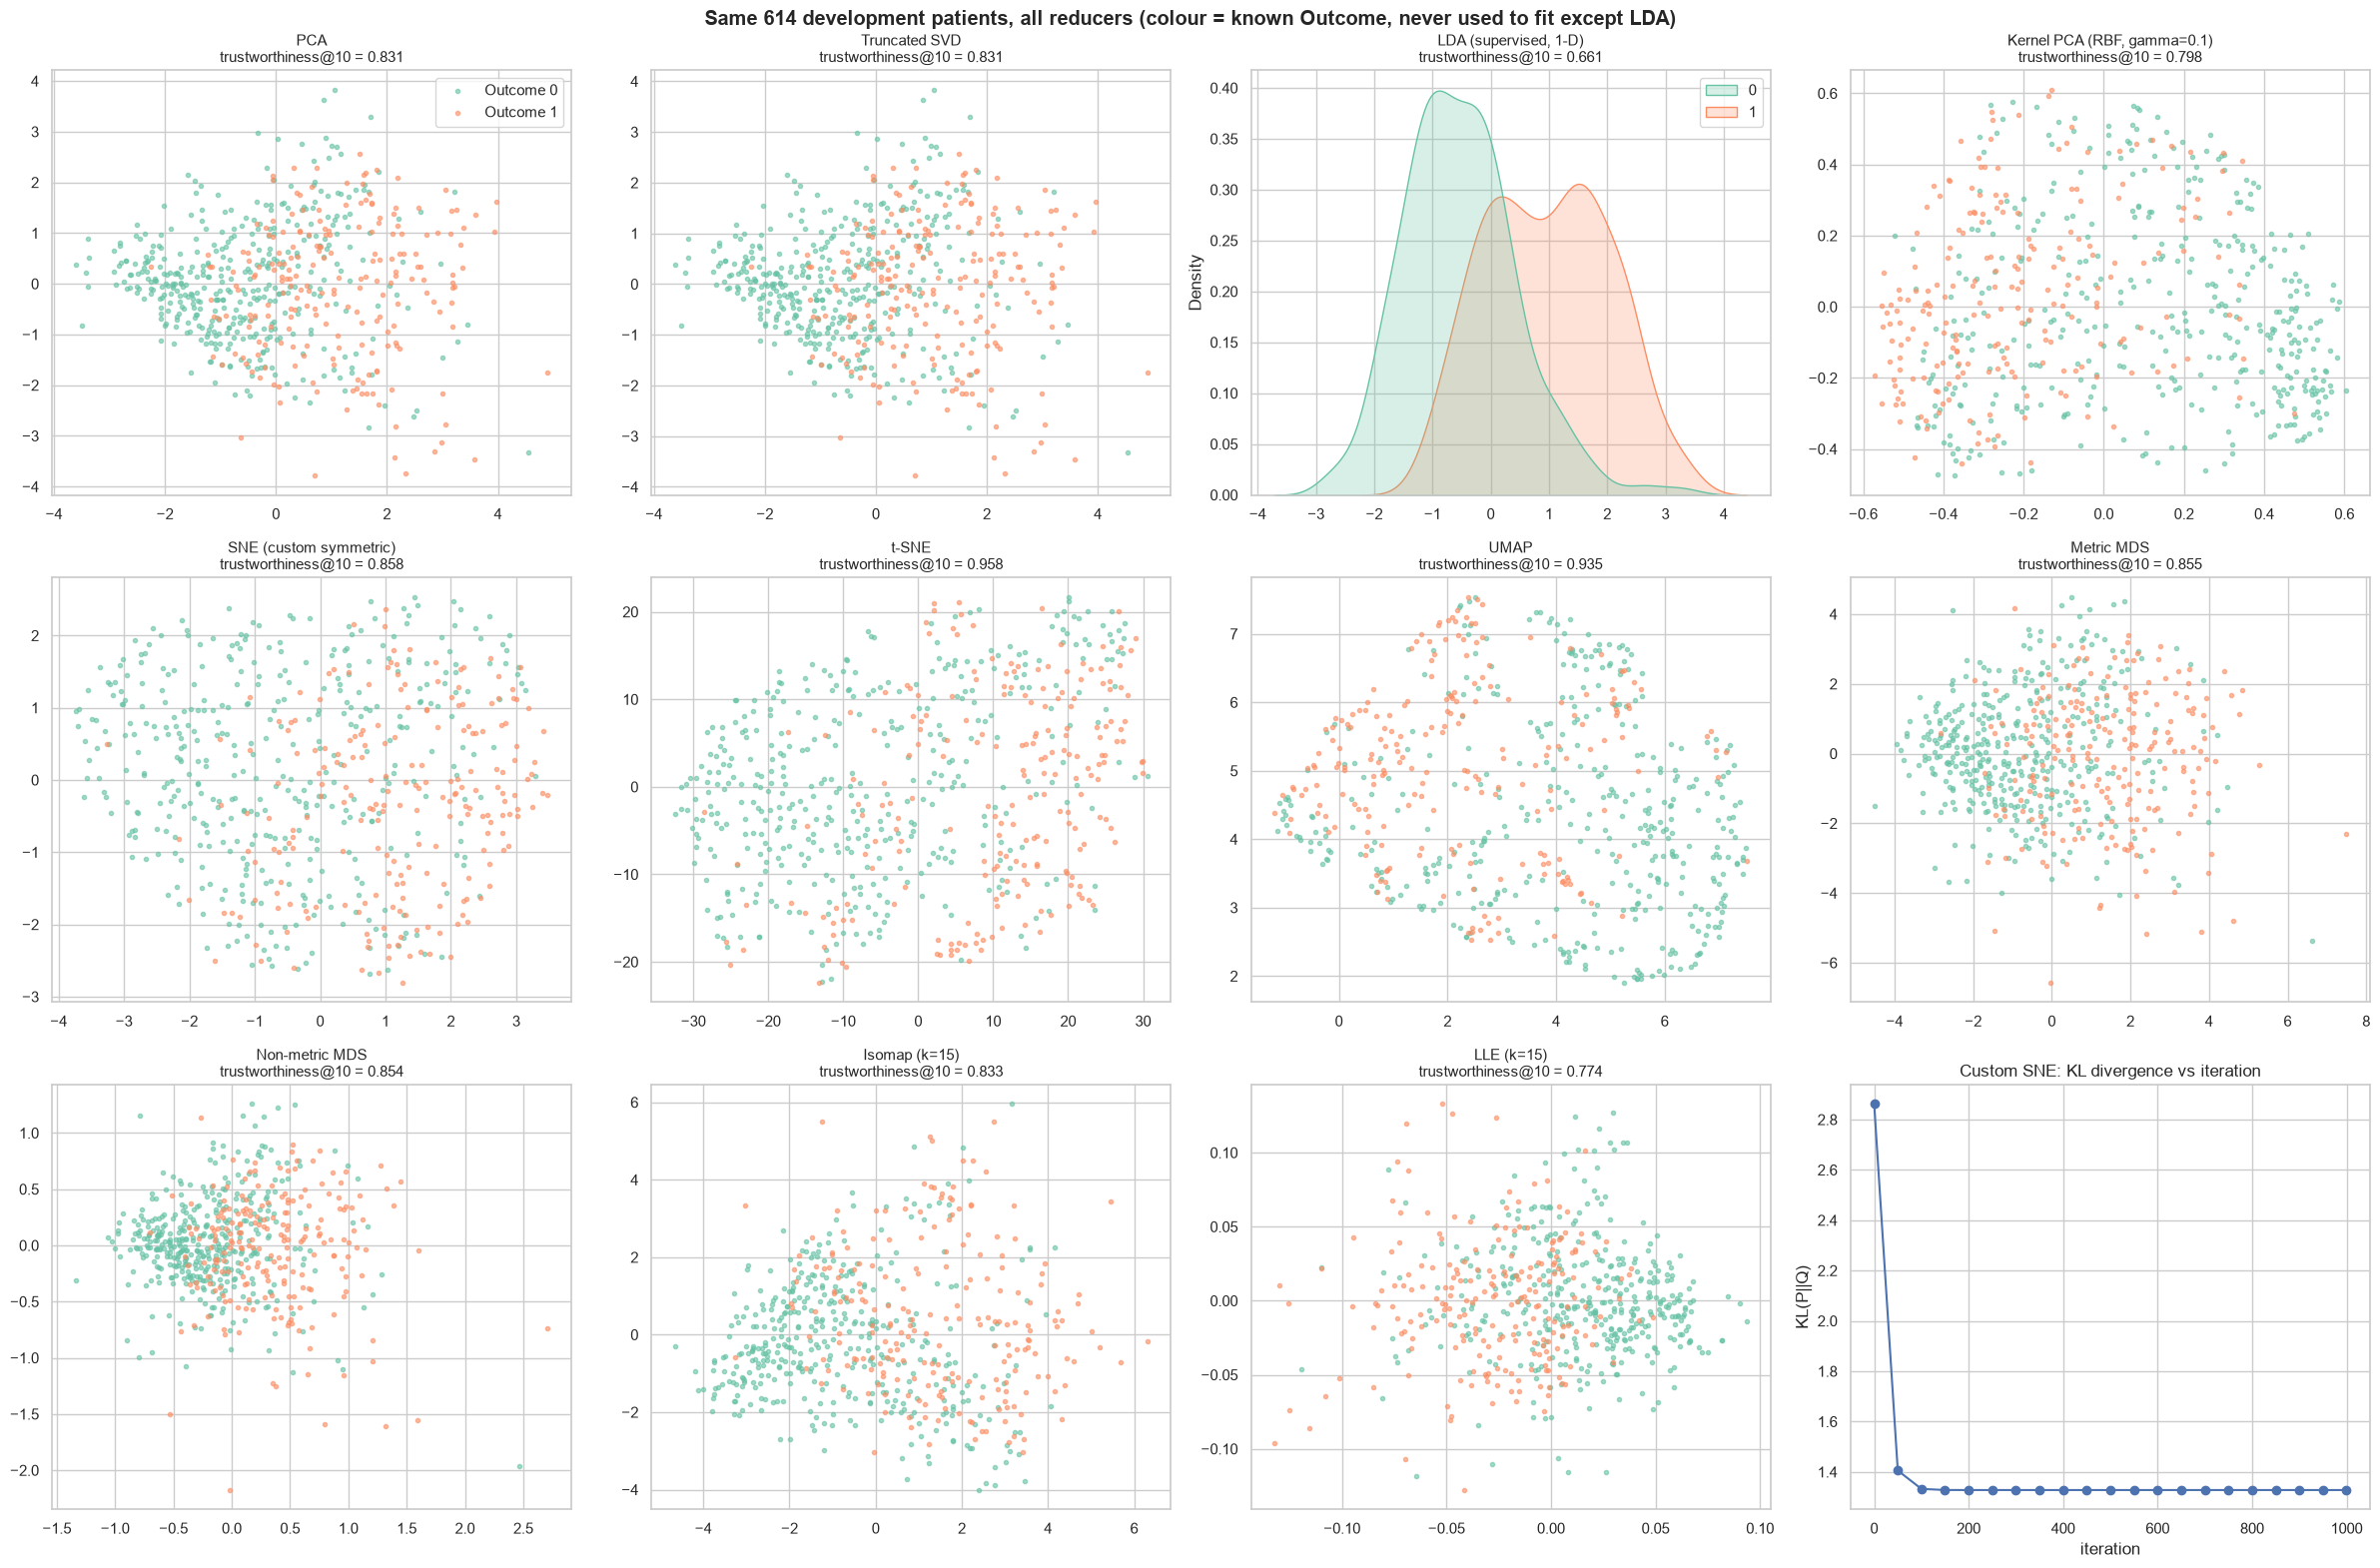

In [15]:
fig, axes = plt.subplots(3, 4, figsize=(24, 16)); axes = axes.ravel()
tw = emb_table.set_index('method')['trustworthiness_k10']
for ax, (name, E) in zip(axes, embeddings.items()):
    if E.shape[1] == 1:
        sns.kdeplot(x=E[:, 0], hue=y_dev_np, fill=True, common_norm=False, palette='Set2', ax=ax)
    else:
        for k, col in ((0, '#66C2A5'), (1, '#FC8D62')):
            ax.scatter(E[y_dev_np == k, 0], E[y_dev_np == k, 1], s=9, alpha=0.6, color=col, label=f'Outcome {k}')
    ax.set_title(f'{name}\ntrustworthiness@10 = {tw[name]:.3f}', fontsize=11)
axes[0].legend()
ax = axes[-1]
ax.plot(kl[:, 0], kl[:, 1], 'o-'); ax.set_title('Custom SNE: KL divergence vs iteration'); ax.set_xlabel('iteration'); ax.set_ylabel('KL(P||Q)')
plt.suptitle('Same 614 development patients, all reducers (colour = known Outcome, never used to fit except LDA)', fontweight='bold')
plt.tight_layout(); plt.show()

**Reading the embedding comparison (measured in this run):**

* **Neighbourhood preservation.** t-SNE (trustworthiness@10 = 0.958) and UMAP (0.935) preserve local neighbourhoods best. They are followed by the custom SNE (0.858), metric and non-metric MDS (0.855), Isomap (0.833), PCA/SVD (0.831), Kernel PCA (0.798) and LLE (0.774). The ranking holds at k = 5 and k = 30, except that the MDS variants and SNE overtake each other at k = 30.
* **SNE vs t-SNE.** The verified symmetric SNE trails t-SNE by about 0.10 in trustworthiness. This is the crowding problem: the Gaussian low-dimensional kernel cannot place moderately distant neighbours far enough apart, so clusters merge into one disc.
* **Visual separation vs reality.** Every unsupervised embedding has 10-NN label agreement of 0.665–0.694. The original 8-D space scores 0.696 and the majority-class rate is 0.652. The embeddings therefore **do not create** class separation that the raw features lack; the overlap seen in the t-SNE and UMAP plots is genuine. Only the supervised LDA axis scores higher (0.710), and that is because it was fitted with the labels. A plot that looks clean or messy is not evidence of predictive power. Section 9 measures that directly.

## 6. Clustering without outcome labels: visualization before and after clustering

K-means is fitted on the standardised, imputed development features **without the outcome**. The number of clusters is chosen by silhouette over k = 2…6. The known diabetes classes are brought in only afterwards, to ask whether the discovered clusters line up with them (adjusted Rand index, normalised mutual information, cross-tabulation).

Silhouette by k: {2: 0.2147, 3: 0.2079, 4: 0.1533, 5: 0.1432, 6: 0.151} -> chosen k = 2
k=2: ARI vs diabetes = 0.1944, NMI = 0.1479
k=2  : ARI vs diabetes = 0.1944, NMI = 0.1479


known Outcome,0,1,All
cluster (k=2),,,
0,118,161,279
1,282,53,335
All,400,214,614


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,"diabetes_rate (known, post hoc)",n
cluster,,,,,,,,,,
0,6.0,137.0,78.0,32.4,181.6,34.6,0.38,41.0,0.577,279
1,2.0,105.0,66.0,25.0,95.0,30.0,0.38,25.0,0.158,335


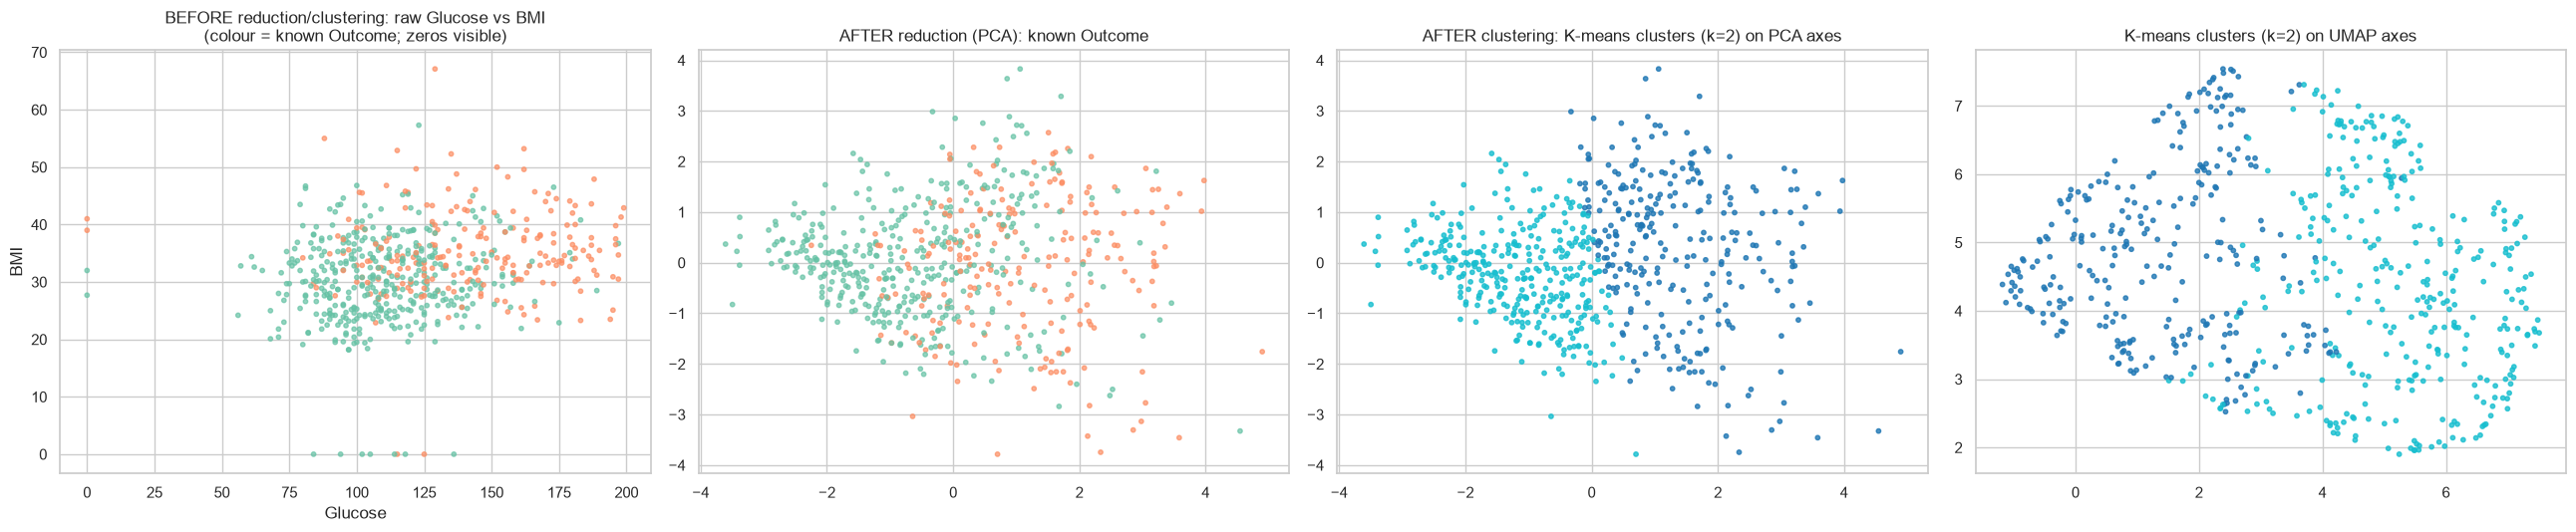

In [16]:
sil = {}
for k in range(2, 7):
    lab = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(Z_dev)
    sil[k] = silhouette_score(Z_dev, lab)
k_best = max(sil, key=sil.get)
print('Silhouette by k:', {k: round(v, 4) for k, v in sil.items()}, '-> chosen k =', k_best)

km = KMeans(n_clusters=k_best, n_init=20, random_state=SEED).fit(Z_dev)
clusters = km.labels_
km2 = km if k_best == 2 else KMeans(n_clusters=2, n_init=20, random_state=SEED).fit(Z_dev)

print(f'k={k_best}: ARI vs diabetes = {adjusted_rand_score(y_dev_np, clusters):.4f}, NMI = {normalized_mutual_info_score(y_dev_np, clusters):.4f}')
print(f'k=2  : ARI vs diabetes = {adjusted_rand_score(y_dev_np, km2.labels_):.4f}, NMI = {normalized_mutual_info_score(y_dev_np, km2.labels_):.4f}')
display(pd.crosstab(pd.Series(clusters, name=f'cluster (k={k_best})'), pd.Series(y_dev_np, name='known Outcome'), margins=True))
profile = dev_units.assign(cluster=clusters).groupby('cluster').median().round(2)
profile['diabetes_rate (known, post hoc)'] = pd.Series(y_dev_np).groupby(clusters).mean().round(3)
profile['n'] = pd.Series(clusters).value_counts().sort_index()
display(profile)

E_pca, E_umap = embeddings['PCA'], embeddings['UMAP']
fig, axes = plt.subplots(1, 4, figsize=(26, 5.5))
axes[0].scatter(X_dev['Glucose'], X_dev['BMI'], c=np.where(y_dev_np == 1, '#FC8D62', '#66C2A5'), s=10, alpha=0.7)
axes[0].set_title('BEFORE reduction/clustering: raw Glucose vs BMI\n(colour = known Outcome; zeros visible)'); axes[0].set_xlabel('Glucose'); axes[0].set_ylabel('BMI')
axes[1].scatter(E_pca[:, 0], E_pca[:, 1], c=np.where(y_dev_np == 1, '#FC8D62', '#66C2A5'), s=10, alpha=0.7)
axes[1].set_title('AFTER reduction (PCA): known Outcome')
axes[2].scatter(E_pca[:, 0], E_pca[:, 1], c=clusters, cmap='tab10', s=10, alpha=0.8)
axes[2].set_title(f'AFTER clustering: K-means clusters (k={k_best}) on PCA axes')
axes[3].scatter(E_umap[:, 0], E_umap[:, 1], c=clusters, cmap='tab10', s=10, alpha=0.8)
axes[3].set_title(f'K-means clusters (k={k_best}) on UMAP axes')
plt.tight_layout(); plt.show()

**Discovered clusters are not the diabetes classes.** The silhouette is best at k = 2, but it is low (0.21), so the data has no strong cluster structure. The two clusters split the patients into an older, more often pregnant, heavier, higher-glucose profile (cluster 0, median age 41, glucose 137, BMI 34.6) and a younger, leaner profile (cluster 1, median age 25, glucose 105, BMI 30.0). Cluster 0 is enriched for diabetes: 58% versus 16%, using labels only after fitting. Agreement with diagnosis is still weak (ARI 0.19, NMI 0.15). 118 of the 279 patients in the "high-risk" cluster are not diabetic, and 53 of the 214 diabetics fall in the "low-risk" cluster. The clusters describe risk profiles; they do not recover the diagnosis.

## 7. Feature selection: filter, wrapper and embedded methods

**Selection rules.** Each rule is applied inside every outer training fold in Section 9, and to the full development set here for display.

| Method | Family | Rule that turns scores into a subset |
|---|---|---|
| Mutual information | Filter | Rank features by MI with the outcome (`mutual_info_classif`). Choose k as the **smallest** k whose inner-CV AUC (logistic regression on the top-k) is within 0.002 of the best k |
| Forward SFS | Wrapper | Start empty; add the feature giving the largest inner-CV AUC gain; **stop when the gain < 0.002** |
| Backward SFS | Wrapper | Start with all 8; remove the feature whose removal hurts inner-CV AUC least; **continue while the loss ≤ 0.002** (`tol=-0.002`) |
| RFECV | Wrapper | Recursive elimination by |coefficient|; keep the size with the highest inner-CV AUC |
| L1 (Lasso) | Embedded | `LogisticRegressionCV` picks C by inner-CV AUC; keep features with **non-zero** coefficients |
| L2 (Ridge) | Embedded | L2 never sets weights to exactly 0. Pick C by inner-CV AUC, then keep features with \|coef\| ≥ **mean \|coef\|** (`SelectFromModel(threshold='mean')`) |
| Elastic Net (l1_ratio 0.5) | Embedded | Pick C by inner-CV AUC; keep **non-zero** coefficients |

These seven methods select **after** KNN imputation, so a dropped column still helped impute the kept ones. They therefore reduce model inputs but not the measurements a clinic must take. Only the raw-column searches in Section 8 support a "fewer measurements" claim.

MI inner-CV AUC by k: [0.7976 0.8037 0.8284 0.8351 0.8404 0.8397 0.8383 0.8442] -> k = 8


Embedded: L1 (non-zero)                  C chosen = 1
Embedded: L2 (|coef| >= mean)            C chosen = 0.1


Embedded: Elastic Net (non-zero)         C chosen = 0.4642


,mutual_information,ANOVA_F
Glucose,0.1225,218.9383
Insulin,0.1109,106.8796
BMI,0.0918,74.7023
Age,0.0622,37.6296
Pregnancies,0.0381,27.7229
SkinThickness,0.0237,47.0252
BloodPressure,0.0186,21.9629
DiabetesPedigreeFunction,0.0062,17.1947


,selected on full dev set,n
Filter: mutual information (k by inner CV),"Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, DiabetesPe...",8
Wrapper: forward SFS (tol 0.002),"Pregnancies, Glucose, BMI, DiabetesPedigreeFunction",4
Wrapper: backward SFS (tol -0.002),"Pregnancies, Glucose, BMI, DiabetesPedigreeFunction",4
Wrapper: RFECV,"Pregnancies, Glucose, BloodPressure, BMI, DiabetesPedigreeFunction, Age",6
Embedded: L1 (non-zero),"Pregnancies, Glucose, BloodPressure, BMI, DiabetesPedigreeFunction, Age",6
Embedded: L2 (|coef| >= mean),"Pregnancies, Glucose, BMI",3
Embedded: Elastic Net (non-zero),"Pregnancies, Glucose, BloodPressure, BMI, DiabetesPedigreeFunction, Age",6


,L1 (non-zero),L2 (|coef| >= mean),Elastic Net (non-zero)
Pregnancies,0.3697,0.3178,0.3607
Glucose,1.1626,0.9852,1.1414
BloodPressure,-0.0339,-0.0109,-0.0262
SkinThickness,0.0000,0.0646,0.0000
Insulin,0.0000,0.0909,0.0000
BMI,0.6918,0.5693,0.6778
DiabetesPedigreeFunction,0.2237,0.2071,0.2207
Age,0.1422,0.1535,0.1431


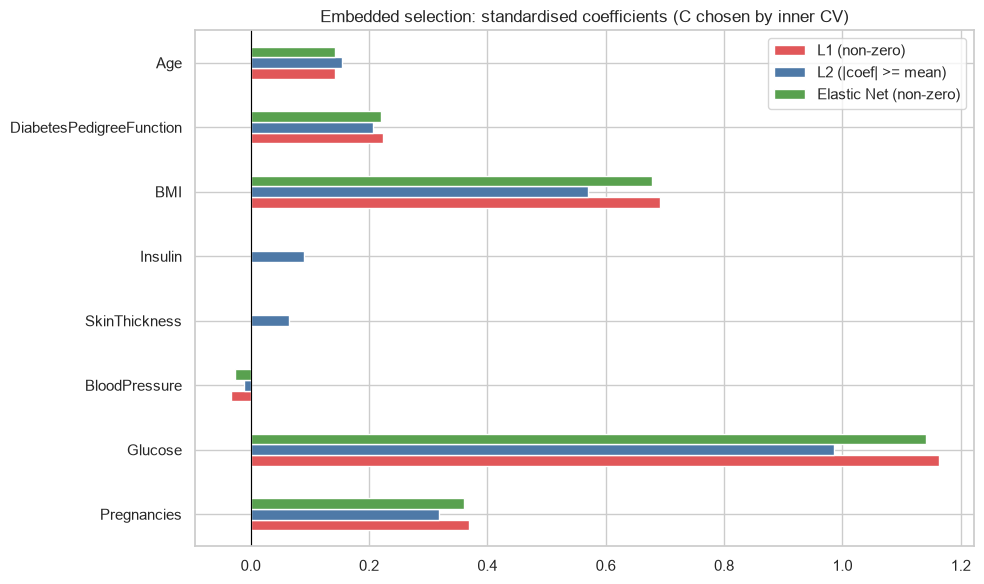

In [17]:
LR_REF = lambda: LogisticRegression(max_iter=2000)
CS = np.logspace(-3, 1, 13)

class MutualInfoKByInnerCV(BaseEstimator, TransformerMixin):
    def __init__(self, tol=0.002, random_state=SEED):
        self.tol, self.random_state = tol, random_state
    def fit(self, X, y):
        X, y = np.asarray(X), np.asarray(y)
        self.scores_ = mutual_info_classif(X, y, random_state=self.random_state)
        order = np.argsort(-self.scores_)
        aucs = []
        for k in range(1, X.shape[1] + 1):
            cols, s = order[:k], []
            for tr, va in inner_cv().split(X, y):
                m = LR_REF().fit(X[tr][:, cols], y[tr])
                s.append(roc_auc_score(y[va], m.predict_proba(X[va][:, cols])[:, 1]))
            aucs.append(np.mean(s))
        self.k_auc_ = np.array(aucs)
        self.k_ = int(np.argmax(self.k_auc_ >= self.k_auc_.max() - self.tol) + 1)
        self.support_ = np.zeros(X.shape[1], bool); self.support_[order[:self.k_]] = True
        return self
    def get_support(self):
        return self.support_
    def transform(self, X):
        return np.asarray(X)[:, self.support_]

def _lrcv(kind):
    if kind == 'l1':
        return LogisticRegressionCV(Cs=CS, l1_ratios=(1.0,), solver='saga', cv=inner_cv(), scoring='roc_auc', max_iter=10000, use_legacy_attributes=False) if LRCV_NEW else \
               LogisticRegressionCV(Cs=CS, penalty='l1', solver='saga', cv=inner_cv(), scoring='roc_auc', max_iter=10000)
    if kind == 'l2':
        return LogisticRegressionCV(Cs=CS, l1_ratios=(0.0,), solver='lbfgs', cv=inner_cv(), scoring='roc_auc', max_iter=10000, use_legacy_attributes=False) if LRCV_NEW else \
               LogisticRegressionCV(Cs=CS, penalty='l2', cv=inner_cv(), scoring='roc_auc', max_iter=10000)
    return LogisticRegressionCV(Cs=CS, l1_ratios=(0.5,), solver='saga', cv=inner_cv(), scoring='roc_auc', max_iter=10000, use_legacy_attributes=False) if LRCV_NEW else \
           LogisticRegressionCV(Cs=CS, penalty='elasticnet', l1_ratios=[0.5], solver='saga', cv=inner_cv(), scoring='roc_auc', max_iter=10000)

import inspect
LRCV_NEW = 'use_legacy_attributes' in inspect.signature(LogisticRegressionCV).parameters

def sel_pipe(selector):
    return lambda: Pipeline([('pre', make_preprocessor()), ('select', selector())])

SELECTION_REPS = {
    'Filter: mutual information (k by inner CV)': sel_pipe(lambda: MutualInfoKByInnerCV()),
    'Wrapper: forward SFS (tol 0.002)': sel_pipe(lambda: SequentialFeatureSelector(LR_REF(), n_features_to_select='auto', tol=0.002, direction='forward', scoring='roc_auc', cv=inner_cv())),
    'Wrapper: backward SFS (tol -0.002)': sel_pipe(lambda: SequentialFeatureSelector(LR_REF(), n_features_to_select='auto', tol=-0.002, direction='backward', scoring='roc_auc', cv=inner_cv())),
    'Wrapper: RFECV': sel_pipe(lambda: RFECV(LR_REF(), step=1, cv=inner_cv(), scoring='roc_auc')),
    'Embedded: L1 (non-zero)': sel_pipe(lambda: SelectFromModel(_lrcv('l1'), threshold=1e-6)),
    'Embedded: L2 (|coef| >= mean)': sel_pipe(lambda: SelectFromModel(_lrcv('l2'), threshold='mean')),
    'Embedded: Elastic Net (non-zero)': sel_pipe(lambda: SelectFromModel(_lrcv('en'), threshold=1e-6)),
}

# Fit each selector on the full development set (display only; honest evaluation is in Section 9).
dev_sel, coef_tab = {}, pd.DataFrame(index=FEATURES)
for name, fac in SELECTION_REPS.items():
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', FutureWarning)
        rep = fac(); rep.fit_transform(X_dev, y_dev)
    dev_sel[name] = selected_names(rep)
    sel = rep.named_steps['select']
    if isinstance(sel, SelectFromModel):
        est = sel.estimator_
        coef_tab[name.replace('Embedded: ', '')] = est.coef_.ravel()
        C_ = np.ravel(est.C_)[0]
        print(f'{name:40s} C chosen = {C_:.4g}')
    if isinstance(sel, MutualInfoKByInnerCV):
        mi_scores = pd.Series(sel.scores_, index=FEATURES)
        print('MI inner-CV AUC by k:', np.round(sel.k_auc_, 4), '-> k =', sel.k_)

filter_scores = pd.DataFrame({'mutual_information': mi_scores, 'ANOVA_F': f_classif(Z_dev, y_dev_np)[0]}).sort_values('mutual_information', ascending=False)
display(filter_scores.round(4))
display(pd.DataFrame({'selected on full dev set': {k: ', '.join(v) for k, v in dev_sel.items()},
                      'n': {k: len(v) for k, v in dev_sel.items()}}))
display(coef_tab.round(4))

ax = coef_tab.plot.barh(figsize=(10, 6), color=['#E15759', '#4E79A7', '#59A14F'])
ax.axvline(0, color='black', lw=0.8); ax.set_title('Embedded selection: standardised coefficients (C chosen by inner CV)')
plt.tight_layout(); plt.show()

## 8. Metaheuristic feature selection: GA vs binary PSO vs random search, measured against the exact optimum

**Search space.** A binary mask over the 8 raw columns, giving 255 non-empty subsets. Each candidate subset is selected **before** zero-recoding, scaling and KNN imputation, so discarded measurements cannot influence predictions.

**Objective (identical for every algorithm):**
$$F(S) = \overline{\text{AUC}}_{5\text{-fold}}\big(\text{select}(S) \to \text{zero}\to\text{NaN} \to \text{scale} \to \text{KNN-impute} \to \text{estimator}\big) - 0.002\,|S|$$
The benchmark below computes it on the shared development folds.

**Algorithms (identical budget: 80 objective calls = 10 individuals × 8 generations/iterations; repeat subsets are served from a cache and cost no model fits):**

* **Genetic algorithm.** Retains the original notebook's operators: binary chromosome, 2-way tournament selection, single-point crossover (rate 0.9), bit-flip mutation (rate 1/8), elitism of one, and repair of empty masks.
* **Binary PSO** (Kennedy & Eberhart, 1997). Velocity update $v \leftarrow w v + c_1 r_1 (p_{best} - x) + c_2 r_2 (g_{best} - x)$ with constriction values $w = 0.729$, $c_1 = c_2 = 1.494$ and $|v| \le 4$; each bit is set with probability $\sigma(v)$. This is a genuinely different search mechanism: a population that follows personal and global bests, with no crossover.
* **Random search.** 80 uniformly drawn non-empty masks. It is the minimal baseline a metaheuristic must beat.
* **Exhaustive search.** All 255 subsets, giving the exact optimum of the same objective.

Ten fixed seeds (0–9) are run per algorithm. For each run the report gives the selected feature names, subset size, objective and unpenalised AUC, gap to the exact optimum, unique subsets evaluated (the real cost in model fits), the call at which the final best was first found, and runtime.

In [18]:
def _subset_auc(X, y, folds, estimator, cols):
    t0 = time.perf_counter(); s = []
    for tr, va in folds:
        pipe = Pipeline([('pre', make_preprocessor(cols)), ('clf', clone(estimator))])
        pipe.fit(X.iloc[tr], y.iloc[tr])
        s.append(roc_auc_score(y.iloc[va], pipe.predict_proba(X.iloc[va])[:, 1]))
    return float(np.mean(s)), time.perf_counter() - t0

ALL_MASKS = [m for m in itertools.product((0, 1), repeat=len(FEATURES)) if sum(m)]

class SubsetObjective:
    # F(S) = mean CV AUC - penalty*|S|, with a cache, call counter and best-so-far trace.
    def __init__(self, X, y, estimator, folds, penalty=0.002, table=None):
        self.X, self.y, self.estimator, self.folds, self.penalty = X, y, estimator, list(folds), penalty
        self.table = table                      # optional precomputed {mask: (auc, seconds)}
        self.cache, self.calls, self.fit_seconds = {}, 0, 0.0
        self.best_f, self.best_mask, self.best_call = -np.inf, None, 0
        self.trace, self.unique_trace = [], []
    def cols(self, mask):
        return [f for f, b in zip(self.X.columns, mask) if b]
    def __call__(self, mask):
        key = tuple(int(b) for b in mask); self.calls += 1
        if key not in self.cache:
            auc, sec = self.table[key] if self.table is not None else _subset_auc(self.X, self.y, self.folds, self.estimator, self.cols(key))
            self.cache[key] = (auc, auc - self.penalty * sum(key)); self.fit_seconds += sec
        f = self.cache[key][1]
        if f > self.best_f + 1e-12:
            self.best_f, self.best_mask, self.best_call = f, key, self.calls
        self.trace.append(self.best_f); self.unique_trace.append(len(self.cache))
        return f
    def precompute(self, n_jobs=N_JOBS):
        out = Parallel(n_jobs=n_jobs)(delayed(_subset_auc)(self.X, self.y, self.folds, self.estimator, self.cols(m)) for m in ALL_MASKS)
        self.table = dict(zip(ALL_MASKS, out))
        return self
    def fresh(self):
        return SubsetObjective(self.X, self.y, self.estimator, self.folds, self.penalty, self.table)

def _repair(mask, rng):
    if mask.sum() == 0:
        mask[rng.integers(len(mask))] = 1
    return mask

def run_exhaustive(obj, rng=None):
    for m in ALL_MASKS:
        obj(m)
    return obj

def run_ga(obj, rng, pop_size=10, n_gen=8, cx_rate=0.9, mut_rate=1 / 8):
    n = len(obj.X.columns)
    pop = np.array([_repair(rng.integers(0, 2, n), rng) for _ in range(pop_size)])
    fit = np.array([obj(c) for c in pop])
    for _ in range(n_gen - 1):
        def tournament():
            i, j = rng.choice(pop_size, 2, replace=False)
            return pop[i] if fit[i] >= fit[j] else pop[j]
        children = [pop[np.argmax(fit)].copy()]                       # elitism
        while len(children) < pop_size:
            p1, p2 = tournament(), tournament()
            if rng.random() < cx_rate:
                cut = rng.integers(1, n); child = np.concatenate([p1[:cut], p2[cut:]])
            else:
                child = p1.copy()
            flip = rng.random(n) < mut_rate
            children.append(_repair(np.where(flip, 1 - child, child), rng))
        pop = np.array(children); fit = np.array([obj(c) for c in pop])
    return obj

def run_bpso(obj, rng, n_particles=10, n_iter=8, w=0.729, c1=1.49445, c2=1.49445, vmax=4.0):
    n = len(obj.X.columns)
    X = np.array([_repair(rng.integers(0, 2, n), rng) for _ in range(n_particles)])
    V = rng.uniform(-1, 1, (n_particles, n))
    f = np.array([obj(x) for x in X])
    pbest, pf = X.copy(), f.copy(); g = pbest[np.argmax(pf)].copy()
    for _ in range(n_iter - 1):
        r1, r2 = rng.random((n_particles, n)), rng.random((n_particles, n))
        V = np.clip(w * V + c1 * r1 * (pbest - X) + c2 * r2 * (g - X), -vmax, vmax)
        X = (rng.random((n_particles, n)) < 1 / (1 + np.exp(-V))).astype(int)
        X = np.array([_repair(x, rng) for x in X])
        f = np.array([obj(x) for x in X])
        better = f > pf; pbest[better], pf[better] = X[better], f[better]
        g = pbest[np.argmax(pf)].copy()
    return obj

def run_random(obj, rng, budget=80):
    for _ in range(budget):
        obj(ALL_MASKS[rng.integers(len(ALL_MASKS))])
    return obj

SEARCHERS = {'GA': run_ga, 'Binary PSO': run_bpso, 'Random search': run_random}

### 8.1 Logistic-regression objective: exact optimum and 10 seeds per algorithm (evaluated live)

In [19]:
t0 = time.perf_counter()
obj_ex = run_exhaustive(SubsetObjective(X_dev, y_dev, LR_REF(), OUTER_FOLDS))
EXH_SECONDS_LR = time.perf_counter() - t0
exh_lr = pd.DataFrame([{'subset': ', '.join(obj_ex.cols(k)), 'size': sum(k), 'auc': v[0], 'fitness': v[1]}
                       for k, v in obj_ex.cache.items()]).sort_values('fitness', ascending=False).reset_index(drop=True)
OPT_LR_F, OPT_LR_MASK = obj_ex.best_f, obj_ex.best_mask
print(f'Exhaustive: 255 subsets, {EXH_SECONDS_LR:.1f}s. Exact optimum F = {OPT_LR_F:.5f}: {obj_ex.cols(OPT_LR_MASK)}')
print(f"All 8 features: AUC = {obj_ex.cache[(1,) * 8][0]:.4f}, F = {obj_ex.cache[(1,) * 8][1]:.4f}")
print('Top 10 subsets under the objective (note how flat the top of the landscape is):')
display(exh_lr.head(10).round(5))

def run_seeds(searchers, make_obj, opt_f, seeds=range(10)):
    rows, traces = [], {}
    for alg, fn in searchers.items():
        for s in seeds:
            obj = make_obj(); t0 = time.perf_counter()
            fn(obj, np.random.default_rng(s))
            sec = time.perf_counter() - t0
            rows.append({'algorithm': alg, 'seed': s, 'selected': ', '.join(obj.cols(obj.best_mask)),
                         'size': sum(obj.best_mask), 'fitness': obj.best_f, 'cv_auc': obj.cache[obj.best_mask][0],
                         'gap_to_exact': opt_f - obj.best_f, 'hit_exact_optimum': abs(opt_f - obj.best_f) < 1e-12,
                         'calls': obj.calls, 'unique_subsets': len(obj.cache), 'call_of_best': obj.best_call,
                         'unique_at_best': obj.unique_trace[obj.best_call - 1], 'seconds': sec, 'model_fit_seconds': obj.fit_seconds,
                         'mask': obj.best_mask})
            traces[(alg, s)] = (np.array(obj.trace), np.array(obj.unique_trace))
    return pd.DataFrame(rows), traces

mh_lr, traces_lr = run_seeds(SEARCHERS, lambda: SubsetObjective(X_dev, y_dev, LR_REF(), OUTER_FOLDS), OPT_LR_F)
display(mh_lr.drop(columns='mask').round(5))
mh_lr.drop(columns='mask').to_csv(RESULTS / 'metaheuristics_lr_seeds.csv', index=False)

Exhaustive: 255 subsets, 13.6s. Exact optimum F = 0.83758: ['Pregnancies', 'Glucose', 'BMI', 'DiabetesPedigreeFunction']
All 8 features: AUC = 0.8436, F = 0.8276
Top 10 subsets under the objective (note how flat the top of the landscape is):


,subset,size,auc,fitness
0,"Pregnancies, Glucose, BMI, DiabetesPedigreeFunction",4,0.8456,0.8376
1,"Pregnancies, Glucose, BMI, DiabetesPedigreeFunction, Age",5,0.8475,0.8375
2,"Glucose, BMI, DiabetesPedigreeFunction, Age",4,0.8444,0.8364
3,"Pregnancies, Glucose, BloodPressure, BMI, DiabetesPedigreeFunction, Age",6,0.8481,0.8361
4,"Pregnancies, Glucose, BMI",3,0.8412,0.8352
5,"Pregnancies, Glucose, BloodPressure, BMI, DiabetesPedigreeFunction",5,0.8449,0.8349
6,"Pregnancies, Glucose, Insulin, BMI, DiabetesPedigreeFunction, Age",6,0.8461,0.8341
7,"Pregnancies, Glucose, SkinThickness, BMI, DiabetesPedigreeFunction, Age",6,0.8459,0.8339
8,"Pregnancies, Glucose, Insulin, BMI, DiabetesPedigreeFunction",5,0.8434,0.8334
9,"Pregnancies, Glucose, BMI, Age",4,0.8413,0.8333


,algorithm,seed,selected,size,fitness,cv_auc,gap_to_exact,hit_exact_optimum,calls,unique_subsets,call_of_best,unique_at_best,seconds,model_fit_seconds
0,GA,0,"Glucose, BMI, DiabetesPedigreeFunction, Age",4,0.8364,0.8444,1.2200e-03,False,80,32,22,16,1.6294,1.6268
1,GA,1,"Pregnancies, Glucose, BMI, DiabetesPedigreeFunction",4,0.8376,0.8456,0.0000e+00,True,80,43,28,22,2.2414,2.2386
2,GA,2,"Pregnancies, Glucose, BMI, DiabetesPedigreeFunction, Age",5,0.8375,0.8475,6.0000e-05,False,80,45,37,26,2.5423,2.5395
3,GA,3,"Pregnancies, Glucose, BMI, DiabetesPedigreeFunction",4,0.8376,0.8456,0.0000e+00,True,80,52,14,13,2.7558,2.7530
4,GA,4,"Pregnancies, Glucose, BMI, DiabetesPedigreeFunction",4,0.8376,0.8456,0.0000e+00,True,80,48,45,28,2.4771,2.4744
5,GA,5,"Pregnancies, Glucose, BMI, DiabetesPedigreeFunction",4,0.8376,0.8456,0.0000e+00,True,80,50,17,15,2.6387,2.6359
6,GA,6,"Pregnancies, Glucose, BMI",3,0.8352,0.8412,2.3600e-03,False,80,41,48,33,2.2681,2.2653
7,GA,7,"Pregnancies, Glucose, BloodPressure, BMI, DiabetesPedigreeFunction",5,0.8349,0.8449,2.6400e-03,False,80,42,59,34,2.4302,2.4275
8,GA,8,"Pregnancies, Glucose, BMI",3,0.8352,0.8412,2.3600e-03,False,80,43,8,8,2.1160,2.1133
9,GA,9,"Pregnancies, Glucose, BMI, DiabetesPedigreeFunction",4,0.8376,0.8456,0.0000e+00,True,80,47,34,21,2.5865,2.5837


,runs,hit_rate_exact_optimum,mean_gap,max_gap,mean_cv_auc,mean_size,mean_unique_subsets,mean_unique_at_best,mean_seconds,distinct_final_subsets,mean_pairwise_jaccard
algorithm,,,,,,,,,,,
GA,10,0.5,0.0009,0.0026,0.8447,4.0,44.3,21.6,2.3685,5,0.7704
Binary PSO,10,1.0,0.0000,0.0000,0.8456,4.0,63.0,48.3,3.3091,1,1.0000
Random search,10,0.4,0.0007,0.0041,0.8461,4.6,69.8,34.7,3.6982,5,0.7890
Exhaustive (exact),1,1.0,0.0000,0.0000,0.8456,4.0,255.0,NaN,13.5977,1,1.0000


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
selection frequency across 10 seeds,,,,,,,,
GA,0.9,1.0,0.1,0.0,0.0,1.0,0.8,0.2
Binary PSO,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0
Random search,0.9,1.0,0.1,0.0,0.1,1.0,1.0,0.5
exact optimum,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0


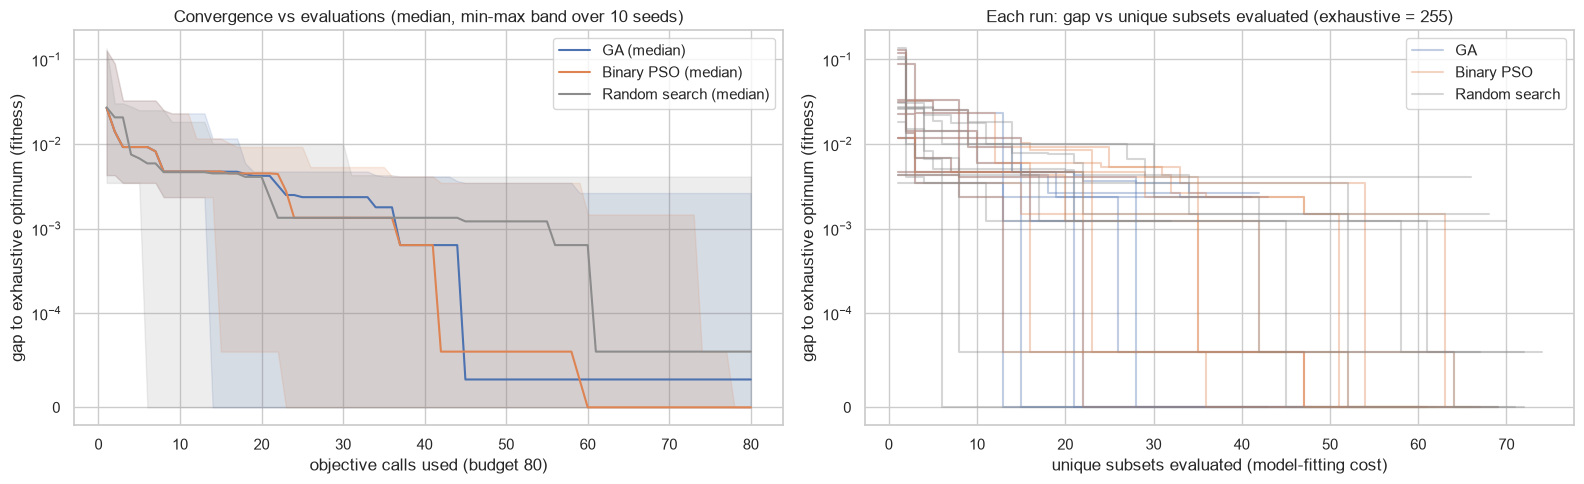

In [20]:
def mh_summary(df, opt_f, exh_unique=255, exh_seconds=None):
    def jacc(masks):
        ms = [np.array(m, bool) for m in masks]; vals = []
        for a, b in itertools.combinations(ms, 2):
            vals.append((a & b).sum() / (a | b).sum())
        return np.mean(vals)
    g = df.groupby('algorithm', sort=False)
    out = pd.DataFrame({
        'runs': g.size(), 'hit_rate_exact_optimum': g['hit_exact_optimum'].mean(),
        'mean_gap': g['gap_to_exact'].mean(), 'max_gap': g['gap_to_exact'].max(),
        'mean_cv_auc': g['cv_auc'].mean(), 'mean_size': g['size'].mean(),
        'mean_unique_subsets': g['unique_subsets'].mean(), 'mean_unique_at_best': g['unique_at_best'].mean(),
        'mean_seconds': g['seconds'].mean(), 'distinct_final_subsets': g['selected'].nunique(),
        'mean_pairwise_jaccard': g['mask'].apply(jacc)})
    out.loc['Exhaustive (exact)'] = [1, 1.0, 0.0, 0.0, np.nan, np.nan, exh_unique, np.nan, exh_seconds, 1, 1.0]
    return out

summ_lr = mh_summary(mh_lr, OPT_LR_F, exh_seconds=EXH_SECONDS_LR)
summ_lr.loc['Exhaustive (exact)', ['mean_cv_auc', 'mean_size']] = [obj_ex.cache[OPT_LR_MASK][0], sum(OPT_LR_MASK)]
display(summ_lr.round(4))
freq_lr = pd.DataFrame({alg: np.mean([m for m in mh_lr.loc[mh_lr.algorithm == alg, 'mask']], axis=0) for alg in SEARCHERS}, index=FEATURES)
freq_lr['exact optimum'] = OPT_LR_MASK
display(freq_lr.T.round(2).rename_axis('selection frequency across 10 seeds'))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
colors = {'GA': '#4C72B0', 'Binary PSO': '#DD8452', 'Random search': '#8C8C8C'}
for alg in SEARCHERS:
    T = np.array([traces_lr[(alg, s)][0] for s in range(10)]); U = np.array([traces_lr[(alg, s)][1] for s in range(10)])
    gap = OPT_LR_F - T
    x = np.arange(1, T.shape[1] + 1)
    axes[0].plot(x, np.median(gap, 0), color=colors[alg], label=f'{alg} (median)'); axes[0].fill_between(x, gap.min(0), gap.max(0), color=colors[alg], alpha=0.15)
    for s in range(10):
        axes[1].step(U[s], OPT_LR_F - T[s], where='post', color=colors[alg], alpha=0.35, label=alg if s == 0 else None)
for ax, xl in zip(axes, ['objective calls used (budget 80)', 'unique subsets evaluated (model-fitting cost)']):
    ax.set_xlabel(xl); ax.set_ylabel('gap to exhaustive optimum (fitness)'); ax.set_yscale('symlog', linthresh=1e-4); ax.legend()
axes[0].set_title('Convergence vs evaluations (median, min-max band over 10 seeds)'); axes[1].set_title('Each run: gap vs unique subsets evaluated (exhaustive = 255)')
plt.tight_layout(); plt.show()

### 8.2 Gradient-boosting objective: the original tree-based GA kept, now compared with PSO and the exact optimum

The original notebook's second GA used gradient-boosting fitness. The same estimator is kept here (100 trees, learning rate 0.05, depth 3). Its objective is deterministic, so all 255 subsets are evaluated once in parallel to get the exact optimum. GA, PSO and random search then query that table. Their answers are identical to live evaluation, and their cost is reported as unique subsets × the measured mean seconds per subset.

In [21]:
GB_FIT = lambda: GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=SEED)
t0 = time.perf_counter()
obj_gb_table = SubsetObjective(X_dev, y_dev, GB_FIT(), OUTER_FOLDS).precompute()
EXH_WALL_GB = time.perf_counter() - t0
sec_per_subset_gb = np.mean([v[1] for v in obj_gb_table.table.values()])
obj_gb_ex = run_exhaustive(obj_gb_table.fresh())
OPT_GB_F, OPT_GB_MASK = obj_gb_ex.best_f, obj_gb_ex.best_mask
print(f'GB exhaustive: wall {EXH_WALL_GB:.1f}s with {N_JOBS} workers; {sec_per_subset_gb:.2f}s per subset sequentially '
      f'(~{255 * sec_per_subset_gb:.0f}s for all 255 on one core)')
print(f'GB exact optimum F = {OPT_GB_F:.5f}, AUC = {obj_gb_ex.cache[OPT_GB_MASK][0]:.4f}: {obj_gb_ex.cols(OPT_GB_MASK)}')
print(f"GB all 8 features AUC = {obj_gb_table.table[(1,) * 8][0]:.4f}")

mh_gb, traces_gb = run_seeds(SEARCHERS, obj_gb_table.fresh, OPT_GB_F)
mh_gb['seconds'] = mh_gb['model_fit_seconds']        # sequential-equivalent cost of the subsets it requested
summ_gb = mh_summary(mh_gb, OPT_GB_F, exh_seconds=255 * sec_per_subset_gb)
summ_gb.loc['Exhaustive (exact)', ['mean_cv_auc', 'mean_size']] = [obj_gb_ex.cache[OPT_GB_MASK][0], sum(OPT_GB_MASK)]
display(mh_gb.drop(columns='mask').round(4))
display(summ_gb.round(4))
mh_gb.drop(columns='mask').to_csv(RESULTS / 'metaheuristics_gb_seeds.csv', index=False)

GB exhaustive: wall 14.6s with 18 workers; 0.78s per subset sequentially (~199s for all 255 on one core)
GB exact optimum F = 0.82290, AUC = 0.8329: ['Pregnancies', 'Glucose', 'Insulin', 'BMI', 'Age']
GB all 8 features AUC = 0.8239


,algorithm,seed,selected,size,fitness,cv_auc,gap_to_exact,hit_exact_optimum,calls,unique_subsets,call_of_best,unique_at_best,seconds,model_fit_seconds
0,GA,0,"Glucose, BMI, Age",3,0.8202,0.8262,0.0027,False,80,34,48,26,26.6397,26.6397
1,GA,1,"Pregnancies, Glucose, Insulin, BMI, Age",5,0.8229,0.8329,0.0000,True,80,50,66,45,40.5082,40.5082
2,GA,2,"Pregnancies, Glucose, Insulin, BMI, Age",5,0.8229,0.8329,0.0000,True,80,44,53,37,34.9549,34.9549
3,GA,3,"Pregnancies, Glucose, Insulin, BMI, Age",5,0.8229,0.8329,0.0000,True,80,51,47,31,41.4483,41.4483
4,GA,4,"Glucose, SkinThickness, Insulin, BMI, Age",5,0.8203,0.8303,0.0026,False,80,50,50,34,39.6782,39.6782
5,GA,5,"Pregnancies, Glucose, BloodPressure, Insulin, BMI, DiabetesPedigreeFunction,...",7,0.8208,0.8348,0.0021,False,80,53,47,35,42.8132,42.8132
6,GA,6,"Pregnancies, Glucose, Insulin, BMI",4,0.8133,0.8213,0.0096,False,80,39,10,10,31.5460,31.5460
7,GA,7,"Pregnancies, Glucose, Insulin, BMI, Age",5,0.8229,0.8329,0.0000,True,80,43,37,26,34.7759,34.7759
8,GA,8,"Glucose, BMI, Age",3,0.8202,0.8262,0.0027,False,80,43,47,33,32.6747,32.6747
9,GA,9,"Pregnancies, Glucose, BloodPressure, Insulin, BMI, DiabetesPedigreeFunction,...",7,0.8208,0.8348,0.0021,False,80,47,32,20,38.4009,38.4009


,runs,hit_rate_exact_optimum,mean_gap,max_gap,mean_cv_auc,mean_size,mean_unique_subsets,mean_unique_at_best,mean_seconds,distinct_final_subsets,mean_pairwise_jaccard
algorithm,,,,,,,,,,,
GA,10,0.4,0.0022,0.0096,0.8305,4.9,45.4,29.7,36.3440,5,0.6831
Binary PSO,10,0.6,0.0010,0.0027,0.8313,4.7,62.7,43.4,49.9393,4,0.7989
Random search,10,0.2,0.0024,0.0091,0.8299,4.7,69.8,32.0,54.3904,4,0.8069
Exhaustive (exact),1,1.0,0.0000,0.0000,0.8329,5.0,255.0,NaN,198.8402,1,1.0000


**How to read Section 8.** The exhaustive table is the ground truth for this objective. If GA or PSO reliably reaches gap 0, it found the optimum. Its cost is the number of unique subsets it evaluated, compared with 255 for exhaustive search. The random-search row shows whether either metaheuristic beats uninformed sampling at the same budget. The top-10 table shows how flat the landscape is: when many subsets sit within a few thousandths of AUC, "the" best subset is not a robust clinical finding. The nested evaluation in Section 9 measures whether searching actually improves held-out performance.

**Section 8 results (this run):**

* **Logistic-regression objective.** The exact optimum is {Pregnancies, Glucose, BMI, DiabetesPedigreeFunction}: CV AUC 0.8456, F = 0.8376, found by evaluating all 255 subsets in 13.5 s. **Binary PSO reached it in 10/10 seeds.** It evaluated on average 63 unique subsets (25% of the exhaustive cost) and first reached the optimum after about 48 unique evaluations, taking 3.3 s per run. **The GA reached it in 5/10 seeds** with 44 unique subsets per run (mean gap 0.0009, worst 0.0026). It converges faster but sometimes settles on a neighbouring subset. Random search with the same budget reached it in 4/10.
* **Gradient-boosting objective** (the original tree-GA). The exact optimum is {Pregnancies, Glucose, Insulin, BMI, Age}: CV AUC 0.833. PSO hit it in 6/10 seeds, the GA in 4/10 and random search in 2/10, each with roughly 45–70 unique subsets out of 255. Exhaustive search costs about 200 s on one core (15 s with 18 workers).
* **Landscape.** The top 10 LR subsets lie within 0.004 in fitness. Glucose, BMI and Pregnancies are in essentially every good subset. **Insulin and SkinThickness are never needed** for the LR objective once a measurement must earn 0.002 AUC. This reverses the historical claim that Insulin was "selected by every method", a claim that came from the label-derived insulin values. The GB objective does keep Insulin, but with only a small AUC gain.
* With only 255 subsets, exhaustive search is cheap and exact, so it is the right tool here. The metaheuristics are shown to work correctly and are compared fairly, but on 8 features they cannot beat exhaustive search on quality, only on cost.

## 9. Prediction comparison: all 8 features vs linear reduction vs nonlinear reduction vs selected features

Every representation is fitted inside each outer training fold of `OUTER_FOLDS`, with labels used only where the method is supervised (LDA, selection). It is then applied to the untouched validation fold.

* **Reference classifier, fixed in advance:** logistic regression. A compact grid over all 7 classifiers then checks whether the conclusions change with the model.
* **Nonlinear reductions with a valid out-of-sample transform:** Kernel PCA, Isomap, LLE and UMAP (UMAP's `transform` for validation patients). Each is fitted without labels, at 2 and 4 dimensions.
* **Excluded from prediction:** ordinary SNE, t-SNE and both MDS variants have no out-of-sample mapping. Embedding validation patients separately would give coordinates in an incompatible space, so these methods stay in the embedding comparison (Section 5).
* **Selected original features (metaheuristic, nested):** inside each outer training fold, exhaustive / GA / PSO searches run on **inner** 5-fold CV with the LR objective of Section 8 (seed 0, same budget). The chosen raw columns are then preprocessed and scored on the outer validation fold. The tree-GA (GB objective) is included the same way.

In [22]:
class RawSubsetSearch(BaseEstimator, TransformerMixin):
    # Supervised raw-column subset search on INNER CV of the data it is fitted on; then preprocess only those columns.
    def __init__(self, search='exhaustive', estimator='lr', penalty=0.002, seed=0, precompute=False, ga_kwargs=None):
        self.search, self.estimator, self.penalty, self.seed, self.precompute, self.ga_kwargs = search, estimator, penalty, seed, precompute, ga_kwargs
    def fit(self, X, y):
        est = LR_REF() if self.estimator == 'lr' else GB_FIT()
        obj = SubsetObjective(X, y, est, list(inner_cv().split(X, y)), self.penalty)
        if self.precompute or self.search == 'exhaustive':
            obj.precompute()
        fn = {'exhaustive': run_exhaustive, 'ga': run_ga, 'pso': run_bpso}[self.search]
        fn(obj, np.random.default_rng(self.seed), **(self.ga_kwargs or {})) if self.search == 'ga' else fn(obj, np.random.default_rng(self.seed))
        self.subset_ = obj.cols(obj.best_mask)
        self.search_info_ = {'inner_fitness': obj.best_f, 'unique_subsets': len(obj.cache)}
        self.pre_ = make_preprocessor(self.subset_).fit(X)
        return self
    def fit_transform(self, X, y):
        return self.fit(X, y).transform(X)
    def transform(self, X):
        return self.pre_.transform(X)

def red(reducer_factory, supervised=False):
    return lambda: Pipeline([('pre', make_preprocessor()),
                             ('reduce', reducer_factory() if supervised else Unsupervised(reducer_factory()))])

LINEAR_REPS = {
    'Linear: PCA (2)': red(lambda: PCA(2, random_state=SEED)),
    'Linear: PCA (4)': red(lambda: PCA(4, random_state=SEED)),
    'Linear: Truncated SVD (2)': red(lambda: TruncatedSVD(2, random_state=SEED)),
    'Linear: Truncated SVD (4)': red(lambda: TruncatedSVD(4, random_state=SEED)),
    'Linear: LDA (1, supervised)': red(lambda: LinearDiscriminantAnalysis(n_components=1), supervised=True),
}
NONLINEAR_REPS = {}
for d in (2, 4):
    NONLINEAR_REPS[f'Nonlinear: Kernel PCA RBF ({d})'] = red(lambda d=d: KernelPCA(d, kernel='rbf', gamma=0.1, random_state=SEED))
    NONLINEAR_REPS[f'Nonlinear: Isomap ({d})'] = red(lambda d=d: Isomap(n_components=d, n_neighbors=15))
    NONLINEAR_REPS[f'Nonlinear: LLE ({d})'] = red(lambda d=d: LocallyLinearEmbedding(n_components=d, n_neighbors=15, reg=1e-3, eigen_solver='dense', random_state=SEED))
    NONLINEAR_REPS[f'Nonlinear: UMAP ({d})'] = red(lambda d=d: umap.UMAP(n_components=d, n_neighbors=15, min_dist=0.1, random_state=SEED))
META_REPS = {
    'Selected raw: exhaustive (LR objective)': lambda: RawSubsetSearch('exhaustive', 'lr'),
    'Selected raw: GA (LR objective)': lambda: RawSubsetSearch('ga', 'lr'),
    'Selected raw: binary PSO (LR objective)': lambda: RawSubsetSearch('pso', 'lr'),
    'Selected raw: GA (GB objective, tree-GA)': lambda: RawSubsetSearch('ga', 'gb', precompute=True),
}
ALL_REPS = {**REPS_BASE, **LINEAR_REPS, **NONLINEAR_REPS, **SELECTION_REPS, **META_REPS}
REP_FAMILY = {r: ('All 8' if r == ALL8 else r.split(':')[0].replace('Selected raw', 'Metaheuristic / exhaustive (raw)')) for r in ALL_REPS}

t0 = time.perf_counter()
with warnings.catch_warnings():
    warnings.simplefilter('ignore', FutureWarning)
    res_grid, oof_grid, info_grid = cv_grid(ALL_REPS, CLASSIFIERS)
print(f'Representation grid: {time.perf_counter() - t0:.0f}s')
sum_grid = summarize(res_grid); sum_grid['family'] = sum_grid['representation'].map(REP_FAMILY)
sum_grid.to_csv(RESULTS / 'representation_x_classifier_cv.csv', index=False)
res_grid.to_csv(RESULTS / 'representation_x_classifier_folds.csv', index=False)

  All 8 original features                       done in    2.7s


  Linear: PCA (2)                               done in    2.5s


  Linear: PCA (4)                               done in    2.6s


  Linear: Truncated SVD (2)                     done in    2.5s


  Linear: Truncated SVD (4)                     done in    2.6s


  Linear: LDA (1, supervised)                   done in    2.3s


... (15 outputs left out)

  Selected raw: exhaustive (LR objective)       done in   10.5s


  Selected raw: GA (LR objective)               done in   11.6s


  Selected raw: binary PSO (LR objective)       done in   17.8s


  Selected raw: GA (GB objective, tree-GA)      done in   58.7s
Representation grid: 168s


In [23]:
# (a) Reference classifier: logistic regression, all representations on identical folds.
ref = res_grid[res_grid.classifier == 'Logistic Regression']
base_auc = ref[ref.representation == ALL8].set_index('fold')['roc_auc']
base_acc = ref[ref.representation == ALL8].set_index('fold')['accuracy']
rows = []
for r, g in ref.groupby('representation', sort=False):
    d_auc = g.set_index('fold')['roc_auc'] - base_auc
    d_acc = g.set_index('fold')['accuracy'] - base_acc
    rows.append({'representation': r, 'family': REP_FAMILY[r], 'dims': g['n_dims'].mean(),
                 'cv_roc_auc': g['roc_auc'].mean(), 'auc_sd': g['roc_auc'].std(), 'cv_accuracy': g['accuracy'].mean(),
                 'delta_auc_vs_all8': d_auc.mean(), 'delta_auc_sd': d_auc.std(), 'folds_better_auc': int((d_auc > 0).sum()),
                 'delta_acc_vs_all8': d_acc.mean(), 'train_roc_auc': g['train_roc_auc'].mean()})
ref_table = pd.DataFrame(rows).sort_values('cv_roc_auc', ascending=False).reset_index(drop=True)
display(ref_table.round(4))
ref_table.to_csv(RESULTS / 'reference_lr_comparison.csv', index=False)

fam_best = ref_table.groupby('family').apply(lambda g: g.loc[g.cv_roc_auc.idxmax(), ['representation', 'cv_roc_auc', 'delta_auc_vs_all8', 'folds_better_auc']], include_groups=False)
display(fam_best.round(4).rename_axis('best per family (LR reference)'))

,representation,family,dims,cv_roc_auc,auc_sd,cv_accuracy,delta_auc_vs_all8,delta_auc_sd,folds_better_auc,delta_acc_vs_all8,train_roc_auc
0,Selected raw: binary PSO (LR objective),Metaheuristic / exhaustive (raw),4.2,0.8458,0.0153,0.7915,0.0022,0.0032,4,0.0032,0.8505
1,"Selected raw: GA (GB objective, tree-GA)",Metaheuristic / exhaustive (raw),4.0,0.8444,0.0186,0.7898,0.0007,0.0060,3,0.0016,0.8467
2,Embedded: L1 (non-zero),Embedded,7.0,0.8439,0.0160,0.7866,0.0002,0.0015,1,-0.0016,0.8517
3,Wrapper: forward SFS (tol 0.002),Wrapper,4.0,0.8438,0.0200,0.7931,0.0001,0.0046,3,0.0049,0.8502
4,Wrapper: backward SFS (tol -0.002),Wrapper,3.8,0.8437,0.0199,0.7964,0.0001,0.0045,3,0.0081,0.8498
5,All 8 original features,All 8,8.0,0.8436,0.0172,0.7882,0.0000,0.0000,0,0.0000,0.8516
6,Selected raw: exhaustive (LR objective),Metaheuristic / exhaustive (raw),4.4,0.8435,0.0199,0.7899,-0.0002,0.0053,3,0.0016,0.8505
7,Wrapper: RFECV,Wrapper,6.4,0.8434,0.0152,0.7866,-0.0002,0.0021,1,-0.0016,0.8517
8,Embedded: Elastic Net (non-zero),Embedded,7.0,0.8433,0.0151,0.7882,-0.0003,0.0021,1,0.0000,0.8518
9,"Linear: LDA (1, supervised)",Linear,1.0,0.8423,0.0189,0.7866,-0.0014,0.0022,1,-0.0016,0.8514


,representation,cv_roc_auc,delta_auc_vs_all8,folds_better_auc
best per family (LR reference),,,,
All 8,All 8 original features,0.8436,0.0000,0
Embedded,Embedded: L1 (non-zero),0.8439,0.0002,1
Filter,Filter: mutual information (k by inner CV),0.8417,-0.0019,1
Linear,"Linear: LDA (1, supervised)",0.8423,-0.0014,1
Metaheuristic / exhaustive (raw),Selected raw: binary PSO (LR objective),0.8458,0.0022,4
Nonlinear,Nonlinear: Isomap (4),0.8295,-0.0141,1
Wrapper,Wrapper: forward SFS (tol 0.002),0.8438,0.0001,3


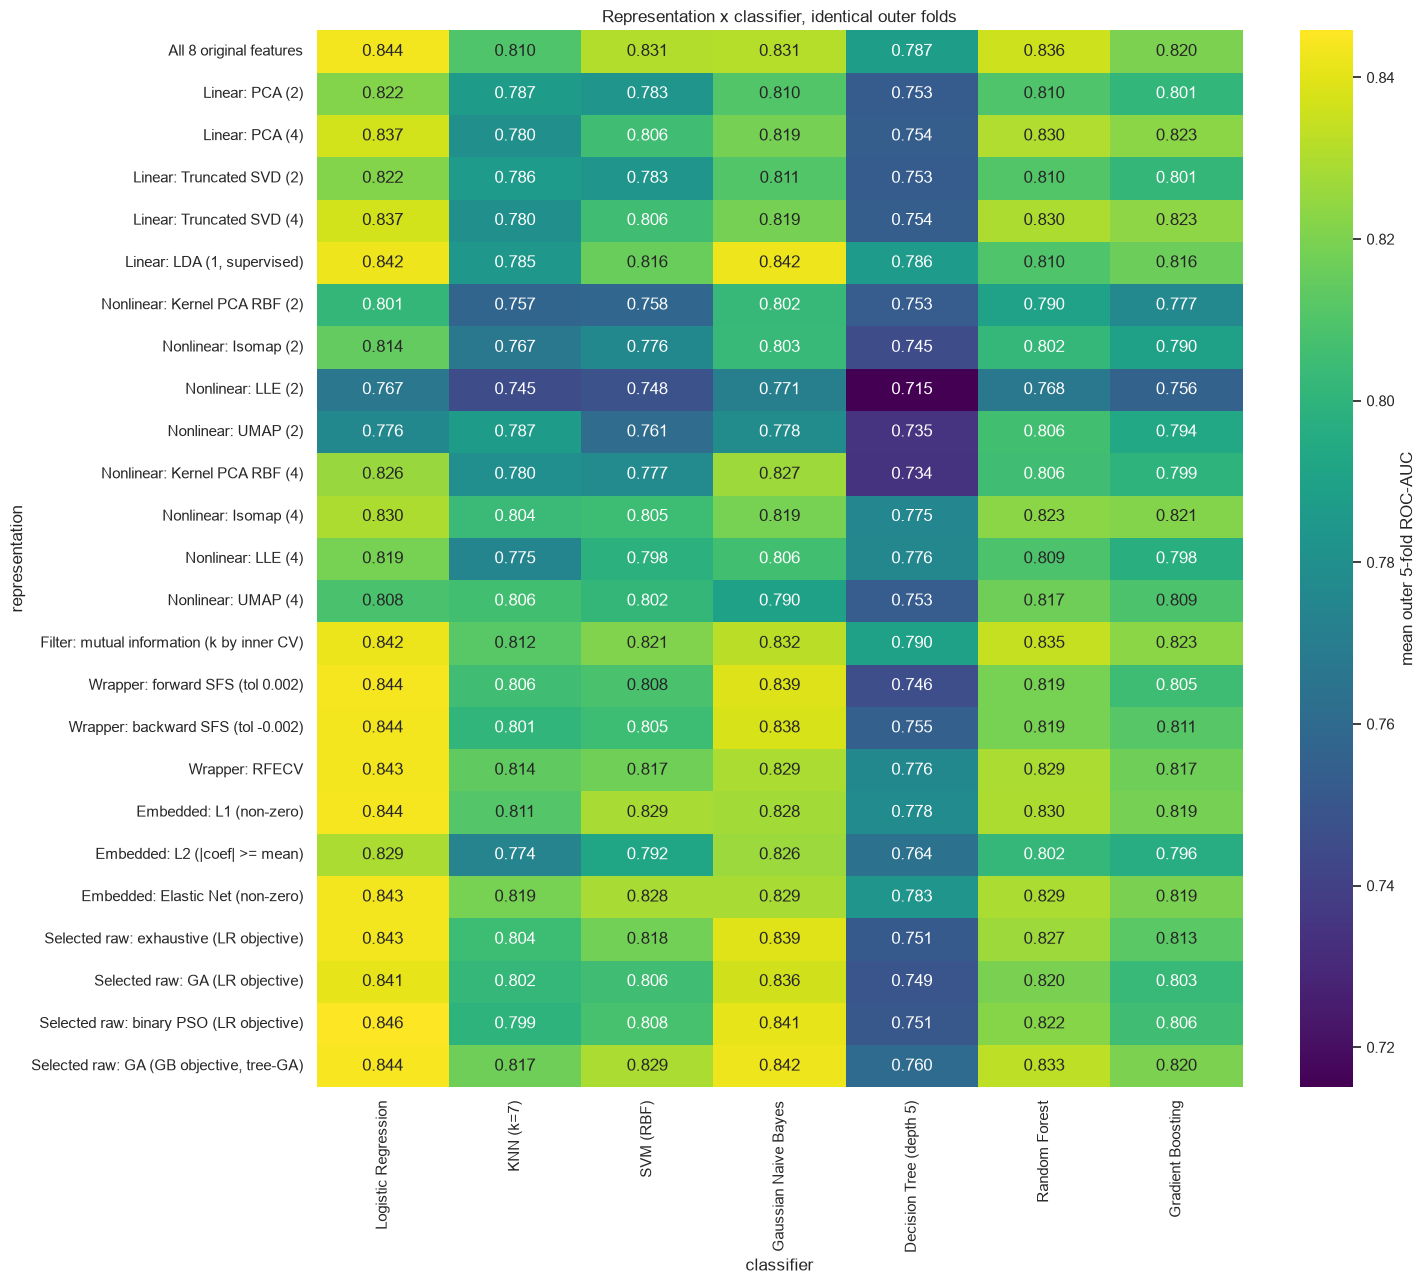

,All 8 AUC,All 8 accuracy,rank of All 8 (of 25),best linear - All 8,best nonlinear - All 8,best nonlinear,best filter/wrapper/embedded - All 8,best metaheuristic/exhaustive - All 8,overall best representation
classifier,,,,,,,,,
Logistic Regression,0.8436,0.7882,6,-0.0014,-0.0141,Nonlinear: Isomap (4),0.0002,0.0022,Selected raw: binary PSO (LR objective)
KNN (k=7),0.8096,0.7540,6,-0.0229,-0.0035,Nonlinear: UMAP (4),0.0095,0.0072,Embedded: Elastic Net (non-zero)
SVM (RBF),0.8306,0.7638,1,-0.0146,-0.0261,Nonlinear: Isomap (4),-0.0019,-0.0013,All 8 original features
Gaussian Naive Bayes,0.8310,0.7574,9,0.0112,-0.0042,Nonlinear: Kernel PCA RBF (4),0.0077,0.0113,"Selected raw: GA (GB objective, tree-GA)"
Decision Tree (depth 5),0.7872,0.7525,2,-0.0011,-0.0116,Nonlinear: LLE (4),0.0024,-0.0270,Filter: mutual information (k by inner CV)
Random Forest,0.8358,0.7671,1,-0.0055,-0.0127,Nonlinear: Isomap (4),-0.0013,-0.0030,All 8 original features
Gradient Boosting,0.8202,0.7524,5,0.0032,0.0012,Nonlinear: Isomap (4),0.0029,-0.0002,Linear: Truncated SVD (4)


In [24]:
# (b) Do conclusions change with the classifier? Mean CV ROC-AUC for every representation x classifier.
piv = sum_grid.pivot(index='representation', columns='classifier', values='cv_roc_auc_mean').reindex(index=list(ALL_REPS), columns=list(CLASSIFIERS))
fig, ax = plt.subplots(figsize=(15, 13))
sns.heatmap(piv, annot=True, fmt='.3f', cmap='viridis', ax=ax, cbar_kws={'label': 'mean outer 5-fold ROC-AUC'})
ax.set_title('Representation x classifier, identical outer folds'); plt.tight_layout(); plt.show()

piv_acc = sum_grid.pivot(index='representation', columns='classifier', values='cv_accuracy_mean').reindex(index=list(ALL_REPS), columns=list(CLASSIFIERS))
per_clf = []
for c in CLASSIFIERS:
    col = piv[c]
    fam = pd.Series(REP_FAMILY)
    def best_of(f):
        s = col[fam[fam == f].index]; return s.idxmax(), s.max()
    nl_name, nl = best_of('Nonlinear'); li_name, li = best_of('Linear')
    me_name, me = best_of('Metaheuristic / exhaustive (raw)')
    fs = col[[r for r in SELECTION_REPS]].max()
    per_clf.append({'classifier': c, 'All 8 AUC': col[ALL8], 'All 8 accuracy': piv_acc.loc[ALL8, c],
                    'rank of All 8 (of %d)' % len(col): int(col.rank(ascending=False)[ALL8]),
                    'best linear - All 8': li - col[ALL8], 'best nonlinear - All 8': nl - col[ALL8], 'best nonlinear': nl_name,
                    'best filter/wrapper/embedded - All 8': fs - col[ALL8],
                    'best metaheuristic/exhaustive - All 8': me - col[ALL8], 'overall best representation': col.idxmax()})
per_clf = pd.DataFrame(per_clf).set_index('classifier')
display(per_clf.round(4))
per_clf.to_csv(RESULTS / 'per_classifier_summary.csv')

fold,1,2,3,4,5
representation,,,,,
Embedded: Elastic Net (non-zero),"Pregnancies, Glucose, SkinThickness, Insulin, BMI, DiabetesPedigreeFunction,...","Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, DiabetesPe...","Pregnancies, Glucose, BloodPressure, Insulin, BMI, DiabetesPedigreeFunction,...","Pregnancies, Glucose, BloodPressure, SkinThickness, BMI, DiabetesPedigreeFun...","Pregnancies, Glucose, SkinThickness, BMI, DiabetesPedigreeFunction, Age"
Embedded: L1 (non-zero),"Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, DiabetesPe...","Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, DiabetesPe...","Pregnancies, Glucose, Insulin, BMI, DiabetesPedigreeFunction, Age","Pregnancies, Glucose, BloodPressure, SkinThickness, BMI, DiabetesPedigreeFun...","Pregnancies, Glucose, SkinThickness, BMI, DiabetesPedigreeFunction, Age"
Embedded: L2 (|coef| >= mean),"Glucose, BMI","Glucose, BMI","Pregnancies, Glucose, BMI","Glucose, BMI","Glucose, BMI"
Filter: mutual information (k by inner CV),"Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, DiabetesPe...","Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, DiabetesPe...","Pregnancies, Glucose, BloodPressure, Insulin, BMI, DiabetesPedigreeFunction,...","Pregnancies, Glucose, SkinThickness, Insulin, BMI, DiabetesPedigreeFunction,...","Pregnancies, Glucose, Insulin, BMI"
"Selected raw: GA (GB objective, tree-GA)","Glucose, BMI, DiabetesPedigreeFunction, Age","Glucose, BMI, DiabetesPedigreeFunction, Age","Glucose, BMI, DiabetesPedigreeFunction, Age","Glucose, BMI, DiabetesPedigreeFunction, Age","Glucose, BMI, DiabetesPedigreeFunction, Age"
Selected raw: GA (LR objective),"Pregnancies, Glucose, BMI, DiabetesPedigreeFunction","Pregnancies, Glucose, BMI, DiabetesPedigreeFunction, Age","Pregnancies, Glucose, BMI, DiabetesPedigreeFunction","Glucose, BMI, DiabetesPedigreeFunction, Age","Pregnancies, Glucose, BMI"
Selected raw: binary PSO (LR objective),"Pregnancies, Glucose, BMI, DiabetesPedigreeFunction","Pregnancies, Glucose, BMI, DiabetesPedigreeFunction","Pregnancies, Glucose, BMI, DiabetesPedigreeFunction","Pregnancies, Glucose, BMI, DiabetesPedigreeFunction, Age","Pregnancies, Glucose, BMI, DiabetesPedigreeFunction"
Selected raw: exhaustive (LR objective),"Pregnancies, Glucose, BMI, DiabetesPedigreeFunction, Age","Pregnancies, Glucose, BMI, DiabetesPedigreeFunction, Age","Pregnancies, Glucose, BMI, DiabetesPedigreeFunction","Pregnancies, Glucose, BMI, DiabetesPedigreeFunction, Age","Pregnancies, Glucose, BMI"
Wrapper: RFECV,"Pregnancies, Glucose, SkinThickness, Insulin, BMI, DiabetesPedigreeFunction,...","Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, DiabetesPe...","Pregnancies, Glucose, BMI, DiabetesPedigreeFunction, Age","Pregnancies, Glucose, BloodPressure, SkinThickness, BMI, DiabetesPedigreeFun...","Pregnancies, Glucose, SkinThickness, BMI, DiabetesPedigreeFunction"


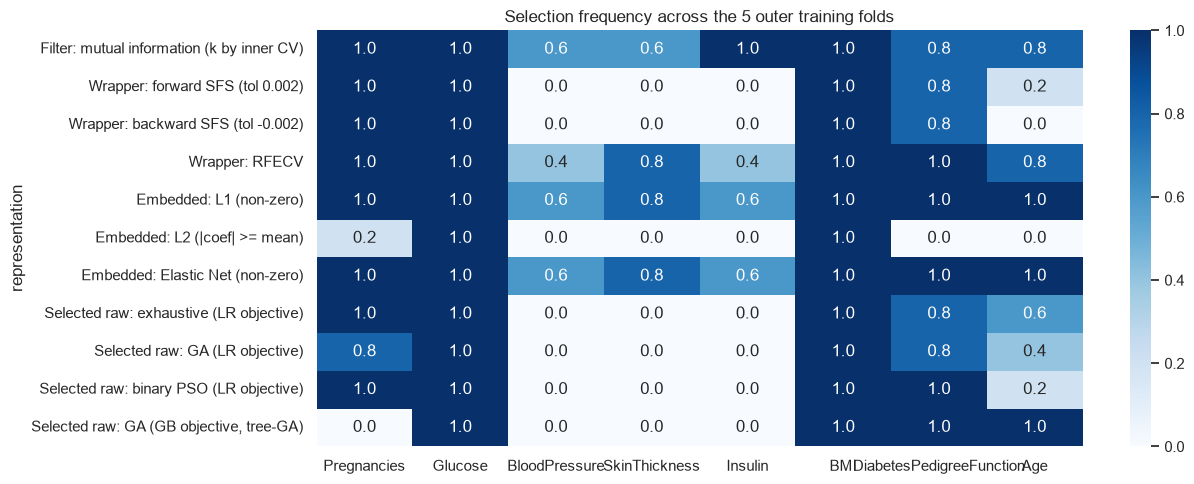

,search,outer fold,selected,exhaustive optimum,gap to inner optimum,hit,unique subsets
0,GA (LR objective),1,"Pregnancies, Glucose, BMI, DiabetesPedigreeFunction","Pregnancies, Glucose, BMI, DiabetesPedigreeFunction, Age",0.0002,False,40
1,GA (LR objective),2,"Pregnancies, Glucose, BMI, DiabetesPedigreeFunction, Age","Pregnancies, Glucose, BMI, DiabetesPedigreeFunction, Age",0.0000,True,35
2,GA (LR objective),3,"Pregnancies, Glucose, BMI, DiabetesPedigreeFunction","Pregnancies, Glucose, BMI, DiabetesPedigreeFunction",0.0000,True,40
3,GA (LR objective),4,"Glucose, BMI, DiabetesPedigreeFunction, Age","Pregnancies, Glucose, BMI, DiabetesPedigreeFunction, Age",0.0007,False,32
4,GA (LR objective),5,"Pregnancies, Glucose, BMI","Pregnancies, Glucose, BMI",0.0000,True,41
5,binary PSO (LR objective),1,"Pregnancies, Glucose, BMI, DiabetesPedigreeFunction","Pregnancies, Glucose, BMI, DiabetesPedigreeFunction, Age",0.0002,False,60
6,binary PSO (LR objective),2,"Pregnancies, Glucose, BMI, DiabetesPedigreeFunction","Pregnancies, Glucose, BMI, DiabetesPedigreeFunction, Age",0.0015,False,57
7,binary PSO (LR objective),3,"Pregnancies, Glucose, BMI, DiabetesPedigreeFunction","Pregnancies, Glucose, BMI, DiabetesPedigreeFunction",0.0000,True,60
8,binary PSO (LR objective),4,"Pregnancies, Glucose, BMI, DiabetesPedigreeFunction, Age","Pregnancies, Glucose, BMI, DiabetesPedigreeFunction, Age",0.0000,True,55
9,binary PSO (LR objective),5,"Pregnancies, Glucose, BMI, DiabetesPedigreeFunction","Pregnancies, Glucose, BMI",0.0027,False,66


                           hit  unique subsets  gap to inner optimum
search                                                              
GA (LR objective)          0.6            37.6                0.0002
binary PSO (LR objective)  0.4            59.6                0.0009


In [25]:
# (c) Which raw columns did the nested searches choose in each outer fold? (stability of selection)
sel_rows = info_grid[info_grid.selected.notna()].copy()
sel_rows['selected'] = sel_rows['selected'].apply(lambda s: ', '.join(s))
display(sel_rows.pivot(index='representation', columns='fold', values='selected'))
freq = (info_grid[info_grid.selected.notna()]
        .assign(**{f: lambda d, f=f: d['selected'].apply(lambda s: f in s) for f in FEATURES})
        .groupby('representation')[FEATURES].mean())
fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(freq.reindex([r for r in list(SELECTION_REPS) + list(META_REPS)]), annot=True, fmt='.1f', cmap='Blues', vmin=0, vmax=1, ax=ax)
ax.set_title('Selection frequency across the 5 outer training folds'); plt.tight_layout(); plt.show()

# (d) Inside each outer fold, did GA / PSO reach the exhaustive optimum of the SAME inner-CV objective?
ex = info_grid[info_grid.representation == 'Selected raw: exhaustive (LR objective)'].set_index('fold')
nest = []
for r in ['Selected raw: GA (LR objective)', 'Selected raw: binary PSO (LR objective)']:
    d = info_grid[info_grid.representation == r].set_index('fold')
    for k in d.index:
        gap = ex.loc[k, 'extra']['inner_fitness'] - d.loc[k, 'extra']['inner_fitness']
        nest.append({'search': r.split(': ')[1], 'outer fold': k, 'selected': ', '.join(d.loc[k, 'selected']),
                     'exhaustive optimum': ', '.join(ex.loc[k, 'selected']), 'gap to inner optimum': gap,
                     'hit': abs(gap) < 1e-12, 'unique subsets': d.loc[k, 'extra']['unique_subsets']})
nest = pd.DataFrame(nest)
display(nest.round(5))
print(nest.groupby('search')[['hit', 'unique subsets', 'gap to inner optimum']].mean().round(4))

**Section 9 results (this run). Did nonlinear reduction improve prediction over all 8 features? No.**

* **Reference classifier (logistic regression).** All 8 features give mean 5-fold AUC 0.844 and accuracy 0.788. The best nonlinear representation, Isomap (4), loses 0.014 AUC and 2.3 accuracy points. UMAP (2) loses 0.068 AUC and LLE (2) loses 0.077. LLE is unstable: in some folds its output collapses so that predictions fall to the majority class (accuracy 0.653). No nonlinear representation beats all 8 features in more than 1 of the 5 folds. Linear reductions also lose (PCA-4: −0.007; PCA-2: −0.022), and supervised 1-D LDA ties (−0.001).
* **Across all 7 classifiers** the conclusion does not change. The best nonlinear representation changes AUC relative to all 8 features by −0.026 (SVM) to +0.001 (gradient boosting with Isomap-4). Fold-to-fold noise is about 0.015–0.02.
* **Selected original features** tie with all 8 features for logistic regression (−0.003 to +0.002 AUC). The raw-column searches do this with **4.0–4.4 measurements instead of 8**. The filter/wrapper/embedded methods select after imputation, so they still need all 8 measurements. Subsets are model-specific: an LR-chosen subset costs the decision tree 0.027 AUC.
* **Nested search quality (table d).** With one seed and 80 calls inside each outer fold, the GA reached the inner-CV exhaustive optimum in 3/5 folds (about 38 unique subsets) and PSO in 2/5 (about 60 unique subsets). Every miss is within 0.003 of the optimum and differs by one feature (Age or DiabetesPedigreeFunction). Exhaustive search, which is always exact, scored 0.8435 outer AUC, while the PSO pipeline scored 0.8458. **Optimising the inner objective more exactly did not improve held-out performance**: differences of this size are noise.

## 10. Nested hyperparameter tuning

Five of the classifiers are tuned with `GridSearchCV` on inner 5-fold CV, scored by ROC-AUC. The **whole pipeline**, preprocessing included, sits inside the grid search, so the inner validation folds are imputed without information from each other. The outer folds are again `OUTER_FOLDS`.

**Historical-pipeline replica.** The tree-GA subset is re-searched inside every outer fold, then gradient boosting is tuned on the historical 108-point grid. This gives an honest estimate of the pipeline behind the old 87.8% / 0.942 result.

In [26]:
def tuned(clf, grid):
    return lambda: GridSearchCV(Pipeline([('pre', make_preprocessor()), ('clf', clf)]),
                                {f'clf__{k}': v for k, v in grid.items()}, scoring='roc_auc', cv=inner_cv(), n_jobs=N_JOBS)
HIST_GB_GRID = {'n_estimators': [100, 150, 250], 'learning_rate': [0.03, 0.05, 0.1], 'max_depth': [2, 3, 4],
                'subsample': [0.8, 1.0], 'min_samples_leaf': [3, 5]}
TUNED = {
    'Logistic Regression (tuned C)': tuned(LogisticRegression(max_iter=2000), {'C': list(np.logspace(-3, 2, 11))}),
    'KNN (tuned)': tuned(KNeighborsClassifier(), {'n_neighbors': [5, 7, 9, 11, 15, 21, 31], 'weights': ['uniform', 'distance']}),
    'SVM RBF (tuned)': tuned(SVC(kernel='rbf', probability=True, random_state=SEED), {'C': [0.1, 0.3, 1, 3, 10], 'gamma': ['scale', 0.01, 0.03, 0.1]}),
    'Random Forest (tuned)': tuned(RandomForestClassifier(n_estimators=300, random_state=SEED),
                                   {'max_depth': [3, 5, 8, None], 'min_samples_leaf': [1, 3, 5, 10], 'max_features': ['sqrt', 0.5]}),
    'Gradient Boosting (tuned)': tuned(GradientBoostingClassifier(random_state=SEED), HIST_GB_GRID),
}
RAW = 'Raw columns (preprocessing inside tuned pipeline)'
t0 = time.perf_counter()
res_tuned, oof_tuned, _ = cv_grid({RAW: lambda: ColumnSubset()}, TUNED)
HIST = 'Historical replica: tree-GA subset (nested)'
res_hist, oof_hist, info_hist = cv_grid(
    {HIST: lambda: RawSubsetSearch('ga', 'gb', penalty=0.001, precompute=True, seed=SEED, ga_kwargs={'pop_size': 16, 'n_gen': 12, 'mut_rate': 0.12})},
    {'Gradient Boosting (tuned, historical grid)': lambda: GridSearchCV(GradientBoostingClassifier(random_state=SEED), HIST_GB_GRID, scoring='roc_auc', cv=inner_cv(), n_jobs=N_JOBS)})
print(f'Nested tuning: {time.perf_counter() - t0:.0f}s')
sum_tuned = summarize(pd.concat([res_tuned, res_hist]))
display(sum_tuned.round(4))
display(res_tuned.pivot(index='classifier', columns='fold', values='best_params'))
print('Historical replica, tree-GA subsets per outer fold:', [', '.join(s) for s in info_hist['selected']])

  Raw columns (preprocessing inside tuned pipeline) done in   86.7s


  Historical replica: tree-GA subset (nested)   done in  102.3s
Nested tuning: 189s


,representation,classifier,n_dims,cv_accuracy_mean,cv_accuracy_sd,cv_roc_auc_mean,cv_roc_auc_sd,cv_f1_mean,cv_recall_mean,cv_precision_mean,train_accuracy_mean,train_roc_auc_mean,auc_gap_train_minus_cv
0,Raw columns (preprocessing inside tuned pipeline),Logistic Regression (tuned C),8.0,0.7866,0.0204,0.8444,0.0126,0.6548,0.5796,0.7561,0.7891,0.8517,0.0074
1,Raw columns (preprocessing inside tuned pipeline),KNN (tuned),8.0,0.7573,0.0300,0.8296,0.0254,0.6077,0.5377,0.7138,1.0000,1.0000,0.1704
2,Raw columns (preprocessing inside tuned pipeline),SVM RBF (tuned),8.0,0.7866,0.0136,0.8440,0.0134,0.6563,0.5843,0.7545,0.8013,0.8681,0.0242
3,Raw columns (preprocessing inside tuned pipeline),Random Forest (tuned),8.0,0.7753,0.0231,0.8372,0.0122,0.6362,0.5656,0.7430,0.8400,0.9181,0.0809
4,Raw columns (preprocessing inside tuned pipeline),Gradient Boosting (tuned),8.0,0.7703,0.0229,0.8342,0.0139,0.6415,0.5889,0.7099,0.8367,0.9224,0.0881
5,Historical replica: tree-GA subset (nested),"Gradient Boosting (tuned, historical grid)",5.0,0.7589,0.0138,0.8290,0.0264,0.6336,0.5981,0.6771,0.8807,0.9435,0.1145


fold,1,2,3,4,5
classifier,,,,,
Gradient Boosting (tuned),"{'clf__learning_rate': 0.05, 'clf__max_depth': 2, 'clf__min_samples_leaf': 5...","{'clf__learning_rate': 0.03, 'clf__max_depth': 2, 'clf__min_samples_leaf': 3...","{'clf__learning_rate': 0.03, 'clf__max_depth': 2, 'clf__min_samples_leaf': 3...","{'clf__learning_rate': 0.05, 'clf__max_depth': 2, 'clf__min_samples_leaf': 3...","{'clf__learning_rate': 0.05, 'clf__max_depth': 2, 'clf__min_samples_leaf': 3..."
KNN (tuned),"{'clf__n_neighbors': 31, 'clf__weights': 'distance'}","{'clf__n_neighbors': 31, 'clf__weights': 'distance'}","{'clf__n_neighbors': 31, 'clf__weights': 'distance'}","{'clf__n_neighbors': 21, 'clf__weights': 'distance'}","{'clf__n_neighbors': 31, 'clf__weights': 'distance'}"
Logistic Regression (tuned C),{'clf__C': np.float64(0.1)},{'clf__C': np.float64(0.1)},{'clf__C': np.float64(0.31622776601683794)},{'clf__C': np.float64(0.1)},{'clf__C': np.float64(0.1)}
Random Forest (tuned),"{'clf__max_depth': 3, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 1}","{'clf__max_depth': 5, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 3}","{'clf__max_depth': 3, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 1}","{'clf__max_depth': 8, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 5}","{'clf__max_depth': 3, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 3}"
SVM RBF (tuned),"{'clf__C': 3, 'clf__gamma': 0.01}","{'clf__C': 3, 'clf__gamma': 0.03}","{'clf__C': 1, 'clf__gamma': 0.01}","{'clf__C': 3, 'clf__gamma': 0.03}","{'clf__C': 3, 'clf__gamma': 0.01}"


Historical replica, tree-GA subsets per outer fold: ['Glucose, Insulin, BMI, Age', 'Pregnancies, Glucose, Insulin, BMI, DiabetesPedigreeFunction, Age', 'Pregnancies, Glucose, Insulin, BMI, DiabetesPedigreeFunction, Age', 'Glucose, BMI, DiabetesPedigreeFunction, Age', 'Pregnancies, Glucose, BMI, DiabetesPedigreeFunction, Age']


## 11. Leaderboard, finalist and screening threshold, locked on development data only

The leaderboard combines every pipeline scored on the identical outer folds. The finalist rule and the threshold rule are the ones fixed in Section 0. The pipelines that cannot be distinguished from the winner (within one standard error of its fold AUCs) are listed as well. Selecting the maximum of many CV means is itself optimistic, which is one reason the test set exists.

In [27]:
res_all = pd.concat([res_grid, res_tuned, res_hist], ignore_index=True)
oof_all = {**oof_grid, **oof_tuned, **oof_hist}
lb = summarize(res_all)
raw_needed = {r: 8 for r in lb.representation.unique()}
for r in list(META_REPS) + [HIST]:
    sel = pd.concat([info_grid, info_hist])
    raw_needed[r] = sel.loc[sel.representation == r, 'selected'].apply(len).mean()
lb['raw_measurements_needed'] = lb['representation'].map(raw_needed)
COMPLEXITY = {c: i for i, c in enumerate(['Logistic Regression', 'Logistic Regression (tuned C)', 'Gaussian Naive Bayes', 'KNN (k=7)', 'KNN (tuned)',
                                          'Decision Tree (depth 5)', 'SVM (RBF)', 'SVM RBF (tuned)', 'Random Forest', 'Random Forest (tuned)',
                                          'Gradient Boosting', 'Gradient Boosting (tuned)', 'Gradient Boosting (tuned, historical grid)'])}
lb['complexity_rank'] = lb['classifier'].map(COMPLEXITY)
lb = lb.sort_values('cv_roc_auc_mean', ascending=False).reset_index(drop=True)
top = lb.iloc[0]
ties = lb[lb.cv_roc_auc_mean >= top.cv_roc_auc_mean - 0.001].sort_values(['raw_measurements_needed', 'complexity_rank'])
FINAL = ties.iloc[0]
FINAL_REP, FINAL_CLF = FINAL['representation'], FINAL['classifier']
se = res_all[(res_all.representation == top.representation) & (res_all.classifier == top.classifier)]['roc_auc'].std() / np.sqrt(5)
one_se = lb[lb.cv_roc_auc_mean >= top.cv_roc_auc_mean - se]
cols = ['representation', 'classifier', 'n_dims', 'raw_measurements_needed', 'cv_roc_auc_mean', 'cv_roc_auc_sd', 'cv_accuracy_mean',
        'cv_accuracy_sd', 'cv_recall_mean', 'cv_f1_mean', 'train_roc_auc_mean', 'auc_gap_train_minus_cv']
print(f'{len(lb)} pipelines on identical folds. Top 15 by mean outer-CV ROC-AUC:')
display(lb[cols].head(15).round(4))
lb[cols].to_csv(RESULTS / 'leaderboard.csv', index=False)
print(f'One-SE band (SE = {se:.4f}): {len(one_se)} pipelines are statistically indistinguishable from the top.')
print(f'\nFINALIST (locked): {FINAL_REP}  |  {FINAL_CLF}')
print(f"  mean 5-fold ROC-AUC {FINAL['cv_roc_auc_mean']:.4f} +/- {FINAL['cv_roc_auc_sd']:.4f}, mean 5-fold accuracy {FINAL['cv_accuracy_mean']:.4f} +/- {FINAL['cv_accuracy_sd']:.4f}")

181 pipelines on identical folds. Top 15 by mean outer-CV ROC-AUC:


,representation,classifier,n_dims,raw_measurements_needed,cv_roc_auc_mean,cv_roc_auc_sd,cv_accuracy_mean,cv_accuracy_sd,cv_recall_mean,cv_f1_mean,train_roc_auc_mean,auc_gap_train_minus_cv
0,Selected raw: binary PSO (LR objective),Logistic Regression,4.2,4.2,0.8458,0.0153,0.7915,0.0186,0.5888,0.6633,0.8505,0.0047
1,Raw columns (preprocessing inside tuned pipeline),Logistic Regression (tuned C),8.0,8.0,0.8444,0.0126,0.7866,0.0204,0.5796,0.6548,0.8517,0.0074
2,"Selected raw: GA (GB objective, tree-GA)",Logistic Regression,4.0,4.0,0.8444,0.0186,0.7898,0.0247,0.6074,0.6690,0.8467,0.0023
3,Raw columns (preprocessing inside tuned pipeline),SVM RBF (tuned),8.0,8.0,0.8440,0.0134,0.7866,0.0136,0.5843,0.6563,0.8681,0.0242
4,Embedded: L1 (non-zero),Logistic Regression,7.0,8.0,0.8439,0.0160,0.7866,0.0161,0.5749,0.6529,0.8517,0.0079
5,Wrapper: forward SFS (tol 0.002),Logistic Regression,4.0,8.0,0.8438,0.0200,0.7931,0.0175,0.5889,0.6651,0.8502,0.0064
6,Wrapper: backward SFS (tol -0.002),Logistic Regression,3.8,8.0,0.8437,0.0199,0.7964,0.0160,0.5982,0.6720,0.8498,0.0061
7,All 8 original features,Logistic Regression,8.0,8.0,0.8436,0.0172,0.7882,0.0195,0.5795,0.6566,0.8516,0.0079
8,Selected raw: exhaustive (LR objective),Logistic Regression,4.4,4.4,0.8435,0.0199,0.7899,0.0151,0.5889,0.6616,0.8505,0.0070
9,Wrapper: RFECV,Logistic Regression,6.4,8.0,0.8434,0.0152,0.7866,0.0161,0.5749,0.6529,0.8517,0.0083


One-SE band (SE = 0.0068): 18 pipelines are statistically indistinguishable from the top.

FINALIST (locked): Selected raw: binary PSO (LR objective)  |  Logistic Regression
  mean 5-fold ROC-AUC 0.8458 +/- 0.0153, mean 5-fold accuracy 0.7915 +/- 0.0186


Locked screening threshold = 0.2349 (highest threshold with OOF recall >= 0.85)


,threshold,accuracy,error_rate,precision,recall,specificity,f1,roc_auc,tn,fp,fn,tp
0,0.5000,0.7915,0.2085,0.7590,0.5888,0.9000,0.6632,0.8467,360,40,88,126
1,0.4000,0.7883,0.2117,0.7019,0.6822,0.8450,0.6919,0.8467,338,62,68,146
2,0.3500,0.7687,0.2313,0.6538,0.7150,0.7975,0.6830,0.8467,319,81,61,153
3,0.3000,0.7557,0.2443,0.6176,0.7850,0.7400,0.6914,0.8467,296,104,46,168
4,0.2349,0.7003,0.2997,0.5449,0.8505,0.6200,0.6642,0.8467,248,152,32,182


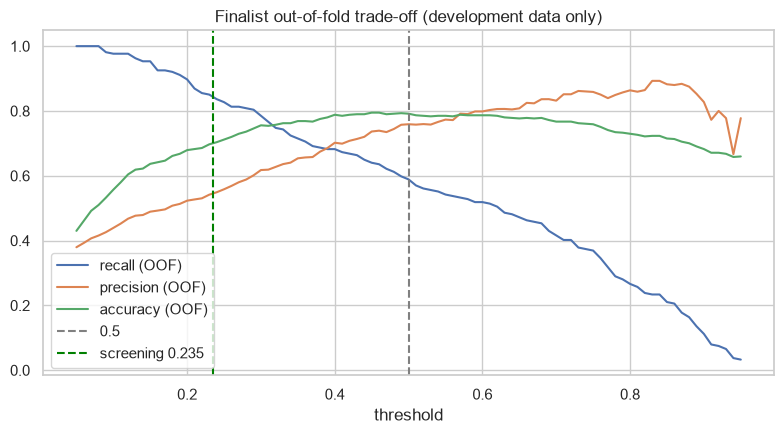

In [28]:
# Screening threshold from out-of-fold development predictions (rule fixed in Section 0).
RECALL_TARGET = 0.85
oof_p = oof_all[(FINAL_REP, FINAL_CLF)]
assert not np.isnan(oof_p).any()
cands = np.unique(oof_p)[::-1]
ok = [t for t in cands if recall_score(y_dev_np, (oof_p >= t).astype(int)) >= RECALL_TARGET]
SCREEN_T = float(max(ok))
thr_table = pd.DataFrame([{'threshold': t, **{k: v for k, v in metric_block(y_dev_np, oof_p, t).items()}}
                          for t in [0.5, 0.4, 0.35, 0.3, SCREEN_T]]).drop_duplicates('threshold')
print(f'Locked screening threshold = {SCREEN_T:.4f} (highest threshold with OOF recall >= {RECALL_TARGET})')
display(thr_table.round(4))

ts = np.linspace(0.05, 0.95, 91)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(ts, [recall_score(y_dev_np, (oof_p >= t).astype(int)) for t in ts], label='recall (OOF)')
ax.plot(ts, [precision_score(y_dev_np, (oof_p >= t).astype(int), zero_division=0) for t in ts], label='precision (OOF)')
ax.plot(ts, [accuracy_score(y_dev_np, (oof_p >= t).astype(int)) for t in ts], label='accuracy (OOF)')
ax.axvline(0.5, ls='--', color='grey', label='0.5'); ax.axvline(SCREEN_T, ls='--', color='green', label=f'screening {SCREEN_T:.3f}')
ax.set_xlabel('threshold'); ax.set_title(f'Finalist out-of-fold trade-off (development data only)'); ax.legend(); plt.tight_layout(); plt.show()

## 12. Final evaluation: the test set is opened once

The finalist is refitted on all 614 development patients. Any internal search or tuning re-runs on inner CV of those patients. It is then scored once on the 154 locked test patients.

In [29]:
ALL_FACTORIES = {**{(r, c): (ALL_REPS[r], CLASSIFIERS[c]) for r in ALL_REPS for c in CLASSIFIERS},
                 **{(RAW, c): (lambda: ColumnSubset(), TUNED[c]) for c in TUNED},
                 (HIST, 'Gradient Boosting (tuned, historical grid)'): (
                     lambda: RawSubsetSearch('ga', 'gb', penalty=0.001, precompute=True, seed=SEED, ga_kwargs={'pop_size': 16, 'n_gen': 12, 'mut_rate': 0.12}),
                     lambda: GridSearchCV(GradientBoostingClassifier(random_state=SEED), HIST_GB_GRID, scoring='roc_auc', cv=inner_cv(), n_jobs=N_JOBS))}
rep_fac, clf_fac = ALL_FACTORIES[(FINAL_REP, FINAL_CLF)]
with warnings.catch_warnings():
    warnings.simplefilter('ignore', FutureWarning)
    final_rep = rep_fac(); Z_fit = final_rep.fit_transform(X_dev, y_dev)
    final_clf = clf_fac().fit(Z_fit, y_dev)
p_dev_fit = final_clf.predict_proba(Z_fit)[:, 1]
print('Finalist refitted on 614 development patients. Selected raw columns:', selected_names(final_rep) or 'all 8')
if hasattr(final_clf, 'best_params_'):
    print('Tuned hyperparameters:', final_clf.best_params_)

X_test, y_test = TEST_VAULT.open(f'final evaluation of locked finalist {FINAL_REP} | {FINAL_CLF}, thresholds 0.5 and {SCREEN_T:.4f}')
p_test = final_clf.predict_proba(final_rep.transform(X_test))[:, 1]
y_test_np = y_test.to_numpy()

final_rows = []
for label, t in [('default 0.5', 0.5), (f'screening {SCREEN_T:.3f}', SCREEN_T)]:
    final_rows.append({'threshold': label, 'set': 'TEST (154)', **metric_block(y_test_np, p_test, t)})
    final_rows.append({'threshold': label, 'set': 'dev out-of-fold (614)', **metric_block(y_dev_np, oof_p, t)})
    final_rows.append({'threshold': label, 'set': 'dev training fit (614)', **metric_block(y_dev_np, p_dev_fit, t)})
final_table = pd.DataFrame(final_rows)
display(final_table.round(4))
final_table.to_csv(RESULTS / 'final_test_metrics.csv', index=False)

rng = np.random.default_rng(SEED); boot = []
for _ in range(2000):
    i = rng.integers(0, len(y_test_np), len(y_test_np))
    if len(np.unique(y_test_np[i])) < 2: continue
    m5, ms = metric_block(y_test_np[i], p_test[i], 0.5), metric_block(y_test_np[i], p_test[i], SCREEN_T)
    boot.append({'accuracy@0.5': m5['accuracy'], 'recall@0.5': m5['recall'], 'roc_auc': m5['roc_auc'],
                 'accuracy@screen': ms['accuracy'], 'recall@screen': ms['recall'], 'specificity@screen': ms['specificity']})
ci = pd.DataFrame(boot).quantile([0.025, 0.5, 0.975]).T
ci.columns = ['2.5%', 'median', '97.5%']
print('Test-set bootstrap 95% intervals (2000 resamples):'); display(ci.round(4))

Finalist refitted on 614 development patients. Selected raw columns: ['Pregnancies', 'Glucose', 'BMI', 'DiabetesPedigreeFunction']
TEST SET OPENED at 2026-11-23 04:41:12: final evaluation of locked finalist Selected raw: binary PSO (LR objective) | Logistic Regression, thresholds 0.5 and 0.2349


,threshold,set,accuracy,error_rate,precision,recall,specificity,f1,roc_auc,tn,fp,fn,tp
0,default 0.5,TEST (154),0.6948,0.3052,0.5745,0.5000,0.800,0.5347,0.8106,80,20,27,27
1,default 0.5,dev out-of-fold (614),0.7915,0.2085,0.7590,0.5888,0.900,0.6632,0.8467,360,40,88,126
2,default 0.5,dev training fit (614),0.7915,0.2085,0.7590,0.5888,0.900,0.6632,0.8501,360,40,88,126
3,screening 0.235,TEST (154),0.7208,0.2792,0.5647,0.8889,0.630,0.6906,0.8106,63,37,6,48
4,screening 0.235,dev out-of-fold (614),0.7003,0.2997,0.5449,0.8505,0.620,0.6642,0.8467,248,152,32,182
5,screening 0.235,dev training fit (614),0.7036,0.2964,0.5482,0.8505,0.625,0.6667,0.8501,250,150,32,182


Test-set bootstrap 95% intervals (2000 resamples):


,2.5%,median,97.5%
accuracy@0.5,0.6234,0.6948,0.7662
recall@0.5,0.3673,0.5000,0.6346
roc_auc,0.7360,0.8109,0.8712
accuracy@screen,0.6494,0.7208,0.7857
recall@screen,0.8036,0.8947,0.9677
specificity@screen,0.5300,0.6284,0.7196


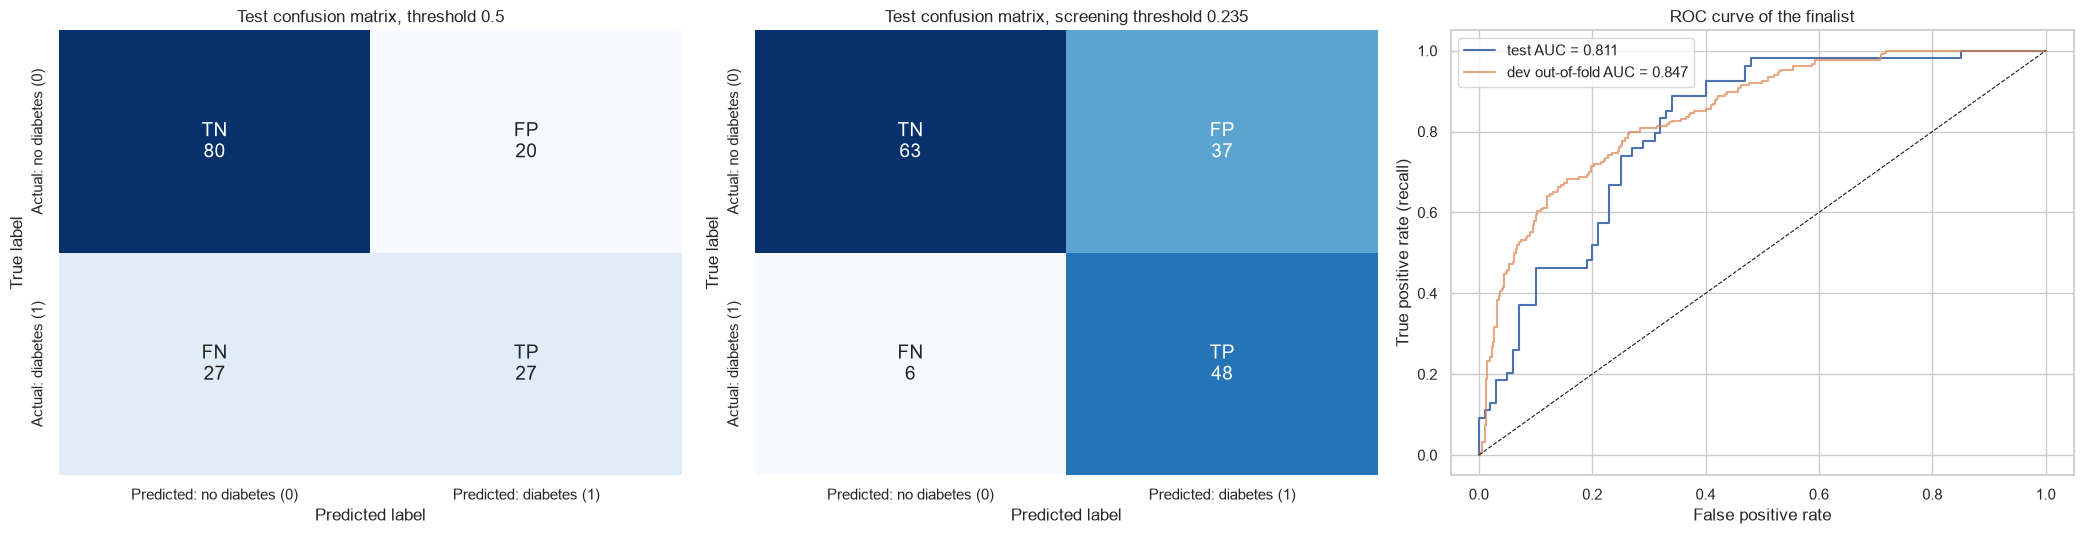

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
for ax, (label, t) in zip(axes[:2], [('threshold 0.5', 0.5), (f'screening threshold {SCREEN_T:.3f}', SCREEN_T)]):
    cm = confusion_matrix(y_test_np, (p_test >= t).astype(int), labels=[0, 1])
    sns.heatmap(cm, annot=np.array([[f'TN\n{cm[0,0]}', f'FP\n{cm[0,1]}'], [f'FN\n{cm[1,0]}', f'TP\n{cm[1,1]}']]), fmt='', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Predicted: no diabetes (0)', 'Predicted: diabetes (1)'], yticklabels=['Actual: no diabetes (0)', 'Actual: diabetes (1)'],
                annot_kws={'size': 14})
    ax.set_xlabel('Predicted label'); ax.set_ylabel('True label'); ax.set_title(f'Test confusion matrix, {label}')
fpr, tpr, _ = roc_curve(y_test_np, p_test)
fpr_o, tpr_o, _ = roc_curve(y_dev_np, oof_p)
axes[2].plot(fpr, tpr, label=f'test AUC = {roc_auc_score(y_test_np, p_test):.3f}')
axes[2].plot(fpr_o, tpr_o, alpha=0.7, label=f'dev out-of-fold AUC = {roc_auc_score(y_dev_np, oof_p):.3f}')
axes[2].plot([0, 1], [0, 1], 'k--', lw=0.8); axes[2].set_xlabel('False positive rate'); axes[2].set_ylabel('True positive rate (recall)')
axes[2].set_title('ROC curve of the finalist'); axes[2].legend()
plt.tight_layout(); plt.show()

### 12.1 Error analysis: who are the false negatives and false positives?

In [31]:
pred_s = (p_test >= SCREEN_T).astype(int); pred_d = (p_test >= 0.5).astype(int)
groups = {'TP': (y_test_np == 1) & (pred_d == 1), 'FN': (y_test_np == 1) & (pred_d == 0),
          'TN': (y_test_np == 0) & (pred_d == 0), 'FP': (y_test_np == 0) & (pred_d == 1)}
Xt = X_test.copy(); Xt[ZERO_INVALID] = Xt[ZERO_INVALID].replace(0, np.nan)
prof = pd.DataFrame({g: Xt[m].median() for g, m in groups.items()}).T
prof['n'] = [m.sum() for m in groups.values()]
prof['mean predicted prob'] = [p_test[m].mean() if m.any() else np.nan for m in groups.values()]
prof['share with >=1 missing measurement'] = [X_test[m][ZERO_INVALID].eq(0).any(axis=1).mean() if m.any() else np.nan for m in groups.values()]
print('Median raw values by outcome group at threshold 0.5 (test set; NaN = invalid zero excluded):')
display(prof.round(3))
fn_rescued = ((y_test_np == 1) & (pred_d == 0) & (pred_s == 1)).sum()
fp_added = ((y_test_np == 0) & (pred_d == 0) & (pred_s == 1)).sum()
print(f'Moving from 0.5 to the locked screening threshold {SCREEN_T:.3f}: {fn_rescued} missed diabetics are caught, '
      f'at the price of {fp_added} extra false alarms.')
print('Test FN at screening threshold (lowest predicted risk among diabetics):')
display(X_test[(y_test_np == 1) & (pred_s == 0)].assign(predicted_prob=p_test[(y_test_np == 1) & (pred_s == 0)]).sort_values('predicted_prob').round(3))

Median raw values by outcome group at threshold 0.5 (test set; NaN = invalid zero excluded):


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,n,mean predicted prob,share with >=1 missing measurement
TP,4.0,164.0,78.0,32.0,210.0,36.6,0.479,38.0,27,0.789,0.593
FN,4.0,123.0,68.0,29.0,121.0,32.0,0.296,32.0,27,0.313,0.630
TN,2.0,101.0,72.0,23.0,100.0,28.5,0.293,25.0,80,0.142,0.512
FP,5.5,153.5,77.0,35.5,269.5,37.5,0.339,31.5,20,0.692,0.500


Moving from 0.5 to the locked screening threshold 0.235: 21 missed diabetics are caught, at the price of 17 extra false alarms.
Test FN at screening threshold (lowest predicted risk among diabetics):


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,predicted_prob
6,3.0,78.0,50.0,32.0,88.0,31.0,0.248,26.0,0.048
38,2.0,90.0,68.0,42.0,0.0,38.2,0.503,27.0,0.145
124,0.0,113.0,76.0,0.0,0.0,33.3,0.278,23.0,0.146
276,7.0,106.0,60.0,24.0,0.0,26.5,0.296,29.0,0.146
419,3.0,129.0,64.0,29.0,115.0,26.4,0.219,28.0,0.190
17,7.0,107.0,74.0,0.0,0.0,29.6,0.254,31.0,0.190


### 12.2 Post-hoc diagnostic: is the gap between CV and test specific to the finalist?

The finalist and both thresholds are already locked, and nothing below can change them. To read the gap between CV and test, four reference pipelines are refitted on the development set and scored on the same test patients. If they all drop by a similar amount, the test split is simply harder (sampling variation with n = 154) rather than the finalist being overfitted.

In [32]:
posthoc = []
m = metric_block(y_test_np, p_test)
posthoc.append({'pipeline': f'FINALIST: {FINAL_REP} | {FINAL_CLF}', 'cv_auc': FINAL['cv_roc_auc_mean'], 'test_auc': m['roc_auc'],
                'cv_accuracy': FINAL['cv_accuracy_mean'], 'test_accuracy@0.5': m['accuracy'], 'test_recall@0.5': m['recall']})
for key in [(ALL8, 'Logistic Regression'), (RAW, 'SVM RBF (tuned)'), (ALL8, 'Random Forest'),
            (HIST, 'Gradient Boosting (tuned, historical grid)')]:
    rf, cf = ALL_FACTORIES[key]
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', FutureWarning)
        rp = rf(); Zf = rp.fit_transform(X_dev, y_dev); cl = cf().fit(Zf, y_dev)
    pt = cl.predict_proba(rp.transform(X_test))[:, 1]
    cvrow = lb[(lb.representation == key[0]) & (lb.classifier == key[1])].iloc[0]
    m = metric_block(y_test_np, pt)
    posthoc.append({'pipeline': f'{key[0]} | {key[1]}', 'cv_auc': cvrow.cv_roc_auc_mean, 'test_auc': m['roc_auc'],
                    'cv_accuracy': cvrow.cv_accuracy_mean, 'test_accuracy@0.5': m['accuracy'], 'test_recall@0.5': m['recall']})
posthoc = pd.DataFrame(posthoc)
posthoc['auc_drop'] = posthoc['cv_auc'] - posthoc['test_auc']
posthoc['accuracy_drop'] = posthoc['cv_accuracy'] - posthoc['test_accuracy@0.5']
print('Post-hoc diagnostic (finalist already locked; this table cannot change the choice):')
display(posthoc.round(4))
posthoc.to_csv(RESULTS / 'posthoc_test_diagnostic.csv', index=False)

Post-hoc diagnostic (finalist already locked; this table cannot change the choice):


,pipeline,cv_auc,test_auc,cv_accuracy,test_accuracy@0.5,test_recall@0.5,auc_drop,accuracy_drop
0,FINALIST: Selected raw: binary PSO (LR objective) | Logistic Regression,0.8458,0.8106,0.7915,0.6948,0.5000,0.0353,0.0967
1,All 8 original features | Logistic Regression,0.8436,0.8135,0.7882,0.7013,0.4815,0.0301,0.0869
2,Raw columns (preprocessing inside tuned pipeline) | SVM RBF (tuned),0.8440,0.8062,0.7866,0.6948,0.4815,0.0378,0.0918
3,All 8 original features | Random Forest,0.8358,0.8074,0.7671,0.7208,0.5185,0.0284,0.0463
4,"Historical replica: tree-GA subset (nested) | Gradient Boosting (tuned, hist...",0.8290,0.8133,0.7589,0.7403,0.5926,0.0156,0.0187


### 12.3 Overfitting or underfitting?

,representation,classifier,train_accuracy_mean,cv_accuracy_mean,train_roc_auc_mean,cv_roc_auc_mean,auc_gap_train_minus_cv,acc_gap
29,All 8 original features,Gaussian Naive Bayes,0.7675,0.7574,0.8383,0.8310,0.0072,0.0101
1,Raw columns (preprocessing inside tuned pipeline),Logistic Regression (tuned C),0.7891,0.7866,0.8517,0.8444,0.0074,0.0025
7,All 8 original features,Logistic Regression,0.7932,0.7882,0.8516,0.8436,0.0079,0.0049
3,Raw columns (preprocessing inside tuned pipeline),SVM RBF (tuned),0.8013,0.7866,0.8681,0.8440,0.0242,0.0147
30,All 8 original features,SVM (RBF),0.8327,0.7638,0.9049,0.8306,0.0742,0.0688
20,Raw columns (preprocessing inside tuned pipeline),Random Forest (tuned),0.8400,0.7753,0.9181,0.8372,0.0809,0.0647
89,All 8 original features,KNN (k=7),0.8139,0.7540,0.8928,0.8096,0.0832,0.0599
26,Raw columns (preprocessing inside tuned pipeline),Gradient Boosting (tuned),0.8367,0.7703,0.9224,0.8342,0.0881,0.0664
131,All 8 original features,Decision Tree (depth 5),0.8518,0.7525,0.9205,0.7872,0.1333,0.0993
24,All 8 original features,Random Forest,0.9129,0.7671,0.9769,0.8358,0.1411,0.1458


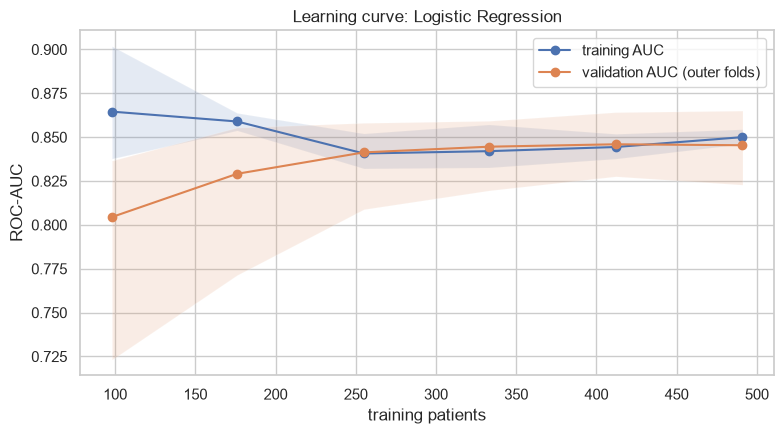

Learning curve (mean AUC): train [0.8646 0.8589 0.8407 0.842  0.8444 0.85  ] | validation [0.8045 0.8291 0.8413 0.8446 0.8459 0.8454]
Finalist AUC: training fit 0.8501 | dev out-of-fold 0.8467 | test 0.8106


In [33]:
ov = lb[lb.representation.isin([ALL8, RAW])][['representation', 'classifier', 'train_accuracy_mean', 'cv_accuracy_mean', 'train_roc_auc_mean', 'cv_roc_auc_mean', 'auc_gap_train_minus_cv']]
ov = ov.assign(acc_gap=ov.train_accuracy_mean - ov.cv_accuracy_mean).sort_values('auc_gap_train_minus_cv')
display(ov.round(4))

fixed_cols = selected_names(final_rep) or FEATURES
lc_rep = (lambda: make_preprocessor(fixed_cols)) if hasattr(final_rep, 'subset_') else rep_fac
lc_pipe = Pipeline([('rep', lc_rep()), ('clf', clf_fac())])
with warnings.catch_warnings():
    warnings.simplefilter('ignore', FutureWarning)
    sizes, tr_sc, va_sc = learning_curve(lc_pipe, X_dev, y_dev, cv=OUTER_FOLDS, scoring='roc_auc', train_sizes=np.linspace(0.2, 1.0, 6), n_jobs=1)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(sizes, tr_sc.mean(1), 'o-', label='training AUC'); ax.fill_between(sizes, tr_sc.min(1), tr_sc.max(1), alpha=0.15)
ax.plot(sizes, va_sc.mean(1), 'o-', label='validation AUC (outer folds)'); ax.fill_between(sizes, va_sc.min(1), va_sc.max(1), alpha=0.15)
ax.set_xlabel('training patients'); ax.set_ylabel('ROC-AUC'); ax.set_title(f'Learning curve: {FINAL_CLF}'); ax.legend(); plt.tight_layout(); plt.show()
print('Learning curve (mean AUC): train', np.round(tr_sc.mean(1), 4), '| validation', np.round(va_sc.mean(1), 4))
t5 = final_table.set_index(['threshold', 'set'])
print(f"Finalist AUC: training fit {t5.loc[('default 0.5', 'dev training fit (614)'), 'roc_auc']:.4f} | "
      f"dev out-of-fold {t5.loc[('default 0.5', 'dev out-of-fold (614)'), 'roc_auc']:.4f} | test {t5.loc[('default 0.5', 'TEST (154)'), 'roc_auc']:.4f}")

### 12.4 Interpretation

*The conclusions below were written from the executed run, using the numbers printed above. If the notebook is re-run on different library versions, the printed values take precedence.*

**Locked finalist.** Logistic regression on 4 raw measurements: **Pregnancies, Glucose, BMI, DiabetesPedigreeFunction**. Binary PSO selected them inside each training fold, and refitted on the full development set it chose the same 4 columns, which are also the exhaustive optimum. The finalist needs **no insulin or skin-fold measurement**.

| | Mean 5-fold CV (dev, 614) | Locked test (154), threshold 0.5 | Locked test, screening threshold 0.235 |
|---|---|---|---|
| Confusion matrix [TN FP; FN TP] | OOF: [360 40; 88 126] | [80 20; 27 27] | [63 37; 6 48] |
| Accuracy / error rate | 0.792 ± 0.019 / 0.208 | 0.695 / 0.305 (95% CI 0.62–0.77) | 0.721 / 0.279 |
| Precision | 0.759 | 0.574 | 0.565 |
| Recall (sensitivity) | 0.589 | 0.500 | **0.889** (95% CI 0.80–0.97) |
| Specificity | 0.900 | 0.800 | 0.630 |
| F1 | 0.663 | 0.535 | 0.691 |
| ROC-AUC | 0.846 ± 0.015 | **0.811** (95% CI 0.736–0.871) | 0.811 |

**Confusion matrix interpretation.**

* **False negatives** are the clinically costly error. At 0.5 the model misses half of the test diabetics (27 of 54). Their measurements look like non-diabetics': median glucose 123 versus 164 for the true positives, lower BMI (32.0 vs 36.6) and younger age (32 vs 38). This is the class overlap seen in every embedding in Section 5, not a coding error.
* **The pre-specified screening threshold** (0.235, chosen from out-of-fold development predictions) catches 21 of those 27 at the cost of 17 extra false alarms. The 6 diabetics still missed have glucose 78–129, and 4 of the 6 lack insulin and/or skin-fold values. With these measurements they are practically indistinguishable from healthy patients.
* **False positives** have high glucose (median 153.5) and BMI (37.5), i.e. a diabetic-looking profile. In screening they cost a confirmatory glucose test, which is cheaper than a missed diagnosis. Some may be early or undiagnosed cases, but the data cannot confirm that.

**Over- or underfitting?** The finalist is **not overfitted**: training AUC is 0.850 and out-of-fold AUC is 0.847. Its learning curve flattens: validation AUC is 0.841 with about 255 training patients and 0.845 with 491 (one full outer training fold), while training AUC falls to meet it. This is a high-bias regime. The model is limited by how much information the measurements carry, not by variance, so more flexible models do not help. The flexible default models do overfit. Gradient boosting reaches 0.982 training AUC but 0.820 CV AUC, and random forest 0.977 vs 0.836. Nested tuning narrows these gaps (tuned GB 0.922 vs 0.834) without beating logistic regression.

**The test score is lower than CV, and the reason is the split.** The post-hoc diagnostic (§12.2) refitted four other locked pipelines; all lose 0.016–0.038 AUC and up to 9 accuracy points on these 154 patients. The finalist's drop (0.035 AUC) is typical, and the test AUC sits inside its bootstrap interval. The historical GB replica happens to score best on this test split (accuracy 0.740). Choosing it now would be selection on the test set, and its nested CV estimate is lower (AUC 0.829).

**Pipeline to present.** The locked finalist with the screening threshold. The evidence:

1. It has the best mean outer-CV AUC under a rule fixed in advance.
2. It is statistically tied with logistic regression on all 8 features. 18 pipelines fall within one standard error of the top.
3. It needs half the measurements, and the dropped ones (insulin, skin fold, blood pressure, age) are the ones most often missing.
4. It is not overfitted, and its threshold was set without the test set.

Present it as "about 0.81–0.85 AUC with 4 routine measurements", not as a breakthrough over the all-features baseline.

## 13. Comparison with related work on the same dataset

Each row was checked against the primary source or the dataset documentation on 2026-11-23. Published scores **cannot be compared directly** with this notebook. The studies use different patient subsets (768 vs 392 complete cases), different missing-value handling, single splits versus CV, and usually do not report whether tuning was nested. The "limits" column states the gap for each one.

| Study | Data used | Method | Reported result | Evaluation protocol | Limits on direct comparison |
|---|---|---|---|---|---|
| Smith et al., 1988 (ADAP), as documented in the UCI `pima.info` file and the PMC abstract (PMC2245318) | 768 Pima women | ADAP adaptive learning (early neural network) | Sensitivity = specificity = 0.76 at cutoff 0.448 | 576 training / 192 test instances | One split; no AUC; threshold set where sensitivity equals specificity; full paper body not machine-readable (scanned) |
| Zou et al., 2018, *Front. Genet.* 9:515 (PMC6232260) | Pima 392 complete cases (secondary dataset; main dataset is Luzhou hospital) | J48, random forest, neural network; PCA and mRMR reduction | RF + mRMR (glucose, insulin, age): ACC 0.7721 (5-fold CV); 0.7852 in their 10-fold comparison table | 5-fold CV (10-fold in Table 8) | Drops patients with missing data (an easier and different population); accuracy only |
| Chang et al., *Neural Comput. Appl.* (online 2022), doi:10.1007/s00521-022-07049-z (PMC8943493) | 768 rows, median imputation of invalid zeros, no scaling | Naive Bayes, random forest, J48 in R | RF all features: accuracy 79.57%, AUC 86.24%; NB on glucose/BMI/age: 79.13% | One 70/30 split (538 / 230), no CV | Single split; several RF metrics do not follow from the paper's own confusion matrices; imputation applied before the split |
| Hasan et al., 2020, *IEEE Access* 8:76516 (abstract via Semantic Scholar) | Pima | Outlier rejection, imputation, standardisation, feature selection; AUC-weighted ensemble of k-NN, DT, RF, AdaBoost, NB, XGBoost, MLP | Ensemble AUC 0.950, sensitivity 0.789, specificity 0.934 | K-fold CV with grid search (fold count and nesting not verifiable: full text unavailable to this audit) | Only the abstract was verified; outlier rejection changes the patient set; unclear whether tuning was nested |
| **This notebook** | 768 verified raw patients; 154 locked test | See Sections 3–12 | See Section 12 (test) and Section 11 (CV) | Locked stratified 20% test; identical 5-fold outer CV; nested inner CV for every tuning or search step | n/a |

The historical documentation also cited a leakage survey (Kapoor & Narayanan, 2023, *Patterns*). It is not a Pima study and was not re-verified in this audit, so it is left out of the table.

In [34]:
rw = pd.DataFrame([
    ('Smith et al. 1988 (ADAP)', '192-patient test split', 'sens = spec = 0.76', np.nan, np.nan),
    ('Zou et al. 2018 (RF + mRMR)', '5-fold CV, 392 complete cases', 'accuracy', 0.7721, np.nan),
    ('Chang et al. 2022 (RF, all features)', '230-patient test split', 'accuracy / AUC', 0.7957, 0.8624),
    ('Hasan et al. 2020 (weighted ensemble)', 'K-fold CV (abstract)', 'AUC', np.nan, 0.950),
], columns=['study', 'protocol', 'reported', 'accuracy', 'roc_auc'])
t = final_table.set_index(['threshold', 'set'])
rw.loc[len(rw)] = ['This notebook: finalist, dev 5-fold CV', 'outer 5-fold CV, 614', 'mean accuracy / AUC', FINAL['cv_accuracy_mean'], FINAL['cv_roc_auc_mean']]
rw.loc[len(rw)] = ['This notebook: finalist, locked test @0.5', '154 locked test patients', 'accuracy / AUC',
                   t.loc[('default 0.5', 'TEST (154)'), 'accuracy'], t.loc[('default 0.5', 'TEST (154)'), 'roc_auc']]
display(rw.round(4))

,study,protocol,reported,accuracy,roc_auc
0,Smith et al. 1988 (ADAP),192-patient test split,sens = spec = 0.76,NaN,NaN
1,Zou et al. 2018 (RF + mRMR),"5-fold CV, 392 complete cases",accuracy,0.7721,NaN
2,"Chang et al. 2022 (RF, all features)",230-patient test split,accuracy / AUC,0.7957,0.8624
3,Hasan et al. 2020 (weighted ensemble),K-fold CV (abstract),AUC,NaN,0.9500
4,"This notebook: finalist, dev 5-fold CV","outer 5-fold CV, 614",mean accuracy / AUC,0.7915,0.8458
5,"This notebook: finalist, locked test @0.5",154 locked test patients,accuracy / AUC,0.6948,0.8106


## 14. Reconciliation with the historical notebook and documentation

In [35]:
best_all8_lr = lb[(lb.representation == ALL8) & (lb.classifier == 'Logistic Regression')].iloc[0]
hist_rep = lb[lb.representation == HIST].iloc[0]
recon = pd.DataFrame([
    ('Rows modelled', '1,144 (two copies of 768 patients, de-duplicated)', '768 verified raw patients'),
    ('Test set', '229 rows, most with a copy of the same patient in training', f'{N_TEST} patients, locked, opened once'),
    ('Insulin values', 'clean copy filled with class medians (label leak)', 'invalid zeros -> NaN -> KNN imputation in-fold'),
    ('Model / threshold selection', 'ranked on test ROC-AUC; 0.35 read off a test-set table', 'mean outer-CV ROC-AUC; threshold from OOF predictions'),
    ('Best accuracy', '0.878 (GB on tree-GA subset, test)', f"{t.loc[('default 0.5', 'TEST (154)'), 'accuracy']:.3f} test / {FINAL['cv_accuracy_mean']:.3f} CV (finalist)"),
    ('Best ROC-AUC', '0.942-0.943 (test)', f"{t.loc[('default 0.5', 'TEST (154)'), 'roc_auc']:.3f} test / {FINAL['cv_roc_auc_mean']:.3f} CV (finalist)"),
    ('Screening threshold', '0.35 (recall 0.938 on test)', f"{SCREEN_T:.3f} (OOF recall >= {RECALL_TARGET}); test recall {t.loc[(f'screening {SCREEN_T:.3f}', 'TEST (154)'), 'recall']:.3f}"),
    ('Historical pipeline re-estimated honestly', 'tree-GA subset + tuned GB: acc 0.865-0.878, AUC 0.942', f"nested CV: acc {hist_rep.cv_accuracy_mean:.3f}, AUC {hist_rep.cv_roc_auc_mean:.3f}"),
    ('Logistic regression, all 8 features', 'AUC ~0.85 (test, leaked data)', f"CV acc {best_all8_lr.cv_accuracy_mean:.3f}, AUC {best_all8_lr.cv_roc_auc_mean:.3f}"),
    ('Exhaustive best subset (LR)', 'all except BloodPressure and Age (post-imputation, AUC 0.8577)', f"{', '.join(obj_ex.cols(OPT_LR_MASK))} (raw, penalised objective)"),
], columns=['item', 'historical (archive/phase1_original_2026-11-23.ipynb)', 'this run'])
display(recon)
recon.to_csv(RESULTS / 'reconciliation.csv', index=False)
print(f'Total notebook runtime so far: {(time.perf_counter() - NOTEBOOK_T0) / 60:.1f} min')

,item,historical (archive/phase1_original_2026-11-23.ipynb),this run
0,Rows modelled,"1,144 (two copies of 768 patients, de-duplicated)",768 verified raw patients
1,Test set,"229 rows, most with a copy of the same patient in training","154 patients, locked, opened once"
2,Insulin values,clean copy filled with class medians (label leak),invalid zeros -> NaN -> KNN imputation in-fold
3,Model / threshold selection,ranked on test ROC-AUC; 0.35 read off a test-set table,mean outer-CV ROC-AUC; threshold from OOF predictions
4,Best accuracy,"0.878 (GB on tree-GA subset, test)",0.695 test / 0.791 CV (finalist)
5,Best ROC-AUC,0.942-0.943 (test),0.811 test / 0.846 CV (finalist)
6,Screening threshold,0.35 (recall 0.938 on test),0.235 (OOF recall >= 0.85); test recall 0.889
7,Historical pipeline re-estimated honestly,"tree-GA subset + tuned GB: acc 0.865-0.878, AUC 0.942","nested CV: acc 0.759, AUC 0.829"
8,"Logistic regression, all 8 features","AUC ~0.85 (test, leaked data)","CV acc 0.788, AUC 0.844"
9,Exhaustive best subset (LR),"all except BloodPressure and Age (post-imputation, AUC 0.8577)","Pregnancies, Glucose, BMI, DiabetesPedigreeFunction (raw, penalised objective)"


Total notebook runtime so far: 9.4 min


## 15. Rubric checklist (AID427 Phase 1 cover sheet)

| Rubric item | Where |
|---|---|
| Problem introduction | §0 |
| Data set description (difficult, noisy) | §1.1 provenance, §1.2 version and leakage audit, §1.3 class balance, invalid zeros and missingness |
| Visualization before/after **reduction** and **clustering**; data analysis and preprocessing | §1.3, §2.4 (before/after preprocessing), §4 and §5.2 plots, §6 (raw vs PCA vs clusters) |
| Linear reduction: PCA, LDA, SVD | §4 (inspection), §9 (in-fold prediction) |
| Non-linear reduction: Kernel PCA, SNE, t-SNE, UMAP, metric and non-metric MDS, Isomap, LLE | §5.1 (SNE verification), §5.2 (trustworthiness, runtime, plots), §9 (prediction for methods with out-of-sample transform) |
| Filter methods | §7 (mutual information, ANOVA F), §9 |
| Wrapper methods (forward, backward, …) | §7 (forward SFS, backward SFS, RFECV), §9 |
| Embedded methods (L1, L2, Elastic Net) | §7 (selection rules + coefficient plot), §9 |
| GA and other metaheuristics | §8 (GA, binary PSO, random search, exhaustive optimum; 10 seeds; convergence), §9 (nested) |
| Model implementations | §3 (7 classifiers), §10 (nested tuning) |
| 80/20 split and all evaluation metrics | §2.1 (locked split), §12 (confusion matrix, accuracy, error rate, precision, recall, F1, ROC-AUC) |
| K-fold cross-validation and average accuracy | §3 (per-fold + mean accuracy), §9–§11 (mean ± SD for every pipeline) |
| Interpret confusion matrix, over/underfitting, comparisons | §12.1 (FN/FP), §12.2 (test-gap diagnostic), §12.3 (over/underfitting), §12.4, §9 |
| Related work table | §13 |